# Topic 3 — Physics-Informed Inversion of Kick Transients for Near-Wellbore Permeability and Pressure
### Complete research code, A–Z

This notebook holds the code behind every number and figure in the final paper. The data are the public Pason drilling log of Utah FORGE geothermal test well 58-32 (Podgorney, McLennan and Moore, 2018, doi:10.15121/1495411, CC BY 4.0), saved as `field_data.csv` next to this notebook. Each module is written to the working folder with `%%writefile` and then run, so the code you read is the code that runs.

**Run modes.** The full study (120 scenarios × 5 observation designs with profile likelihoods, 132 robustness cases, MCMC on 4 scenarios and the physics-informed network on 8 scenarios × 8 starts × 2 designs) takes roughly 6–8 hours on two cores. With `FULL = False` (the default) the notebook

* rebuilds the cleaned record, the noise libraries and all 120 scenarios from scratch and checks them against the stored set;
* verifies both forward models;
* re-runs Routes 1 and 2 completely for `N_CHECK` scenarios and compares them, interval by interval, with the stored batch;
* runs a short MCMC chain, one physics-informed pre-training and inversion, and one robustness case as live demonstrations;
* draws every figure and computes every quoted number from the stored batch results (`REF`).

With `FULL = True` every batch is re-run here and nothing is read from `REF`.

**Paths.** `DATA` is the raw well file; `W` is the working folder; `REF` is the folder holding the stored batch results (`stored_results/` in this repository).

## A. Setup

In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {'bbox_inches':'tight','dpi':70}
import os, sys, json, glob, shutil, pickle, time, subprocess
import numpy as np, pandas as pd
from IPython.display import Image, display
DATA = os.environ.get('T3_DATA', os.path.abspath('field_data.csv') if os.path.exists('field_data.csv')
                      else '/mnt/user-data/outputs/field_data.csv')    # raw well record (7,311 rows); keep it next to this notebook
REF  = os.path.abspath('stored_results') + '/' if os.path.isdir('stored_results') else '/mnt/user-data/outputs/topic3_checkpoint/'                            # stored batch results
W    = os.path.abspath('./topic3_work') + '/'                                  # working folder
FULL = False                                                                   # True: re-run every batch here
N_CHECK = 3                                                                    # scenarios re-inverted live when FULL is False
os.makedirs(W + 'figs', exist_ok=True); os.chdir(W); sys.path.insert(0, W)
os.environ['T3_DIR'] = W; os.environ['T3_DATA'] = DATA; os.environ['T3_EXPORT'] = W
print('working folder:', W, '| stored results available:', os.path.isdir(REF + 'classical'))

working folder: /mnt/attach/outputs/topic3_checkpoint/nb_run/topic3_work/ | stored results available: True


## B. Data cleaning and the circulating record (paper §3.1, Table 1)

The cleaning is the one used in Topics 1 and 2: the dead wellhead-pressure placeholder (about −1,230 psi) is masked, the rows with flow in above 50 gpm are taken as circulating, and the duration of each row is reconstructed from the depth increment and the one-minute rate of penetration (floored at 5 ft/hr). The record is indexed by depth, so this reconstructed clock is the only time base available.

In [2]:
%%writefile t3data.py
import os, numpy as np, pandas as pd
raw = pd.read_csv(os.environ.get('T3_DATA', 'field_data.csv'))
raw = raw.reset_index(drop=False).rename(columns={'index':'row_id'})
df = raw.drop(columns=['Unnamed: 17','Unnamed: 18','Unnamed: 19','Unnamed: 20','Unnamed: 21','Unnamed: 22'])
df = df.rename(columns={'ROP(1 ft)':'ROP_1ft','WOB (k-lbs)':'WOB','Temp Out( degF)':'TempOut','Temp In(degF)':'TempIn',
    'Pit Total (bbls)':'PitTotal','Pump Press (psi)':'PumpPress','ROP(1 min)':'ROP_1min','Hookload (k-lbs)':'Hookload',
    'Surface Torque (psi)':'Torque','Rotary Speed (rpm)':'RPM','Flow In (gpm)':'FlowIn','Flow Out %':'FlowOutPct',
    'WH Pressure (psi)':'WHPressure','H2S Floor':'H2S_Floor','H2S Cellar':'H2S_Cellar','H2S Pits':'H2S_Pits'})
df['WHPressure_valid'] = df['WHPressure'] > -500
df.loc[~df['WHPressure_valid'], 'WHPressure'] = np.nan
df['ROP_1ft_winsorized'] = df['ROP_1ft'].clip(upper=df['ROP_1ft'].quantile(0.995))
df['FlowIn_winsorized'] = df['FlowIn'].clip(upper=df['FlowIn'].quantile(0.999))
df['is_circulating'] = df['FlowIn'] > 50
df['depth_block'] = pd.cut(df['Depth'], bins=10, labels=range(1,11)).astype(int)
circ = df[df['is_circulating']].copy().sort_values('Depth').reset_index(drop=True)
circ['pit_change'] = circ['PitTotal'].diff().fillna(0.0)
circ['flowout_dev'] = circ['FlowOutPct'] - 100.0
rop_safe = circ['ROP_1min'].clip(lower=5.0)
circ['dt_hr'] = (circ['Depth'].diff().clip(lower=0).fillna(0.0)) / rop_safe
circ['t_cum_hr'] = circ['dt_hr'].cumsum()

Writing t3data.py


In [3]:
from t3data import df, circ
dtm = circ['dt_hr']*60; deep = circ['Depth'] > 4750
print(f"records {len(df)}, circulating {len(circ)}, depth {df.Depth.min():.0f}-{df.Depth.max():.0f} ft")
print(f"row duration median {dtm[dtm>0].median():.1f} min (IQR {dtm[dtm>0].quantile(.25):.1f}-{dtm[dtm>0].quantile(.75):.1f}); "
      f"below 4,750 ft {dtm[deep&(dtm>0)].median():.1f} ({dtm[deep&(dtm>0)].quantile(.25):.1f}-{dtm[deep&(dtm>0)].quantile(.75):.1f}) min")
print(f"ROP below 4,750 ft, median {circ.loc[deep,'ROP_1min'].median():.1f} ft/hr; flow-out vs flow-in correlation {circ['FlowOutPct'].corr(circ['FlowIn']):.2f}")

records 7311, circulating 7241, depth 85-7536 ft
row duration median 3.4 min (IQR 1.5-5.6); below 4,750 ft 5.7 (4.4-7.5) min
ROP below 4,750 ft, median 10.6 ft/hr; flow-out vs flow-in correlation 0.11


## C. Forward models (paper §4.1–4.4, §5.1)

`forward.py` holds the Laplace-space constant-pressure solution (equation 5), inverted with the Stehfest algorithm. `sim.py` is the implicit finite-volume simulator used for every inversion: a logarithmic radial grid per layer, constant bottomhole pressure with skin while circulating, the annular-friction drop and wellbore storage after shut-in (equation 4), and any number of layers opening at different times (drilling ahead, equation 6). Synthetic truths use the same simulator on a 160-cell grid with denser time steps.

In [4]:
%%writefile forward.py
# Forward models for a liquid influx from an infinite-acting radial zone into the wellbore (field units).
#   Drawdown with pumps on: constant bottomhole pressure p_w = p_p - dp  (inner boundary, with skin S).
#   Shut-in: wellbore storage C dp_w/dt = q_sf/24 (t in hr, q_sf in bbl/d).
# (1) semi-analytical constant-pressure solution (van Everdingen & Hurst; Laplace space, Stehfest inversion)
# (2) implicit finite-volume radial simulator on a logarithmic grid that handles drawdown followed by shut-in.
import numpy as np
from math import factorial
from scipy.special import k0, k1
from scipy.linalg import solve_banded
A_T = 0.0002637   # t_D = A_T k t / (phi mu ct rw^2), t in hours
A_Q = 141.2       # q[bbl/d] = k h dp / (A_Q B mu) * q_D

def stehfest_V(N=12):
    V = np.zeros(N)
    for i in range(1, N+1):
        s = 0.0
        for k in range((i+1)//2, min(i, N//2)+1):
            s += k**(N//2)*factorial(2*k)/(factorial(N//2-k)*factorial(k)*factorial(k-1)*factorial(i-k)*factorial(2*k-i))
        V[i-1] = (-1)**(N//2+i)*s
    return V
_V = stehfest_V(12)

def qD_lap(s, S):            # dimensionless rate, constant wellbore pressure, finite wellbore with skin
    rs = np.sqrt(s); return k1(rs)/(rs*(k0(rs)+S*rs*k1(rs)))
def QD(tD, S=0.0):          # dimensionless cumulative influx (van Everdingen-Hurst W_D for r_eD -> inf)
    tD = np.atleast_1d(tD).astype(float); out = np.zeros_like(tD); ln2 = np.log(2.0)
    for j, t in enumerate(tD):
        a = ln2/t; s = a*np.arange(1, 13); out[j] = a*np.sum(_V*qD_lap(s, S)/s)
    return out
def qD(tD, S=0.0):
    tD = np.atleast_1d(tD).astype(float); out = np.zeros_like(tD); ln2 = np.log(2.0)
    for j, t in enumerate(tD):
        a = ln2/t; s = a*np.arange(1, 13); out[j] = a*np.sum(_V*qD_lap(s, S))
    return out

def influx_analytic(t_hr, k, dp, h, S=0.0, phi=0.2, mu=1.0, ct=1e-5, rw=0.354, B=1.0):
    """Cumulative influx V (bbl) and rate q (bbl/min) at times t_hr for constant underbalance dp (psi)."""
    tD = A_T*k*np.asarray(t_hr)/(phi*mu*ct*rw**2)
    V = 1.119*phi*ct*h*rw**2*dp*QD(tD, S)/B
    q = k*h*dp/(A_Q*B*mu)*qD(tD, S)/1440.0
    return V, q

class RadialSim:
    """Implicit finite-volume simulator, log grid from rw to re. Time in hours, rates in bbl/d internally."""
    def __init__(self, k, h, phi=0.2, mu=1.0, ct=1e-5, rw=0.354, re=5000.0, N=150, B=1.0, S=0.0):
        rb = np.geomspace(rw, re, N+1); self.rc = np.sqrt(rb[:-1]*rb[1:])
        self.Vp = np.pi*(rb[1:]**2-rb[:-1]**2)*h*phi/5.615           # bbl
        self.acc = self.Vp*ct                                          # bbl/psi
        self.T = 2*np.pi*0.001127*k*h/(mu*B*np.log(self.rc[1:]/self.rc[:-1]))   # bbl/d/psi between cells
        self.J = 2*np.pi*0.001127*k*h/(mu*B*(np.log(self.rc[0]/rw)+S))          # bbl/d/psi, cell 0 to wellbore
        self.N = N
    def run(self, p_init, dp_dd, t_shut, t_end, C, dp_af=0.0, dt_min=1/3600, n_steps=400, t_eval=None):
        """Drawdown at p_w = p_init - dp_dd until t_shut (h); then shut in with storage C (bbl/psi) to t_end.
        Returns times (h), wellbore pressure p_w (psi), sandface rate (bbl/min), cumulative surface gain (bbl)."""
        N = self.N; p = np.full(N, float(p_init)); pw = p_init - dp_dd; switched = False
        t_dd = np.r_[0, np.geomspace(dt_min, t_shut, n_steps)]
        t_bu = t_shut + np.r_[np.geomspace(dt_min, t_end-t_shut, n_steps)] if t_end > t_shut else np.array([])
        times = np.r_[t_dd, t_bu]; out_pw = [pw]; out_q = [0.0]; Vs = [0.0]; Vcum = 0.0
        for n in range(1, len(times)):
            dt = (times[n]-times[n-1])/24.0                              # days
            shut = times[n] > t_shut + 1e-12
            if shut and not switched: pw = pw - dp_af; switched = True     # pumps off: annular friction lost
            M = N + 1                                                     # unknowns: p_0..p_{N-1}, p_w
            ab = np.zeros((3, M)); rhs = np.zeros(M)
            for i in range(N):
                diag = self.acc[i]/dt; rhs[i] = self.acc[i]/dt*p[i]
                if i > 0:   diag += self.T[i-1]; ab[2, i-1] = -self.T[i-1]          # sub-diagonal (row i, col i-1)
                if i < N-1: diag += self.T[i];   ab[0, i+1] = -self.T[i]            # super-diagonal (row i, col i+1)
                ab[1, i] = diag
            # outer boundary: closed but far (infinite-acting over the test)
            # well coupling: cell 0 <-> wellbore node (index N)  -- reorder: put wellbore before cell 0 to keep banded
            # simpler: eliminate p_w analytically
            if not shut:
                ab[1, 0] += self.J; rhs[0] += self.J*pw
                pv = solve_banded((1, 1), ab[:, :N], rhs[:N]); q = self.J*(pv[0]-pw)
            else:
                Cd = C/dt                                                   # bbl/psi/day
                # C (pw_new - pw_old)/dt = J (p0 - pw_new)  ->  pw_new = (Cd pw_old + J p0)/(Cd + J)
                a = self.J*Cd/(Cd+self.J)                                   # effective coupling to cell 0
                ab[1, 0] += a; rhs[0] += a*pw
                pv = solve_banded((1, 1), ab[:, :N], rhs[:N]); pw = (Cd*pw + self.J*pv[0])/(Cd+self.J); q = self.J*(pv[0]-pw)
            p = pv
            if not shut: Vcum += q*dt                                       # surface pit gain only while flowing
            out_pw.append(pw); out_q.append(q/1440.0); Vs.append(Vcum)
        return times, np.array(out_pw), np.array(out_q), np.array(Vs)

Writing forward.py


In [5]:
%%writefile sim.py
# Fast implicit finite-volume simulator for liquid influx from one or more layers into a well (field units).
# Drawdown variable u = p_p - p (psi). Each layer j (thickness h_j, opened at t_open_j) has its own radial grid.
#   pumps on  (t < t_s): wellbore held at u_w = dp (constant bottomhole pressure, skin S)
#   shut in   (t >= t_s): u_w jumps to dp + dp_af (pumps off), then storage: -C du_w/dt = sum_j q_j
# Returns cumulative surface gain V(t) [bbl] (frozen after shut-in) and the shut-in pressure rise
#   y(t) = (dp + dp_af) - u_w(t) [psi]  (0 at shut-in, rising towards dp + dp_af).
import numpy as np
from numba import njit

RW = 0.354           # ft, 8-1/2-in bit (absorbed into skin, see paper Section 5.5)
RE = 12000.0         # ft, outer radius (beyond the radius of investigation in every scenario)
NR = 60              # radial cells per layer

def grid(nr=NR, rw=RW, re=RE):
    rb = np.geomspace(rw, re, nr+1); rc = np.sqrt(rb[:-1]*rb[1:])
    area = np.pi*(rb[1:]**2 - rb[:-1]**2)          # ft2 per ft of thickness
    geo_T = 2*np.pi*0.001127/np.log(rc[1:]/rc[:-1])  # times k h / (mu B)  -> bbl/d/psi
    geo_J = 2*np.pi*0.001127/np.log(rc[0]/rw)        # skin added in the denominator later
    return rc, area, geo_T, geo_J, np.log(rc[0]/rw)
RC, AREA, GEO_T, GEO_J, LN0 = grid()
RCf, AREAf, GEO_Tf, GEO_Jf, LN0f = grid(nr=160)   # fine grid used only to generate synthetic data (avoids the 'inverse crime')

def time_grid(t_open, t_s, t_end, n_first=70, n_other=22, n_shut=110, tmin=2e-5):
    pts = [np.array([0.0])]
    for i, to in enumerate(t_open):
        if to >= t_s: continue
        n = n_first if i == 0 else n_other
        pts.append(to + np.geomspace(tmin, t_s - to, n))
        pts.append(np.array([to]))
    if t_end > t_s: pts.append(t_s + np.geomspace(tmin, t_end - t_s, n_shut))
    t = np.unique(np.concatenate(pts)); return t[t <= t_end + 1e-12]

@njit(cache=True)
def _thomas(a, b, c, d, n):
    cp = np.empty(n); dp = np.empty(n); x = np.empty(n)
    cp[0] = c[0]/b[0]; dp[0] = d[0]/b[0]
    for i in range(1, n):
        m = b[i] - a[i]*cp[i-1]; cp[i] = c[i]/m; dp[i] = (d[i] - a[i]*dp[i-1])/m
    x[n-1] = dp[n-1]
    for i in range(n-2, -1, -1): x[i] = dp[i] - cp[i]*x[i+1]
    return x

@njit(cache=True)
def simulate(k, phict, mu, Sarr, dp, dpaf, C, h, t_open, t_s, tgrid, area, geo_T, geo_J_ln0, ln0):
    nl = h.shape[0]; n = area.shape[0]; nt = tgrid.shape[0]
    u = np.zeros((nl, n)); V = np.zeros(nt); Y = np.zeros(nt)
    a = np.empty(n); b = np.empty(n); c = np.empty(n); d = np.empty(n)
    Vc = 0.0; uw = dp; shut = False
    for it in range(1, nt):
        t = tgrid[it]; dtd = (t - tgrid[it-1])/24.0; S = Sarr[it]
        if t > t_s + 1e-12 and not shut:
            shut = True; uw = dp + dpaf
        if not shut:
            qsum = 0.0
            for j in range(nl):
                if t_open[j] >= t - 1e-12: continue
                T = geo_T*k*h[j]/mu; acc = area*h[j]*phict/5.615; J = geo_J_ln0*k*h[j]/(mu*(ln0 + S))
                for i in range(n):
                    a[i] = 0.0; c[i] = 0.0; b[i] = acc[i]/dtd; d[i] = acc[i]/dtd*u[j, i]
                    if i > 0: a[i] = -T[i-1]; b[i] += T[i-1]
                    if i < n-1: c[i] = -T[i]; b[i] += T[i]
                b[0] += J; d[0] += J*uw
                x = _thomas(a, b, c, d, n)
                for i in range(n): u[j, i] = x[i]
                qsum += J*(uw - x[0])
            Vc += qsum*dtd
        else:
            num = C/dtd*uw; den = C/dtd
            X = np.zeros((nl, n)); Yv = np.zeros((nl, n)); act = np.zeros(nl)
            for j in range(nl):
                if t_open[j] >= t_s - 1e-12: continue
                act[j] = 1.0
                T = geo_T*k*h[j]/mu; acc = area*h[j]*phict/5.615; J = geo_J_ln0*k*h[j]/(mu*(ln0 + S))
                for i in range(n):
                    a[i] = 0.0; c[i] = 0.0; b[i] = acc[i]/dtd; d[i] = acc[i]/dtd*u[j, i]
                    if i > 0: a[i] = -T[i-1]; b[i] += T[i-1]
                    if i < n-1: c[i] = -T[i]; b[i] += T[i]
                b[0] += J
                x = _thomas(a, b, c, d, n)
                e = np.zeros(n); e[0] = J
                y = _thomas(a, b, c, e, n)
                for i in range(n): X[j, i] = x[i]; Yv[j, i] = y[i]
                num += J*x[0]; den += J*(1.0 - y[0])
            uw = num/den
            for j in range(nl):
                if act[j] == 1.0:
                    for i in range(n): u[j, i] = X[j, i] + Yv[j, i]*uw
        V[it] = Vc
        Y[it] = (dp + dpaf - uw) if shut else 0.0
    return V, Y

def run(k, phict, mu, S, dp, dpaf, C, h, t_open, t_s, tgrid, fine=False):
    """S may be a scalar or a function of time t (hours) for a time-varying skin (non-negative).
    A negative skin is represented by the equivalent wellbore radius rw*exp(-S) with zero skin,
    because the finite-volume well coupling requires ln(rc0/rw) + S > 0."""
    nr = 160 if fine else NR
    if callable(S):
        _, A, G, _, L0 = _grid(nr, RW); Sarr = np.array([S(t) for t in tgrid], float)
    elif S < 0:
        _, A, G, _, L0 = _grid(nr, RW*np.exp(-S)); Sarr = np.zeros(len(tgrid))
    else:
        _, A, G, _, L0 = _grid(nr, RW); Sarr = np.full(len(tgrid), float(S))
    return simulate(float(k), float(phict), float(mu), Sarr, float(dp), float(dpaf), float(C),
                    np.asarray(h, float), np.asarray(t_open, float), float(t_s), tgrid, A, G, 2*np.pi*0.001127, L0)

from functools import lru_cache
@lru_cache(maxsize=4096)
def _grid_cached(nr, rw_r):
    return grid(nr=nr, rw=rw_r)
def _grid(nr, rw):
    return _grid_cached(nr, round(float(rw), 7))

Writing sim.py


In [6]:
from forward import QD
from sim import run, time_grid
out = []
for S in [-1.0, 0.0, 5.0]:
    k, phict, mu, h, ts = 50.0, 2e-6, 1.0, np.array([20.0]), 3.0
    tg = time_grid(np.array([0.0]), ts, ts, n_first=120, n_other=30, n_shut=300)
    V, _ = run(k, phict, mu, S, 300.0, 150.0, 1.1e-3, h, np.array([0.0]), ts, tg)
    tD = 0.0002637*k*tg[1:]/(phict*mu*0.354**2)
    QDref = QD(tD, S) if S >= 0 else np.exp(-2*S)*QD(tD*np.exp(2*S), 0.0)    # negative skin: effective radius rw*exp(-S)
    Va = 1.119*phict*20*0.354**2*300*QDref
    m = (tD > 1e2) & (tD < 1e8); out.append((S, 100*np.max(np.abs(V[1:][m]/Va[m]-1))))
for S, e in out: print(f"skin {S:+.0f}: largest difference from the Laplace solution for tD > 100 = {e:.2f}%")

skin -1: largest difference from the Laplace solution for tD > 100 = 0.32%
skin +0: largest difference from the Laplace solution for tD > 100 = 0.26%
skin +5: largest difference from the Laplace solution for tD > 100 = 0.13%


## D. Noise libraries and the 120 scenarios (paper §3.3, §5.2)

Pit Total residuals are taken about a linear trend in 30-row windows; their drift distribution is capped at its 90th percentile so that pit transfers are excluded. Wellhead-pressure residuals about a 15-row rolling median stand in for shut-in gauge noise. Each scenario writes a fine-grid synthetic influx onto these real signals, at a random host depth below 4,800 ft, with the drilling rate recorded there.

In [7]:
%%writefile gen_scenarios.py
import os
# Synthetic kick scenarios written onto the real record of the study well (interval below 4,750 ft).
# Truth is simulated on a fine grid (160 cells, dense time steps); inversions later use the standard 60-cell grid.
import json, pickle, numpy as np, pandas as pd
import sys
from sim import run, time_grid
CK = os.environ.get('T3_DIR', './topic3_work/')
from t3data import df, circ
rng = np.random.default_rng(2026)

# ---------------- nominal values and priors (paper Table 2) ----------------
NOM = dict(phict=2.0e-6, mu=1.0, C=1.1e-3, dpaf=150.0)
PRIOR_SD = dict(ln_phict=0.35, ln_mu=0.35, ln_C=0.15, dpaf=35.0)
T_MAX = 6.0          # h; kicks that take longer to reach the threshold are counted as not detected
SHUT_MIN = 30        # min of shut-in pressure recorded (10-s samples)

# ---------------- real noise libraries ----------------
c = circ.reset_index(drop=True)
pt = c['PitTotal'].values
res_blocks, drifts = [], []
for i in range(0, len(pt)-30, 30):
    seg = pt[i:i+30]; tt = c['t_cum_hr'].values[i:i+30]
    if np.ptp(tt) <= 0: continue
    pf = np.polyfit(tt - tt[0], seg, 1); res_blocks.append(seg - np.polyval(pf, tt - tt[0])); drifts.append(pf[0])
res_all = np.concatenate(res_blocks); drifts_all = np.array(drifts); drifts = drifts_all[np.abs(drifts_all) <= np.percentile(np.abs(drifts_all), 90)]   # steady drilling; transfers excluded
lag1 = np.mean([np.corrcoef(r[:-1], r[1:])[0, 1] for r in res_blocks if r.std() > 0])
whp = df.loc[df['WHPressure_valid'], 'WHPressure'].reset_index(drop=True)
whp_res = (whp - whp.rolling(15, center=True, min_periods=5).median()).dropna().values
NOISE = {'pit_res_sd': float(np.median([r.std() for r in res_blocks])), 'pit_res_lag1': float(lag1),
         'pit_drift_bbl_per_h_median_abs': float(np.median(np.abs(drifts_all))), 'pit_drift_p90_abs': float(np.percentile(np.abs(drifts_all), 90)),
         'whp_res_sd': float(whp_res.std()), 'n_res_blocks': len(res_blocks)}
print(NOISE)

def pit_noise(n):
    """Consecutive residuals from a randomly chosen run of real 30-row blocks (one residual per minute sample)."""
    out = []
    while len(out) < n:
        out.extend(res_blocks[rng.integers(len(res_blocks))])
    return np.array(out[:n])
def whp_noise(n):
    s = rng.integers(0, len(whp_res) - n); return whp_res[s:s+n].copy()

deep = c.index[(c['Depth'] > 4800) & (c['Depth'] < 7300)].values
scen, n_slow, draws = [], 0, 0
while len(scen) < 120:
    draws += 1
    i0 = int(rng.choice(deep)); t_row = c['t_cum_hr'].values - c['t_cum_hr'].values[i0]; z_row = c['Depth'].values - c['Depth'].values[i0]
    k = 10**rng.uniform(0, 3); dp = rng.uniform(50, 500); S = rng.uniform(-1, 10); H = rng.uniform(5, 40)
    thr = float(rng.choice([5.0, 10.0, 20.0])); mode = 'ahead' if rng.random() < 0.3 else 'open'
    tru = dict(phict=NOM['phict']*np.exp(rng.normal(0, 0.35)), mu=NOM['mu']*np.exp(rng.normal(0, 0.35)),
               C=NOM['C']*(1+rng.uniform(-0.3, 0.3)), dpaf=NOM['dpaf']+rng.uniform(-50, 50))
    if mode == 'open':
        h = np.array([H]); t_open = np.array([0.0])
    else:
        nz = int(min(8, np.ceil(H/2.5))); dz = H/nz; zmid = (np.arange(nz)+0.5)*dz
        fwd = (t_row >= 0); t_open = np.interp(zmid, z_row[fwd], t_row[fwd]); h = np.full(nz, dz)
        if np.any(~np.isfinite(t_open)) or z_row[fwd].max() < H: continue
    # time to reach the detection threshold (pumps on throughout)
    tg_long = time_grid(t_open, T_MAX, T_MAX, n_first=260, n_other=60)
    V_long, _ = run(k, tru['phict'], tru['mu'], S, dp, tru['dpaf'], tru['C'], h, t_open, T_MAX, tg_long, fine=True)
    if V_long[-1] < thr: n_slow += 1; continue
    t_s = float(np.interp(thr, V_long, tg_long))
    if t_s < 3/60: continue
    t_end = t_s + SHUT_MIN/60
    tg = time_grid(t_open, t_s, t_end, n_first=260, n_other=60, n_shut=400)
    V, Y = run(k, tru['phict'], tru['mu'], S, dp, tru['dpaf'], tru['C'], h, t_open, t_s, tg, fine=True)
    # observations: pit at 1-min intervals from 30 min before onset to shut-in; shut-in pressure every 10 s
    tm = np.arange(-30, int(np.floor(t_s*60))+1)/60.0
    drift = float(rng.choice(drifts))
    pit = np.where(tm > 0, np.interp(tm, tg, V), 0.0) + drift*(tm - tm[0]) + pit_noise(len(tm))
    tp = t_s + np.arange(1, SHUT_MIN*6+1)*10/3600.0
    ysi = np.interp(tp, tg, Y) + whp_noise(len(tp))
    tD_s = 0.0002637*k*t_s/(tru['phict']*tru['mu']*0.354**2)
    scen.append(dict(id=len(scen), i0=i0, depth=float(c['Depth'].values[i0]), k=k, dp=dp, S=S, H=H, mode=mode, thr=thr,
                     truth=tru, h=h, t_open=t_open, t_s=t_s, t_end=t_end, tm=tm, pit=pit, pit_true=np.where(tm > 0, np.interp(tm, tg, V), 0.0),
                     drift=drift, tp=tp, ysi=ysi, ysi_true=np.interp(tp, tg, Y), q_s=float((np.interp(t_s, tg, V)-np.interp(t_s-1/60, tg, V))),
                     tD_s=tD_s, a=1-1/(np.log(tD_s)+0.80907+2*S)))
    if len(scen) % 20 == 0: print(len(scen), 'accepted of', draws, 'draws;', n_slow, 'too slow', flush=True)
pickle.dump(scen, open(CK+'scenarios.pkl', 'wb'))
meta = pd.DataFrame([{k_: v for k_, v in s.items() if k_ in ('id','depth','k','dp','S','H','mode','thr','t_s','q_s','tD_s','a','drift')} | {f'true_{n}': s['truth'][n] for n in s['truth']} for s in scen])
meta.to_csv(CK+'scenarios_meta.csv', index=False)
json.dump({'noise': NOISE, 'draws': draws, 'accepted': len(scen), 'too_slow': n_slow, 'nominal': NOM, 'prior_sd': PRIOR_SD}, open(CK+'scenario_summary.json', 'w'), indent=2)
print('done', len(scen), 'accepted;', n_slow, 'too slow of', draws, 'draws')
print(meta.describe().round(3).to_string())

Writing gen_scenarios.py


In [8]:
t0 = time.time()
%run gen_scenarios.py
print(f'{time.time()-t0:.0f} s')
if os.path.exists(REF + 'scenarios.pkl'):
    A = pickle.load(open(W + 'scenarios.pkl', 'rb')); B = pickle.load(open(REF + 'scenarios.pkl', 'rb'))
    same = all(np.allclose(a['pit'], b['pit']) and np.allclose(a['ysi'], b['ysi']) and a['k'] == b['k'] for a, b in zip(A, B))
    print('identical to the stored scenario set:', same and len(A) == len(B))

{'pit_res_sd': 0.9734859481990717, 'pit_res_lag1': 0.7073343436032554, 'pit_drift_bbl_per_h_median_abs': 3.028366043758086, 'pit_drift_p90_abs': 14.988534984635788, 'whp_res_sd': 0.3770340291272922, 'n_res_blocks': 241}


20 accepted of 31 draws; 8 too slow


40 accepted of 60 draws; 16 too slow


60 accepted of 97 draws; 33 too slow


80 accepted of 127 draws; 43 too slow


100 accepted of 167 draws; 63 too slow


120 accepted of 192 draws; 68 too slow


done 120 accepted; 68 too slow of 192 draws
            id     depth        k       dp        S        H      thr      t_s    drift      q_s         tD_s        a  true_phict  true_mu   true_C  true_dpaf
count  120.000   120.000  120.000  120.000  120.000  120.000  120.000  120.000  120.000  120.000      120.000  120.000       120.0  120.000  120.000    120.000
mean    59.500  6011.665  202.430  305.846    4.530   23.239   11.125    1.673   -0.752    0.522   179072.411    0.946         0.0    1.027    0.001    149.030
std     34.785   716.969  250.397  120.373    3.197   10.599    5.992    1.578    5.456    0.974   252200.585    0.021         0.0    0.351    0.000     29.447
min      0.000  4832.020    1.930   57.070   -0.962    5.322    5.000    0.050  -14.989    0.014     5608.987    0.885         0.0    0.404    0.001    100.141
25%     29.750  5334.180   28.629  206.963    1.993   14.246    5.000    0.380   -2.904    0.071    31185.850    0.936         0.0    0.755    0.001    125.

## E. Routes 1 and 2: straight lines and likelihood inversion with profile intervals (paper §4.7–4.8, §5.3–5.4)

`invert.py` defines the AR(1)-whitened likelihood with an analytic linear baseline, the Gaussian priors on the nuisance parameters, the four-start optimum, the empirical noise recalibration, and the profile likelihood. Each profile step is fitted from the previous step and from a physics-directed start, and the lower minimum is kept (the first pass, without the second start, stalled in side valleys; see paper §5.4).

In [9]:
%%writefile invert.py
# Route 1 (straight-line kick analysis) and Route 2 (maximum a posteriori + profile likelihood) for one scenario.
import numpy as np
from scipy.optimize import least_squares
import sys
from sim import run, time_grid, RW

NOM = dict(phict=2.0e-6, mu=1.0, C=1.1e-3, dpaf=150.0)
PSD = dict(ln_phict=0.35, ln_mu=0.35, ln_C=0.15, dpaf=35.0)
SIG_V, RHO_V = 0.97, 0.71      # pit-gain noise: SD and lag-1 autocorrelation measured on the record (1-min samples)
SIG_P, RHO_P = 0.377, 0.53     # shut-in pressure noise: wellhead-pressure residuals
LB = np.array([np.log(0.05), np.log(5.0), -1.0, np.log(NOM['phict'])-2.0, np.log(NOM['mu'])-2.0, np.log(NOM['C'])-1.0, 0.0])
UB = np.array([np.log(2e4), np.log(5000.0), 10.0, np.log(NOM['phict'])+2.0, np.log(NOM['mu'])+2.0, np.log(NOM['C'])+1.0, 400.0])
DESIGNS = {'D1': 0, 'D2-15': 15, 'D2-30': 30}

def whiten(e, rho):
    w = np.empty_like(e); w[0] = e[0]; w[1:] = (e[1:] - rho*e[:-1])/np.sqrt(1-rho**2); return w

class Problem:
    def __init__(self, sc, design, misspec_open=False, gaussian_noise=None, ideal=False):
        self.sc = sc; self.T = DESIGNS[design]; self.design = design; self.ideal = ideal
        tr = sc['truth']; self.th_true = np.array([np.log(sc['k']), np.log(sc['dp']), sc['S'], np.log(tr['phict']), np.log(tr['mu']), np.log(tr['C']), tr['dpaf']])
        self.h = np.array([sc['H']]) if misspec_open else sc['h']
        self.t_open = np.array([0.0]) if misspec_open else sc['t_open']
        self.t_s = sc['t_s']; self.t_end = self.t_s + self.T/60
        self.tg = time_grid(self.t_open, self.t_s, self.t_end, n_first=120, n_other=30, n_shut=300)
        self.tm = sc['tm']; self.pit = sc['pit'] if gaussian_noise is None else gaussian_noise[0]
        npts = self.T*6; self.tp = sc['tp'][:npts]; self.ys = (sc['ysi'] if gaussian_noise is None else gaussian_noise[1])[:npts]
        self.X = np.vstack([np.ones_like(self.tm), self.tm]).T          # baseline offset + drift, fitted linearly
        self.a = sc['a']
        self.sV, self.rV, self.sP, self.rP = SIG_V, RHO_V, SIG_P, RHO_P
    def model(self, th):
        lk, ldp, S, lphi, lmu, lC, dpaf = th
        V, Y = run(np.exp(lk), np.exp(lphi), np.exp(lmu), S, np.exp(ldp), dpaf, np.exp(lC), self.h, self.t_open, self.t_s, self.tg)
        Vm = np.where(self.tm > 0, np.interp(self.tm, self.tg, V), 0.0)
        Ym = np.interp(self.tp, self.tg, Y) if self.T > 0 else np.zeros(0)
        return Vm, Ym
    def resid(self, th):
        Vm, Ym = self.model(th)
        r = self.pit - Vm; beta, *_ = np.linalg.lstsq(self.X, r, rcond=None); r = r - self.X@beta
        out = [whiten(r, self.rV)/self.sV]
        if self.T > 0: out.append(whiten(self.ys - Ym, self.rP)/self.sP)
        if self.ideal: return np.concatenate(out)
        out.append(np.array([(th[3]-np.log(NOM['phict']))/PSD['ln_phict'], (th[4]-np.log(NOM['mu']))/PSD['ln_mu'],
                             (th[5]-np.log(NOM['C']))/PSD['ln_C'], (th[6]-NOM['dpaf'])/PSD['dpaf']]))
        return np.concatenate(out)

XS = np.array([1, 1, 2, .3, .3, .2, 30.])
def fit(prob, x0, fixed=None):
    """Least-squares fit. fixed = (name, value) with name in lnk, lndp, lnlam (= ln k - ln mu), lnG (= a ln(k/mu) + ln dp).
    In 'ideal' mode only ln k and ln dp are free; skin and nuisance parameters are held at their true values."""
    free = [0, 1] if prob.ideal else list(range(7))
    base = prob.th_true.copy() if prob.ideal else None
    name, val = fixed if fixed is not None else (None, None)
    drop = {None: None, 'lnk': 0, 'lndp': 1, 'lnlam': 0, 'lnG': 1}[name]
    keep = [i for i in free if i != drop]
    def full(z):
        th = base.copy() if prob.ideal else np.empty(7)
        th[keep] = z
        if name == 'lnk': th[0] = val
        elif name == 'lndp': th[1] = val
        elif name == 'lnlam': th[0] = val + th[4]
        elif name == 'lnG': th[1] = val - prob.a*(th[0] - th[4])
        return th
    def f(z):
        th = full(z); thc = np.clip(th, LB, UB)
        pen = 1e3*np.abs(th - thc).sum()
        return np.concatenate([prob.resid(thc), [pen]])
    x0 = np.asarray(x0, float)
    z0 = np.clip(x0[keep], LB[keep]+1e-6, UB[keep]-1e-6)
    r = least_squares(f, z0, bounds=(LB[keep], UB[keep]), x_scale=XS[keep], max_nfev=600 if fixed is None else 300)
    return full(r.x), r.cost

def map_estimate(prob, kdp_guess):
    best = None
    for lk0 in np.log([3., 30., 300., 3000.]):
        ldp0 = np.clip(np.log(max(kdp_guess, 10.0)) - lk0, LB[1]+0.1, UB[1]-0.1)
        x0 = prob.th_true.copy() if prob.ideal else np.array([0, 0, 2.0, np.log(NOM['phict']), 0.0, np.log(NOM['C']), NOM['dpaf']])
        x0[0], x0[1] = lk0, ldp0
        x, c = fit(prob, x0)
        if best is None or c < best[1]: best = (x, c)
    return best

def raw_residuals(prob, th):
    Vm, Ym = prob.model(th); r = prob.pit - Vm; beta, *_ = np.linalg.lstsq(prob.X, r, rcond=None)
    return r - prob.X@beta, (prob.ys - Ym if prob.T > 0 else None)
def calibrate_noise(prob, th):
    """Empirical calibration of the AR(1) noise model from the residuals of an initial fit, never below the record values."""
    rv, rp = raw_residuals(prob, th)
    def ar1(r, s0, r0):
        if r is None or len(r) < 8: return s0, r0
        rho = float(np.clip(np.corrcoef(r[:-1], r[1:])[0, 1], 0.0, 0.95)); return max(float(np.std(r)), s0), max(rho, r0)
    prob.sV, prob.rV = ar1(rv, SIG_V, RHO_V)
    if prob.T > 0: prob.sP, prob.rP = ar1(rp, SIG_P, RHO_P)

def kdp_guess(sc):
    h = float(np.sum(sc['h'][sc['t_open'] < sc['t_s']])); q = sc['thr']/sc['t_s']*24.0
    return 141.2*NOM['mu']*q*11.8/(2*h)

OFF = {'lnk': np.array([0.25, 0.5, 1.0, 1.6, 2.3, 3.5, 4.6]), 'lnlam': np.array([0.1, 0.25, 0.5, 1.0, 1.6, 2.3, 3.5]),
       'lndp': np.array([0.05, 0.12, 0.25, 0.5, 1.0, 1.6, 2.3]), 'lnG': np.array([0.03, 0.07, 0.15, 0.3, 0.6, 1.2, 2.3])}
def target_value(prob, th, name):
    return {'lnk': th[0], 'lndp': th[1], 'lnlam': th[0]-th[4], 'lnG': prob.a*(th[0]-th[4]) + th[1]}[name]
def directional_start(prob, x, name, v_new):
    """Second starting point for a profile step: move the free parameters along the direction the physics says
    compensates the change, so the constrained fit does not stall in a side valley (e.g. skin or storativity)."""
    y = x.copy(); dv = v_new - target_value(prob, x, name); a = prob.a
    if name == 'lnk':   y[0] = v_new; y[4] += dv                                  # hold mobility: viscosity follows k
    elif name == 'lnlam': y[1] -= a*dv                                            # hold G: underbalance compensates
    elif name == 'lndp':                                                          # hold G and the plateau dp + dp_af
        y[0] -= dv/a; y[6] = np.clip(y[6] - (np.exp(v_new) - np.exp(x[1])), LB[6], UB[6])
    elif name == 'lnG': y[0] += dv/a                                              # mobility carries the change
    return np.clip(y, LB, UB)

def profile(prob, xmap, cmap, name):
    """Profile likelihood of ln k, ln dp, ln lambda or G. Each step is fitted from two starts (the previous step and a
    physics-directed move) and the lower cost kept. If any step finds a lower cost than the optimum supplied, the
    profile is re-referenced to it and the estimate moved there (flag 'map_improved')."""
    v0 = target_value(prob, xmap, name); pts = [(v0, cmap, xmap.copy())]
    for sgn in (+1, -1):
        x = xmap.copy()
        for off in OFF[name]:
            v = v0 + sgn*off
            if name == 'lnk' and not (LB[0] <= v <= UB[0]): break
            if name == 'lndp' and not (LB[1] <= v <= UB[1]): break
            x1, c1 = fit(prob, x, fixed=(name, v)); x2, c2 = fit(prob, directional_start(prob, x, name, v), fixed=(name, v))
            x, c = (x1, c1) if c1 <= c2 else (x2, c2); pts.append((v, c, x.copy()))
            if 2*(c - cmap) > 60: break
    pts.sort(key=lambda t: t[0]); v = np.array([p[0] for p in pts]); cc = np.array([p[1] for p in pts])
    cmin = min(cmap, cc.min()); improved = bool(cc.min() < cmap - 1e-6); d = 2*(cc - cmin)
    i0 = int(np.argmin(cc)) if improved else int(np.argmin(np.abs(v - v0))); est = float(v[i0])
    lo, hi = -np.inf, np.inf
    for i in range(i0, len(v)-1):
        if d[i+1] >= 3.84: hi = v[i] + (3.84-d[i])/(d[i+1]-d[i]+1e-12)*(v[i+1]-v[i]); break
    for i in range(i0, 0, -1):
        if d[i-1] >= 3.84: lo = v[i] - (3.84-d[i])/(d[i-1]-d[i]+1e-12)*(v[i]-v[i-1]); break
    return dict(v=v.tolist(), d=d.tolist(), lo=float(lo), hi=float(hi), est=est, true=float(target_value(prob, prob.th_true, name)),
                map_improved=improved, dcost=float(cmap - cc.min()), xbest=pts[int(np.argmin(cc))][2].tolist())

# ---------------- Route 1: straight-line kick analysis ----------------
def straight_line(sc, T_shut):
    tm, pit = sc['tm'], sc['pit']; pre = tm <= 0
    b = np.polyfit(tm[pre], pit[pre], 1); Vc = pit - np.polyval(b, tm)          # remove pre-kick trend
    h = float(np.sum(sc['h'][sc['t_open'] < sc['t_s']]))
    alpha = 0.0002637/(NOM['phict']*NOM['mu']*RW**2)
    out = dict(kdp=np.nan, k=np.nan, dp=np.nan, k_h=np.nan, dp_h=np.nan, q_s=np.nan)
    tk = tm[tm > 0]; Vk = Vc[tm > 0]
    if len(tk) >= 12:
        q = []; tq = []
        for i in range(len(tk)):
            sel = np.abs(tk - tk[i]) <= 5/60
            if sel.sum() >= 5 and tk[i] >= max(5/60, 0.1*sc['t_s']):
                q.append(np.polyfit(tk[sel], Vk[sel], 1)[0]*24.0); tq.append(tk[i])     # bbl/d
        q = np.array(q); tq = np.array(tq); ok = q > 0
        if ok.sum() >= 5:
            m, cc = np.polyfit(np.log(tq[ok]), 1/q[ok], 1)
            if m > 0:
                out['kdp'] = 70.6*NOM['mu']/(h*m); lnk = cc/m - np.log(alpha) - 0.80907
                out['k'] = float(np.exp(np.clip(lnk, -10, 15))); out['dp'] = out['kdp']/out['k']
        last = tk >= sc['t_s'] - 10/60
        if last.sum() >= 4: out['q_s'] = float(np.polyfit(tk[last], Vk[last], 1)[0]*24.0)
    if T_shut > 0 and np.isfinite(out['q_s']) and out['q_s'] > 0:
        n = T_shut*6; dt = sc['tp'][:n] - sc['t_s']; y = sc['ysi'][:n]; Vs = Vk[-1] if len(Vk) else np.nan
        tp_h = 24.0*Vs/out['q_s']
        if tp_h > 0:
            HT = np.log10((tp_h + dt)/dt); late = dt >= dt[-1]/2
            mH, c0 = np.polyfit(HT[late], y[late], 1)
            if mH < 0:
                kh = 162.6*out['q_s']*NOM['mu']/abs(mH); out['k_h'] = kh/h; out['dp_h'] = c0 - NOM['dpaf']
    return out

Writing invert.py


In [10]:
%%writefile run_classical.py
import os
import pickle, json, sys, time, os, numpy as np
from invert import *
CK = os.environ.get('T3_DIR', './topic3_work/'); OUT = CK+'classical/'; os.makedirs(OUT, exist_ok=True)
S = pickle.load(open(CK+'scenarios.pkl', 'rb')); part, nparts = int(sys.argv[1]), int(sys.argv[2])
TARGETS = {'D1-ideal': ['lnk', 'lnG'], 'D1': ['lnk', 'lndp', 'lnG'], 'D2-15': ['lnk', 'lnlam', 'lndp', 'lnG'], 'D2-30': ['lnk', 'lnlam', 'lndp', 'lnG'], 'D2-30-nocal': ['lnlam', 'lndp']}
for sc in S:
    if sc['id'] % nparts != part or os.path.exists(OUT+f"s{sc['id']:03d}.json"): continue
    t0 = time.time(); res = {'id': sc['id'], 'route1': {}}
    for T in [0, 15, 30]: res['route1'][str(T)] = {k: (float(v) if np.isfinite(v) else None) for k, v in straight_line(sc, T).items()}
    for d, tg in TARGETS.items():
        base = {'D1-ideal': 'D1', 'D2-30-nocal': 'D2-30'}.get(d, d)
        pr = Problem(sc, base, ideal=(d == 'D1-ideal'))
        xm, cm = map_estimate(pr, kdp_guess(sc))
        if d != 'D2-30-nocal':
            calibrate_noise(pr, xm); xm, cm = map_estimate(pr, kdp_guess(sc))
        res[d] = {'map': xm.tolist(), 'cost': float(cm), 'noise': [pr.sV, pr.rV, pr.sP, pr.rP], 'prof': {n: profile(pr, xm, cm, n) for n in tg}}
    json.dump(res, open(OUT+f"s{sc['id']:03d}.json", 'w'))
    print(f"RES|{sc['id']} done in {time.time()-t0:.1f}s", flush=True)
print('RES|DONE', flush=True)

Writing run_classical.py


In [11]:
os.makedirs(W + 'classical', exist_ok=True)
SC = pickle.load(open(W + 'scenarios.pkl', 'rb'))
if FULL:
    !python run_classical.py 0 1
else:
    check_ids = sorted(SC, key=lambda s: s['t_s'])[:N_CHECK]
    for s in check_ids:
        f = W + f"classical/s{s['id']:03d}.json"
        if os.path.exists(f): os.remove(f)
    # run only the check scenarios: a one-part run restricted by id
    src = open('run_classical.py').read().replace("for sc in S:", f"for sc in [x for x in S if x['id'] in {[s['id'] for s in check_ids]}]:")
    open('run_check.py', 'w').write(src); t0 = time.time()
    !python run_check.py 0 1
    print(f'{time.time()-t0:.0f} s for {N_CHECK} scenarios')
    rows = []
    for s in check_ids:
        a = json.load(open(W + f"classical/s{s['id']:03d}.json")); b = json.load(open(REF + f"classical/s{s['id']:03d}.json"))
        for d in ['D1-ideal', 'D1', 'D2-15', 'D2-30', 'D2-30-nocal']:
            for t, pb in b[d]['prof'].items():
                if not b.get('reprofiled', {}).get(f'{d}|{t}'): continue
                pa = a[d]['prof'][t]; rows.append((s['id'], d, t, round(pa['lo'], 3), round(pb['lo'], 3), round(pa['hi'], 3), round(pb['hi'], 3)))
    chk = pd.DataFrame(rows, columns=['id', 'design', 'target', 'lo (here)', 'lo (stored)', 'hi (here)', 'hi (stored)'])
    print('largest difference in interval ends:', float(np.nanmax(np.abs(np.r_[chk['lo (here)']-chk['lo (stored)'], chk['hi (here)']-chk['hi (stored)']][np.isfinite(np.r_[chk['lo (here)'], chk['hi (here)']])]))))
    display(chk.head(20))
    for f in glob.glob(REF + 'classical/s*.json'): shutil.copy(f, W + 'classical/')
    os.makedirs(W + 'classical_v1', exist_ok=True)
    for f in glob.glob(REF + 'classical_v1/s*.json'): shutil.copy(f, W + 'classical_v1/')   # first-pass profiles, for the comparison in paper §5.4

RES|41 done in 22.7s


RES|67 done in 20.4s


RES|74 done in 24.3s
RES|DONE


68 s for 3 scenarios
largest difference in interval ends: 0.0


,id,design,target,lo (here),lo (stored),hi (here),hi (stored)
0,41,D1-ideal,lnG,12.193,12.193,13.229,13.229
1,41,D1,lnG,11.011,11.011,13.562,13.562
2,41,D2-15,lnk,6.127,6.127,7.529,7.529
3,41,D2-15,lnlam,6.548,6.548,7.097,7.097
4,41,D2-15,lndp,6.034,6.034,6.239,6.239
5,41,D2-15,lnG,12.332,12.332,12.960,12.960
6,41,D2-30,lnk,6.137,6.137,7.538,7.538
7,41,D2-30,lnlam,6.559,6.559,7.104,7.104
8,41,D2-30,lndp,6.053,6.053,6.246,6.246
9,41,D2-30,lnG,12.358,12.358,12.978,12.978


In [12]:
%%writefile analyse.py
import os
# Aggregate classical (Routes 1-2) results into tables used by the paper.
import json, glob, pickle, numpy as np, pandas as pd
CK = os.environ.get('T3_DIR', './topic3_work/')
S = {s['id']: s for s in pickle.load(open(CK+'scenarios.pkl', 'rb'))}
rows = []
for f in sorted(glob.glob(CK+'classical/s*.json')):
    r = json.load(open(f)); sc = S[r['id']]
    base = dict(id=r['id'], k=sc['k'], dp=sc['dp'], S=sc['S'], H=sc['H'], mode=sc['mode'], thr=sc['thr'], t_s=sc['t_s'], a=sc['a'])
    for d in ['D1-ideal', 'D1', 'D2-15', 'D2-30', 'D2-30-nocal']:
        if d not in r: continue
        for tgt, p in r[d]['prof'].items():
            w = p['hi'] - p['lo']
            rows.append(dict(base, design=d, target=tgt, est=p['est'], true=p['true'], err=p['est']-p['true'], lo=p['lo'], hi=p['hi'],
                             width=w, bounded=bool(np.isfinite(w)), covered=bool(p['lo'] <= p['true'] <= p['hi']),
                             S_map=r[d]['map'][2], sV=r[d]['noise'][0], sP=r[d]['noise'][2]))
    for T, v in r['route1'].items():
        rows.append(dict(base, design=f'R1-{T}', target='lnkdp', est=np.log(v['kdp']) if v['kdp'] and v['kdp'] > 0 else np.nan, true=np.log(sc['k']*sc['dp'])))
        rows.append(dict(base, design=f'R1-{T}', target='lnk_sl', est=np.log(v['k']) if v['k'] and v['k'] > 0 else np.nan, true=np.log(sc['k'])))
        if T != '0':
            rows.append(dict(base, design=f'R1-{T}', target='lnk_horner', est=np.log(v['k_h']) if v['k_h'] and v['k_h'] > 0 else np.nan, true=np.log(sc['k'])))
            rows.append(dict(base, design=f'R1-{T}', target='lndp_horner', est=np.log(v['dp_h']) if v['dp_h'] and v['dp_h'] > 0 else np.nan, true=np.log(sc['dp'])))
D = pd.DataFrame(rows); D['err'] = D['est'] - D['true']; D.to_csv(CK+'classical_results.csv', index=False)
R2 = D[~D.design.str.startswith('R1')]
summ = R2.groupby(['design', 'target']).apply(lambda g: pd.Series({
    'n': len(g), 'bounded_%': 100*g.bounded.mean(), 'coverage_%': 100*g.covered.mean(),
    'median_abs_err': g.err.abs().median(), 'median_width': g.width[g.bounded].median() if g.bounded.any() else np.nan,
    'within_factor_1.5_%': 100*(g.err.abs() < np.log(1.5)).mean(), 'within_10%_%': 100*(g.err.abs() < np.log(1.1)).mean()})).round(3)
R1 = D[D.design.str.startswith('R1')]
summ1 = R1.groupby(['design', 'target']).apply(lambda g: pd.Series({'n': len(g), 'valid_%': 100*g.est.notna().mean(),
    'median_abs_err': g.err.abs().median(), 'within_factor_1.5_%': 100*(g.err.abs() < np.log(1.5)).mean(),
    'within_factor_10_%': 100*(g.err.abs() < np.log(10)).mean()})).round(3)
summ.to_csv(CK+'classical_summary.csv'); summ1.to_csv(CK+'route1_summary.csv')
if __name__ == '__main__':
    pd.set_option('display.width', 220); print(summ.to_string()); print(summ1.to_string()); print('scenarios:', D.id.nunique())

Writing analyse.py


In [13]:
%run analyse.py

                        n  bounded_%  coverage_%  median_abs_err  median_width  within_factor_1.5_%  within_10%_%
design      target                                                                                               
D1          lnG     120.0     47.500      94.167           0.556         1.824               40.833        10.000
            lndp    120.0      0.000     100.000           3.071           NaN                0.833         0.000
            lnk     120.0      0.000     100.000           3.754           NaN                0.000         0.000
D1-ideal    lnG     120.0     53.333      98.333           0.144         0.862               77.500        37.500
            lnk     120.0      0.000     100.000           3.266           NaN                0.000         0.000
D2-15       lnG     120.0    100.000      97.500           0.096         0.600              100.000        49.167
            lndp    120.0    100.000      98.333           0.033         0.246          

## F. Posterior check by MCMC (paper §5.4, §6.5)

An affine-invariant ensemble sampler (emcee) on the same likelihood, flat in ln k, ln Δp and S, with the nuisance priors inside the residual vector. The live run below is a short chain for one scenario; the paper uses 28 walkers × 8,000 steps for eight scenarios.

In [14]:
%%writefile run_mcmc.py
import os
# Markov-chain Monte Carlo posteriors (emcee) for representative scenarios, to compare with the profile intervals.
import numpy as np, pickle, json, sys, os, time, emcee
from invert import *
CK = os.environ.get('T3_DIR', './topic3_work/'); OUT = CK+'mcmc/'; os.makedirs(OUT, exist_ok=True)
S = pickle.load(open(CK+'scenarios.pkl', 'rb')); ids = [int(x) for x in sys.argv[1].split(',')]
for sid in ids:
    sc = S[sid]; cl = json.load(open(CK+f'classical/s{sid:03d}.json'))
    for d in ['D1', 'D2-30']:
        f = OUT+f'm{sid:03d}_{d}.npz'
        if os.path.exists(f): continue
        pr = Problem(sc, d); sV, rV, sP, rP = cl[d]['noise']; pr.sV, pr.rV, pr.sP, pr.rP = sV, rV, sP, rP
        def logp(th):
            if np.any(th < LB) or np.any(th > UB): return -np.inf
            return -0.5*np.sum(pr.resid(th)**2)        # priors on nuisance parameters are inside resid(); flat on ln k, ln dp, S
        x0 = np.array(cl[d]['map']); nw = 28; rng = np.random.default_rng(sid)
        p0 = np.clip(x0 + rng.normal(0, 1, (nw, 7))*np.array([0.3, 0.3, 0.5, 0.05, 0.05, 0.03, 5]), LB+1e-6, UB-1e-6)
        t0 = time.time(); sampler = emcee.EnsembleSampler(nw, 7, logp); sampler.run_mcmc(p0, 8000, progress=False)
        ch = sampler.get_chain(discard=2000, thin=10, flat=True)
        try: tau = sampler.get_autocorr_time(discard=2000, quiet=True)
        except Exception: tau = np.full(7, np.nan)
        np.savez(f, chain=ch, acc=sampler.acceptance_fraction.mean(), tau=tau, truth=pr.th_true, map=x0)
        print(f'RES|{sid} {d}: acc {sampler.acceptance_fraction.mean():.2f}, tau {np.nanmax(tau):.0f}, {time.time()-t0:.0f}s', flush=True)
print('RES|DONE', flush=True)

Writing run_mcmc.py


In [15]:
os.makedirs(W + 'mcmc', exist_ok=True)
if FULL:
    !python run_mcmc.py 16,109,80,9,54,102,78,69
else:
    src = open('run_mcmc.py').read().replace('sampler.run_mcmc(p0, 8000', 'sampler.run_mcmc(p0, 600').replace('discard=2000', 'discard=200').replace("OUT = CK+'mcmc/'", "OUT = CK+'mcmc_demo/'")
    open('run_mcmc_demo.py', 'w').write(src); os.makedirs(W + 'mcmc_demo', exist_ok=True)
    !python run_mcmc_demo.py 16
    for f in glob.glob(REF + 'mcmc/*.npz'): shutil.copy(f, W + 'mcmc/')

The chain is shorter than 50 times the integrated autocorrelation time for 7 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 8;
tau: [36.15710483 36.14711507 29.06959313 32.47436805 32.87793783 28.4251817
 32.22026222]
RES|16 D1: acc 0.40, tau 36, 3s


The chain is shorter than 50 times the integrated autocorrelation time for 7 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 8;
tau: [29.61760784 40.40586939 32.05401098 32.79558309 31.04640304 32.57007116
 40.34260698]
RES|16 D2-30: acc 0.40, tau 40, 14s
RES|DONE


## G. Route 3: the physics-informed network (paper §4.9, §5.5)

`pinn.py` defines the network in logarithmic coordinates with a moving outer boundary, the scaled residual of equation (12), the skin condition and the early-time initial condition, and the cumulative influx it implies. `pinn_invert.py` pre-trains one network per skin on physics alone and then trains it jointly with the pit data from many starting points (design D1), or with the underbalance fixed at Route 2's D2-30 estimate (design D2′).

In [16]:
%%writefile pinn.py
# Physics-informed network for constant-pressure radial influx, in logarithmic coordinates.
#   x = ln r_D,  tau = ln t_D,  xi = x / L(tau) with L = tau/2 + 3 (the domain follows the radius of investigation)
#   PDE (equation 1, dimensionless):  e^{2x - tau} dp/dtau|_x = d2p/dx2
#   inner boundary with skin:         p(0) - S dp/dx(0) = 1 ;  outer: p(xi = 1) = 0 (hard-constrained)
#   cumulative influx:                Q_D(tau) = Q_D(tau0) + int q_D e^tau dtau,  q_D = -dp/dx(0)
# Inverse use: V(t) = U * dp_psi * sum_j h_j Q_D(ln(alpha k (t - t_open_j))), with ln k and ln dp trainable.
import numpy as np, torch, torch.nn as nn
torch.set_default_dtype(torch.float64)
TAU0, TAU1 = -3.0, 19.0

class Net(nn.Module):
    def __init__(self, width=48, depth=4, seed=0):
        super().__init__(); torch.manual_seed(seed)
        layers = [nn.Linear(2, width), nn.Tanh()]
        for _ in range(depth-1): layers += [nn.Linear(width, width), nn.Tanh()]
        layers += [nn.Linear(width, 1)]; self.f = nn.Sequential(*layers)
    def forward(self, xi, tau):
        z = torch.stack([2*xi-1, 2*(tau-TAU0)/(TAU1-TAU0)-1], -1)
        return (1-xi)*self.f(z).squeeze(-1)

def L(tau): return tau/2 + 3.0

def pde_residual(net, xi, tau):
    xi = xi.requires_grad_(True); tau = tau.requires_grad_(True); p = net(xi, tau)
    p_xi, p_tau = torch.autograd.grad(p.sum(), [xi, tau], create_graph=True)
    p_xixi = torch.autograd.grad(p_xi.sum(), xi, create_graph=True)[0]
    Lt = L(tau); x = xi*Lt
    dp_dtau_x = p_tau - xi*0.5/Lt*p_xi
    # scaled residual: d2p/dx2 - e^{2x-tau} dp/dtau, divided by (1 + e^{2x-tau}) to keep both ends O(1)
    w = torch.exp(torch.clamp(2*x - tau, max=30.0))
    return (p_xixi/Lt**2 - w*dp_dtau_x)/(1.0 + w)

def bc_residual(net, tau, S):
    xi = torch.zeros_like(tau).requires_grad_(True); p = net(xi, tau)
    p_xi = torch.autograd.grad(p.sum(), xi, create_graph=True)[0]
    return p - S*p_xi/L(tau) - 1.0

def ic_residual(net, xi):
    tau = torch.full_like(xi, TAU0); x = xi*L(tau); rD = torch.exp(x); tD = np.exp(TAU0)
    target = torch.erfc((rD-1)/(2*np.sqrt(tD)))*(xi > 0)        # planar early-time solution (S = 0); skin handled by the BC
    return net(xi, tau) - target

TAUQ = torch.linspace(TAU0, TAU1, 700)
def QD_curve(net, S):
    """Q_D on the fixed grid TAUQ (differentiable in the network weights)."""
    xi = torch.zeros_like(TAUQ).requires_grad_(True); p = net(xi, TAUQ)
    p_xi = torch.autograd.grad(p.sum(), xi, create_graph=True)[0]
    qD = -p_xi/L(TAUQ); integrand = qD*torch.exp(TAUQ)
    Q0 = 2*np.sqrt(np.exp(TAU0)/np.pi)/(1+S)                    # early-time cumulative influx (planar), skin-reduced
    Q = Q0 + torch.cat([torch.zeros(1), torch.cumsum(0.5*(integrand[1:]+integrand[:-1])*(TAUQ[1:]-TAUQ[:-1]), 0)])
    return Q, qD

def interp(xq, xg, yg):
    xq = torch.clamp(xq, xg[0], xg[-1]); i = torch.clamp(torch.searchsorted(xg, xq.detach()), 1, len(xg)-1)
    x0, x1 = xg[i-1], xg[i]; y0, y1 = yg[i-1], yg[i]; return y0 + (y1-y0)*(xq-x0)/(x1-x0)

def physics_loss(net, S, n_col=1500, n_bc=200, n_ic=200, gen=None):
    xi = torch.rand(n_col, generator=gen); tau = TAU0 + (TAU1-TAU0)*torch.rand(n_col, generator=gen)
    xi = torch.cat([xi, 0.15*torch.rand(n_col//3, generator=gen)]); tau = torch.cat([tau, TAU0 + (TAU1-TAU0)*torch.rand(n_col//3, generator=gen)])
    r = pde_residual(net, xi, tau)
    tb = TAU0 + (TAU1-TAU0)*torch.rand(n_bc, generator=gen); rb = bc_residual(net, tb, S)
    xi0 = torch.rand(n_ic, generator=gen)**2; ri = ic_residual(net, xi0)
    return (r**2).mean(), (rb**2).mean(), (ri**2).mean()

def pretrain(net, S, iters=2500, lr=2e-3, seed=0, log=None):
    gen = torch.Generator().manual_seed(seed); opt = torch.optim.Adam(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=1000, gamma=0.5)
    for it in range(iters):
        opt.zero_grad(); lp, lb, li = physics_loss(net, S, gen=gen); loss = lp + 10*lb + 10*li; loss.backward(); opt.step(); sched.step()
        if log is not None and it % 250 == 0: log.append((it, float(lp), float(lb), float(li)))
    return net

Writing pinn.py


In [17]:
%%writefile pinn_invert.py
import os
# PINN inversions on a subset of scenarios: pretrain the S-specific network on physics only, then train jointly
# with the data from many initialisations of (ln k, ln dp). Skin and nuisance parameters are held at their true values
# (the most favourable setting for the network, matching Route 2's 'D1-ideal').
import numpy as np, torch, json, pickle, copy, time, sys, os
from pinn import *
from invert import SIG_V, RHO_V
torch.set_num_threads(1)
CK = os.environ.get('T3_DIR', './topic3_work/'); OUT = CK+'pinn/'; os.makedirs(OUT, exist_ok=True)
RW = 0.354

def pretrain_full(net, S, seed=0, adam_iters=2500, lbfgs_iters=400, log=None):
    pretrain(net, S, iters=adam_iters, seed=seed, log=log)
    gen = torch.Generator().manual_seed(seed+99)
    xi = torch.cat([torch.rand(2500, generator=gen), 0.15*torch.rand(800, generator=gen)])
    tau = TAU0 + (TAU1-TAU0)*torch.rand(len(xi), generator=gen)
    tb = torch.linspace(TAU0, TAU1, 300); xi0 = torch.rand(300, generator=gen)**2
    opt = torch.optim.LBFGS(net.parameters(), lr=1.0, max_iter=lbfgs_iters, history_size=50, line_search_fn='strong_wolfe')
    def closure():
        opt.zero_grad(); loss = (pde_residual(net, xi.clone(), tau.clone())**2).mean() + 10*(bc_residual(net, tb.clone(), S)**2).mean() + 10*(ic_residual(net, xi0)**2).mean()
        loss.backward(); return loss
    opt.step(closure)
    if log is not None:
        lp, lb, li = physics_loss(net, S, gen=gen); log.append(('lbfgs', float(lp.detach()), float(lb.detach()), float(li.detach())))
    return net

def whiten_t(e, rho): return torch.cat([e[:1], (e[1:]-rho*e[:-1])/np.sqrt(1-rho**2)])

class Data:
    def __init__(self, sc, noise=(SIG_V, RHO_V)):
        tr = sc['truth']; self.alpha = 0.0002637/(tr['phict']*tr['mu']*RW**2); self.U = 1.119*tr['phict']*RW**2
        self.h = torch.tensor(sc['h']); self.to = torch.tensor(sc['t_open']); self.tm = torch.tensor(sc['tm']); self.pit = torch.tensor(sc['pit'])
        self.X = torch.stack([torch.ones_like(self.tm), self.tm], 1); self.sig, self.rho = noise
    def V(self, Qg, lnk, lndp):
        dt = self.tm[:, None] - self.to[None, :]; pos = dt > 0
        tau = torch.log(self.alpha*torch.exp(lnk)*torch.clamp(dt, min=1e-9))
        Q = interp(tau.reshape(-1), TAUQ, Qg).reshape(dt.shape)*pos
        return self.U*torch.exp(lndp)*(Q*self.h[None, :]).sum(1)
    def chi2(self, Qg, lnk, lndp):
        r = self.pit - self.V(Qg, lnk, lndp); beta = torch.linalg.lstsq(self.X, r[:, None]).solution.squeeze(-1)
        w = whiten_t(r - self.X@beta, self.rho)/self.sig; return (w**2).sum()

def invert(net0, sc, S, lnk0, lndp0, seed, dp_fixed=None, iters=1500, lam=1e3, noise=(SIG_V, RHO_V)):
    net = copy.deepcopy(net0); data = Data(sc, noise); gen = torch.Generator().manual_seed(seed)
    lnk = torch.tensor(float(lnk0), requires_grad=True)
    lndp = torch.tensor(float(np.log(dp_fixed) if dp_fixed else lndp0), requires_grad=dp_fixed is None)
    params = [{'params': net.parameters(), 'lr': 5e-4}, {'params': [lnk] + ([lndp] if dp_fixed is None else []), 'lr': 2e-2}]
    opt = torch.optim.Adam(params); traj = []; n = len(data.tm)
    for it in range(iters):
        opt.zero_grad(); Qg, _ = QD_curve(net, S); c2 = data.chi2(Qg, lnk, lndp)
        lp, lb, li = physics_loss(net, S, n_col=800, n_bc=100, n_ic=100, gen=gen)
        loss = c2/n + lam*(lp + 10*lb + 10*li); loss.backward(); opt.step()
        with torch.no_grad(): lnk.clamp_(np.log(0.05), np.log(2e4)); lndp.clamp_(np.log(5.0), np.log(5000.0))
        if it % 50 == 0 or it == iters-1: traj.append((it, float(lnk), float(lndp), float(c2.detach()), float(lp.detach())))
    return dict(lnk=float(lnk), lndp=float(lndp), chi2=float(c2.detach()), n=n, pde=float(lp.detach()), bc=float(lb.detach()), traj=traj)

if __name__ == '__main__':
    S_all = pickle.load(open(CK+'scenarios.pkl', 'rb')); ids = [int(x) for x in sys.argv[1].split(',')]; ninit = int(sys.argv[2]); ITERS = int(sys.argv[3]) if len(sys.argv) > 3 else 1500
    for sid in ids:
        fout = OUT+f'p{sid:03d}.json'
        if os.path.exists(fout): continue
        sc = S_all[sid]; S = max(sc['S'], 0.0); t0 = time.time(); log = []
        net = pretrain_full(Net(seed=sid), S, seed=sid, log=log)
        torch.save(net.state_dict(), OUT+f'net{sid:03d}.pt'); Qg, _ = QD_curve(net, S)
        from forward import QD as QDexact
        tD = np.logspace(0, 7, 15); acc = (np.interp(np.log(tD), TAUQ.numpy(), Qg.detach().numpy())/QDexact(tD, S) - 1).tolist()
        cl = json.load(open(CK+f'classical/s{sid:03d}.json')); dp_fixed = float(np.exp(cl['D2-30']['map'][1]))
        rng = np.random.default_rng(sid); res = {'id': sid, 'S_used': S, 'pretrain_s': time.time()-t0, 'pretrain_log': log, 'qd_relerr': acc, 'tD': tD.tolist(), 'dp_fixed': dp_fixed, 'D1': [], 'D2p': []}
        kdp0 = sc['k']**sc['a']*sc['dp']
        for i in range(ninit):
            lnk0 = rng.uniform(np.log(1.0), np.log(1000.0)); lndp0 = np.clip(np.log(kdp0) - sc['a']*lnk0 + rng.normal(0, 0.5), np.log(10), np.log(3000))
            res['D1'].append(dict(init=[lnk0, lndp0], **invert(net, sc, S, lnk0, lndp0, seed=100*sid+i, iters=ITERS)))
            res['D2p'].append(dict(init=[lnk0, np.log(dp_fixed)], **invert(net, sc, S, lnk0, None, seed=100*sid+i, dp_fixed=dp_fixed, iters=ITERS)))
            print(f"RES|{sid} init {i}: D1 k={np.exp(res['D1'][-1]['lnk']):.1f} dp={np.exp(res['D1'][-1]['lndp']):.0f} | D2' k={np.exp(res['D2p'][-1]['lnk']):.1f} (true k {sc['k']:.1f}, dp {sc['dp']:.0f}) [{time.time()-t0:.0f}s]", flush=True)
        json.dump(res, open(fout, 'w'))
    print('RES|DONE', flush=True)

Writing pinn_invert.py


In [18]:
os.makedirs(W + 'pinn', exist_ok=True)
if FULL:
    !python pinn_invert.py 54,102,90,78,17,16,69,38 8 1000
else:
    import torch; torch.set_num_threads(2)
    from pinn import Net, QD_curve, TAUQ
    from pinn_invert import pretrain_full, invert
    sc = pickle.load(open(W + 'scenarios.pkl', 'rb'))[102]; t0 = time.time(); log = []
    net = pretrain_full(Net(seed=102), max(sc['S'], 0.0), seed=102, log=log)
    Qg, _ = QD_curve(net, max(sc['S'], 0.0)); tD = np.logspace(0, 7, 8)
    print(f'pre-training {time.time()-t0:.0f} s; error in Q_D (%):', np.round(100*(np.interp(np.log(tD), TAUQ.numpy(), Qg.detach().numpy())/QD(tD, max(sc['S'], 0.0)) - 1), 2))
    for lnk0 in np.log([3.0, 300.0]):
        kdp0 = sc['k']**sc['a']*sc['dp']; r = invert(net, sc, max(sc['S'], 0.0), lnk0, np.log(kdp0) - sc['a']*lnk0, seed=1, iters=1000)
        print(f"start k = {np.exp(lnk0):.0f} md -> D1 endpoint k = {np.exp(r['lnk']):.1f} md, dp = {np.exp(r['lndp']):.0f} psi (true {sc['k']:.1f} md, {sc['dp']:.0f} psi), chi2/n = {r['chi2']/r['n']:.2f}")
    for f in glob.glob(REF + 'pinn/*'): shutil.copy(f, W + 'pinn/')

/mnt/attach/outputs/topic3_checkpoint/nb_run/topic3_work/pinn.py:70: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  if log is not None and it % 250 == 0: log.append((it, float(lp), float(lb), float(li)))


pre-training 128 s; error in Q_D (%): [ -2.7  -15.73 -14.55 -11.45  -8.83  -6.82  -5.18  -3.78]


start k = 3 md -> D1 endpoint k = 3.8 md, dp = 4776 psi (true 59.0 md, 358 psi), chi2/n = 0.80


start k = 300 md -> D1 endpoint k = 294.3 md, dp = 73 psi (true 59.0 md, 358 psi), chi2/n = 0.80


## H. Robustness (paper §5.6, §6.8)

Route 2 repeated with Gaussian noise in place of the real noise, nuisance parameters outside their priors, a skin that cleans up while flowing, a doubled storage coefficient, and drilling-ahead zones treated as if opened at once.

In [19]:
%%writefile run_robust.py
import os
# Robustness: perturb the truth or the inversion assumptions on a subset of scenarios and re-run Route 2.
import numpy as np, pickle, json, sys, os, time, copy
from invert import *
from sim import run, time_grid
CK = os.environ.get('T3_DIR', './topic3_work/'); OUT = CK+'robust/'; os.makedirs(OUT, exist_ok=True)
SC = pickle.load(open(CK+'scenarios.pkl', 'rb')); part, nparts = int(sys.argv[1]), int(sys.argv[2])
rng = np.random.default_rng(7)
open_ids = [s['id'] for s in SC if s['mode'] == 'open']; ahead_ids = [s['id'] for s in SC if s['mode'] == 'ahead']
subset = sorted(rng.choice(open_ids, 24, replace=False).tolist())

def regenerate(sc, truth=None, S=None):
    """Re-simulate the true response with modified truth, keeping the scenario's own real noise and drift."""
    s2 = copy.deepcopy(sc); tr = s2['truth'] if truth is None else truth; SS = sc['S'] if S is None else S
    noise_pit = sc['pit'] - sc['pit_true'] - sc['drift']*(sc['tm'] - sc['tm'][0]); noise_p = sc['ysi'] - sc['ysi_true']
    tg = time_grid(sc['t_open'], sc['t_s'], sc['t_end'], n_first=260, n_other=60, n_shut=400)
    V, Y = run(sc['k'], tr['phict'], tr['mu'], SS, sc['dp'], tr['dpaf'], tr['C'], sc['h'], sc['t_open'], sc['t_s'], tg, fine=True)
    s2['pit_true'] = np.where(sc['tm'] > 0, np.interp(sc['tm'], tg, V), 0.0); s2['ysi_true'] = np.interp(sc['tp'], tg, Y)
    s2['pit'] = s2['pit_true'] + sc['drift']*(sc['tm'] - sc['tm'][0]) + noise_pit; s2['ysi'] = s2['ysi_true'] + noise_p
    s2['truth'] = tr; return s2

def analyse(sc, d, **kw):
    pr = Problem(sc, d, **kw); xm, cm = map_estimate(pr, kdp_guess(sc)); calibrate_noise(pr, xm); xm, cm = map_estimate(pr, kdp_guess(sc))
    tg = ['lnlam', 'lndp'] if d != 'D1' else ['lnG']
    return {'map': xm.tolist(), 'prof': {n: profile(pr, xm, cm, n) for n in tg}}

cases = []
for sid in subset:
    cases += [(sid, 'gauss'), (sid, 'nuis_out'), (sid, 'skin_cleanup'), (sid, 'storage_x2')]
for sid in ahead_ids: cases.append((sid, 'misspec_open'))
for j, (sid, case) in enumerate(cases):
    if j % nparts != part: continue
    f = OUT+f'{case}_{sid:03d}.json'
    if os.path.exists(f): continue
    sc = SC[sid]; t0 = time.time(); kw = {}
    if case == 'gauss':
        g = np.random.default_rng(sid)
        noise_pit = sc['pit'] - sc['pit_true'] - sc['drift']*(sc['tm'] - sc['tm'][0]); noise_p = sc['ysi'] - sc['ysi_true']
        gp = sc['pit_true'] + sc['drift']*(sc['tm'] - sc['tm'][0]) + g.normal(0, noise_pit.std(), len(noise_pit))
        gy = sc['ysi_true'] + g.normal(0, noise_p.std(), len(noise_p)); kw = {'gaussian_noise': (gp, gy)}; s2 = sc
    elif case == 'nuis_out':
        tr = dict(sc['truth']); tr['mu'] = NOM['mu']*3.0; tr['phict'] = NOM['phict']/3.0; tr['dpaf'] = NOM['dpaf'] + 100.0; s2 = regenerate(sc, truth=tr)
    elif case == 'skin_cleanup':
        S0 = max(sc['S'], 1.0); s2 = regenerate(sc, S=lambda t, S0=S0, ts=sc['t_s']: S0*(1 - 0.5*min(t/ts, 1.0))); s2['S'] = S0
    elif case == 'storage_x2':
        tr = dict(sc['truth']); tr['C'] = 2.0*NOM['C']; s2 = regenerate(sc, truth=tr)
    elif case == 'misspec_open':
        s2 = sc; kw = {'misspec_open': True}
    out = {'id': sid, 'case': case}
    for d in ['D1', 'D2-30']:
        out[d] = analyse(s2, d, **kw)
        if case == 'skin_cleanup': pass
    json.dump(out, open(f, 'w')); print(f'RES|{case} {sid} {time.time()-t0:.0f}s', flush=True)
print('RES|DONE', flush=True)

Writing run_robust.py


In [20]:
os.makedirs(W + 'robust', exist_ok=True)
if FULL:
    !python run_robust.py 0 1
else:
    for f in glob.glob(REF + 'robust/*.json'): shutil.copy(f, W + 'robust/')
    print(len(glob.glob(W + 'robust/*.json')), 'stored robustness cases copied')

132 stored robustness cases copied


## I. Figures (paper Figures 1–26)

`prop_figs.py` draws Figures 1 and 2 (also used in the proposal), `figs_a.py` Figures 4–9, `figs_b.py` Figures 3 and 11–20, 24 and 26, `figs_c.py` the physics-informed network figures (10, 22, 23) and `figs_d.py` the posterior check and robustness figures (21, 25).

In [21]:
%%writefile prop_figs.py
import os
# Proposal figures for Topic 3 (kick transients as unplanned well tests).
import json, numpy as np, pandas as pd
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import sys
from forward import RadialSim, influx_analytic, QD
CK=os.environ.get('T3_DIR', './topic3_work/'); OUT=CK+'figs/'
from t3data import df, circ
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.grid':True,'grid.color':'#e0e0e0','savefig.dpi':300,'savefig.bbox':'tight'})
NAVY,ORANGE,TEAL,GREY,RED,PURPLE,GOLD='#1f3b57','#d9822b','#2a8c82','#7a7a7a','#b23b1f','#6a4c93','#c9a227'
rng=np.random.default_rng(3)
# ---------- real noise statistics ----------
pt=circ['PitTotal'].values; res=[]; sds=[]
for i in range(0,len(pt)-30,30):
    seg=pt[i:i+30]; t=np.arange(30); p=np.polyfit(t,seg,1); r=seg-np.polyval(p,t); res.append(r); sds.append(r.std())
res=np.concatenate(res); sds=np.array(sds)
whp=df.loc[df['WHPressure_valid'],'WHPressure'].values; whp_d=np.diff(whp)
dtm=(circ['dt_hr']*60).values; dtm=dtm[dtm>0]
json.dump({'pit_detrended_sd_median':float(np.median(sds)),'pit_detrended_sd_iqr':[float(np.percentile(sds,25)),float(np.percentile(sds,75))],
           'whp_diff_sd':float(whp_d.std()),'whp_sd':float(whp.std()),'row_min_median':float(np.median(dtm)),'row_min_iqr':[float(np.percentile(dtm,25)),float(np.percentile(dtm,75))]},
          open(CK+'noise_stats.json','w'),indent=2)
# ---------- P1: kick as an unplanned well test ----------
k,dp,h,C,dpaf,pp=50.,200.,15.,1.1e-3,150.,5000.
sim=RadialSim(k,h); T0,PW0,Q0,V0=sim.run(pp,dp,t_shut=24,t_end=24,C=C,n_steps=600); ts=float(np.interp(10.0,V0,T0))
T,PW,Q,V=RadialSim(k,h).run(pp,dp,t_shut=ts,t_end=ts+0.25,C=C,dp_af=dpaf,n_steps=500)
tm=T*60; fig,axs=plt.subplots(3,1,figsize=(9,8.6),sharex=True)
ax=axs[0]; ax.plot(tm,PW,color=NAVY,lw=2); ax.axhline(pp,color=RED,ls='--',lw=1); ax.text(2,pp+8,'pore pressure p$_p$',color=RED,fontsize=9)
ax.axvline(ts*60,color=GREY,ls=':'); ax.set_ylabel('Bottomhole pressure (psi)')
ax.text(ts*60*0.45,pp-dp+12,'pumps on: p$_w$ = ECD (drawdown)',fontsize=9,ha='center',color=NAVY)
ax.annotate('shut in: pumps off,\nthen storage build-up',xy=(ts*60+1,pp-dp-dpaf+20),xytext=(ts*60-30,pp-dp-dpaf+40),fontsize=9,arrowprops=dict(arrowstyle='->',color=GREY))
ax.set_ylim(pp-dp-dpaf-30,pp+40)
ax=axs[1]; tv=np.arange(1,int(ts*60)+1); Vm=np.interp(tv/60,T,V)
noise=rng.choice(res,size=len(tv)); ax.plot(tv,Vm+noise,'o',ms=3,color=GREY,alpha=0.7,label='with real Pit Total noise (resampled)')
ax.plot(tm[T<=ts],V[T<=ts],color=TEAL,lw=2.2,label='injected influx volume'); ax.axhline(10,color=RED,ls='--',lw=1); ax.text(ts*60*0.55,10.5,'10-bbl detection threshold',color=RED,fontsize=9,ha='center')
ax.axvline(ts*60,color=GREY,ls=':'); ax.set_ylabel('Pit gain (bbl)'); ax.set_ylim(-9,13); ax.legend(frameon=False,fontsize=8.5,loc='lower right')
ax=axs[2]; ax.plot(tm[1:],Q[1:],color=ORANGE,lw=2); ax.axvline(ts*60,color=GREY,ls=':'); ax.set_ylabel('Sandface influx rate (bbl/min)'); ax.set_xlabel('Time since the zone was opened (min)')
ax.set_yscale('log'); ax.set_ylim(1e-4,0.5)
for a,l in zip(axs,'abc'): a.text(-0.09,1.0,f'({l})',transform=a.transAxes,fontsize=12,fontweight='bold')
plt.tight_layout(); plt.savefig(OUT+'p1_unplanned_well_test.png'); plt.close()
json.dump({'t_detect_min':ts*60,'V_at_shut':10.0},open(CK+'p1_case.json','w'))
# ---------- P2: composite log of kick-relevant channels ----------
d=df; fig,axs=plt.subplots(1,5,figsize=(12.5,11),sharey=True)
tr=[('PitTotal','Pit Total (bbl)',NAVY),('FlowIn','Flow In (gpm)',TEAL),('FlowOutPct','Flow Out (%)',ORANGE),('PumpPress','Pump pressure (psi)',PURPLE)]
for ax,(c,lab,col) in zip(axs[:4],tr):
    ax.plot(d[c].clip(upper=d[c].quantile(0.999)),d['Depth'],color=col,lw=0.5); ax.set_xlabel(lab)
ax=axs[4]; ax.plot(circ['dt_hr']*60,circ['Depth'],color=GREY,lw=0.4); ax.set_xscale('log'); ax.set_xlim(0.2,60); ax.set_xlabel('Row duration (min, log)')
for a in axs:
    for z in [250,2425,4750]: a.axhline(z,color=RED,ls='--',lw=0.8)
    a.axhspan(4750,7536,color=GOLD,alpha=0.07)
axs[0].invert_yaxis(); axs[0].set_ylabel('Measured depth (ft)')
axs[4].text(0.25,4900,'scenario\ninterval',fontsize=8.5,color='#8a6d00',va='top')
plt.tight_layout(); plt.savefig(OUT+'p2_composite_log.png'); plt.close()
# ---------- P3: real noise basis ----------
fig,axs=plt.subplots(1,3,figsize=(13.5,4.2))
ax=axs[0]; ax.hist(np.clip(res,-6,6),bins=80,color=NAVY,alpha=0.85); ax.set_yscale('log'); ax.set_xlabel('Detrended Pit Total within 30-row windows (bbl)'); ax.set_ylabel('Count (log)')
ax.set_title(f'(a) median window SD {np.median(sds):.2f} bbl',fontsize=10)
ax=axs[1]; ax.hist(np.clip(whp_d,-4,4),bins=80,color=TEAL,alpha=0.85); ax.set_yscale('log'); ax.set_xlabel('Row-to-row change, wellhead pressure (psi)')
ax.set_title(f'(b) SD {whp_d.std():.2f} psi (sensor live below 346 ft)',fontsize=10)
ax=axs[2]; ax.hist(np.log10(dtm),bins=80,color=ORANGE,alpha=0.85); ax.set_xlabel('log$_{10}$ row duration (min)'); ax.set_ylabel('Count')
ax.set_title(f'(c) median {np.median(dtm):.1f} min per ~1-ft row',fontsize=10)
plt.tight_layout(); plt.savefig(OUT+'p3_noise_basis.png'); plt.close()
# ---------- P4: forward-model verification ----------
tD=np.geomspace(1,1e6,40); q=QD(tD,0.0); qS=QD(tD,5.0)
phi,mu,ct,rw=0.2,1.0,1e-5,0.354; conv=0.0002637*k/(phi*mu*ct*rw**2)
Tf,_,_,Vf=RadialSim(k,h).run(pp,dp,t_shut=3.0,t_end=3.0,C=C,n_steps=500); tDf=conv*Tf[1:]; QDf=Vf[1:]/(1.119*phi*ct*h*rw**2*dp)
TfS,_,_,VfS=RadialSim(k,h,S=5.0).run(pp,dp,t_shut=3.0,t_end=3.0,C=C,n_steps=500); QDfS=VfS[1:]/(1.119*phi*ct*h*rw**2*dp)
jl=lambda t: 2*t/(np.log(t)+0.80907)
fig,ax=plt.subplots(figsize=(7.8,5.4))
ax.loglog(tD,q,color=NAVY,lw=2.2,label='Laplace solution, S = 0 (Stehfest inversion)'); ax.loglog(tD,qS,color=ORANGE,lw=2.2,label='Laplace solution, S = 5')
m=(tDf>1)&(tDf<1e6); ax.loglog(tDf[m][::12],QDf[m][::12],'s',ms=5,mfc='white',mec=NAVY,label='finite-volume simulator, S = 0')
ax.loglog(tDf[m][::12],QDfS[m][::12],'^',ms=5,mfc='white',mec=ORANGE,label='finite-volume simulator, S = 5')
tt=np.geomspace(100,1e6,30); ax.loglog(tt,jl(tt),ls=':',color=GREY,lw=2,label='large-time approximation, eq. (9)')
ax.set_xlabel('Dimensionless time t$_D$'); ax.set_ylabel('Dimensionless cumulative influx Q$_D$'); ax.legend(frameon=False,fontsize=8.6)
plt.savefig(OUT+'p4_forward_check.png'); plt.close()
print('figs done')

Writing prop_figs.py


In [22]:
%%writefile figs_a.py
import os
# Final-paper figures 1-9: data, physics, verification, scenario design, workflow.
import json, pickle, numpy as np, pandas as pd
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle, Rectangle, Wedge
import sys
from sim import run, time_grid
from forward import influx_analytic, QD
CK = os.environ.get('T3_DIR', './topic3_work/'); OUT = CK+'figs/'
from t3data import df, circ
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.grid':True,'grid.color':'#e0e0e0','savefig.dpi':300,'savefig.bbox':'tight'})
NAVY,ORANGE,TEAL,GREY,RED,PURPLE,GOLD='#1f3b57','#d9822b','#2a8c82','#7a7a7a','#b23b1f','#6a4c93','#c9a227'
SC = pickle.load(open(CK+'scenarios.pkl','rb')); SUM = json.load(open(CK+'scenario_summary.json'))
def box(ax,xy,w,h,t,fc='#eef2f6',ec=NAVY,fs=9):
    ax.add_patch(FancyBboxPatch(xy,w,h,boxstyle='round,pad=0.02,rounding_size=0.03',fc=fc,ec=ec,lw=1.3)); ax.text(xy[0]+w/2,xy[1]+h/2,t,ha='center',va='center',fontsize=fs)
def arr(ax,p0,p1,cs='arc3,rad=0',c='#333'): ax.add_patch(FancyArrowPatch(p0,p1,arrowstyle='-|>',mutation_scale=13,color=c,lw=1.3,connectionstyle=cs))

# ---- F4 hydraulics cross-plot: pump pressure against flow rate, coloured by depth ----
d = circ[circ['FlowIn'] < 1500]
fig, ax = plt.subplots(figsize=(8, 5.6)); s = ax.scatter(d['FlowIn'], d['PumpPress'], c=d['Depth'], cmap='viridis_r', s=5, alpha=0.6, linewidths=0)
cb = plt.colorbar(s, ax=ax); cb.set_label('Measured depth (ft)'); ax.set_xlabel('Flow in (gpm)'); ax.set_ylabel('Pump (standpipe) pressure (psi)')
for z, lab in [(250, '≈250 ft'), (2425, '≈2,425 ft'), (4750, '≈4,750 ft')]: pass
plt.savefig(OUT+'f04_hydraulics_crossplot.png'); plt.close()

# ---- F5 schematic: geometry and boundary conditions ----
fig, ax = plt.subplots(figsize=(11.8, 5.6)); ax.set_xlim(-0.4, 11.6); ax.set_ylim(0, 6); ax.axis('off'); ax.grid(False)
ax.add_patch(Rectangle((0.6, 0.4), 0.5, 5.2, fc='#dfe7ee', ec=NAVY, lw=1.5)); ax.text(0.85, 5.75, 'wellbore', ha='center', fontsize=9)
ax.add_patch(Rectangle((1.1, 1.8), 0.35, 1.6, fc='#f3d9b8', ec=ORANGE, lw=1)); ax.text(1.27, 3.55, 'skin\nS', ha='center', fontsize=8.5, color='#8a4b00')
ax.add_patch(Rectangle((1.45, 1.8), 6.8, 1.6, fc='#fbf3e3', ec=GOLD, lw=1)); ax.text(4.8, 3.0, 'permeable zone: k, φc_t, h, initial pressure p_p', ha='center', fontsize=9.5)
for xx in np.linspace(2.0, 7.8, 9): arr(ax, (xx, 2.4), (xx-0.45, 2.4), c=TEAL)
ax.text(4.8, 2.05, 'radial influx q_sf(t)', ha='center', fontsize=9, color=TEAL)
ax.text(8.32, 2.6, 'p → p_p\nas r → ∞', fontsize=8.5)
ax.add_patch(Rectangle((1.1, 0.4), 7.2, 1.35, fc='#eeeeee', ec=GREY)); ax.add_patch(Rectangle((1.1, 3.45), 7.2, 2.15, fc='#eeeeee', ec=GREY))
ax.text(4.8, 1.0, 'impermeable', ha='center', color=GREY, fontsize=9); ax.text(4.8, 4.5, 'overburden (drilled)', ha='center', color=GREY, fontsize=9)
box(ax, (9.45, 3.6), 2.05, 1.6, 'pumps on (t < t_s):\np_w = p_p − Δp\n(eq. 3)', fc='#e9f3f1', ec=TEAL, fs=8.5)
box(ax, (9.45, 1.5), 2.05, 1.8, 'shut in (t ≥ t_s):\np_w drops by Δp_af,\nthen C dp_w/dt = q_sf/24\n(eq. 4)', fc='#fdf1e3', ec=ORANGE, fs=8.5)
ax.annotate('', xy=(0.85, 4.9), xytext=(0.85, 5.5), arrowprops=dict(arrowstyle='<-', color=NAVY)); ax.text(-0.35, 5.1, 'pit\ngain V', fontsize=8.5, color=NAVY)
ax.text(1.2, 0.1, 'r_w', fontsize=9); ax.text(-0.35, 3.6, 'drilling\nahead:\nh grows\nat R', fontsize=8, color=PURPLE)
plt.savefig(OUT+'f05_schematic.png'); plt.close()

# ---- F6 verification on type-curve axes ----
tD = np.geomspace(1, 1e7, 40); fig, ax = plt.subplots(figsize=(8.2, 5.6))
phict, mu, rw, k, h, dp = 2e-6, 1.0, 0.354, 50.0, 15.0, 200.0; alpha = 0.0002637*k/(phict*mu*rw**2)
def QD_ref(t, S):   # thin skin for S >= 0; a negative skin as the effective radius rw*exp(-S), the form both models use
    return QD(t, S) if S >= 0 else np.exp(-2*S)*QD(t*np.exp(2*S), 0.0)
F6 = {}
for S, c in [(-1.0, PURPLE), (0.0, NAVY), (5.0, ORANGE)]:
    ax.loglog(tD, QD_ref(tD, S), color=c, lw=2.2, label=f'Laplace solution, S = {S:g}' + (' (effective radius)' if S < 0 else ''))
    tg = time_grid([0.0], 1e7/alpha, 1e7/alpha, n_first=120); V, _ = run(k, phict, mu, S, dp, 150, 1.1e-3, [h], [0.0], 1e7/alpha, tg)
    tDs = alpha*tg[1:]; QDs = V[1:]/(1.119*phict*h*rw**2*dp); m = (tDs > 1)
    ax.loglog(tDs[m][::6], QDs[m][::6], 's', ms=4.5, mfc='white', mec=c, label=f'inversion simulator (60 cells), S = {S:g}')
    mm = (tDs >= 100) & (tDs <= 1e7); F6[str(S)] = float(np.max(np.abs(QDs[mm]/QD_ref(tDs[mm], S) - 1)))
json.dump(F6, open(CK+'f06_check.json', 'w'))
tt = np.geomspace(100, 1e7, 30); ax.loglog(tt, 2*tt/(np.log(tt)+0.80907), ls=':', color=GREY, lw=2, label='large-time form, eq. (7), S = 0')
ax.set_xlabel('Dimensionless time t_D'); ax.set_ylabel('Dimensionless cumulative influx Q_D'); ax.legend(frameon=False, fontsize=8.4)
plt.savefig(OUT+'f06_verification.png'); plt.close()

# ---- F7 drilling ahead ----
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.8)); ax = axs[0]
tt = np.linspace(0, 2, 400); tg = time_grid([0.0], 2.0, 2.0, n_first=200)
V1, _ = run(50, 2e-6, 1.0, 2.0, 200, 150, 1.1e-3, [20.0], [0.0], 2.0, tg)
R = 12.0; nz = 8; dz = 20/nz; to = (np.arange(nz)+0.5)*dz/R; tg2 = time_grid(to, 2.0, 2.0); V2, _ = run(50, 2e-6, 1.0, 2.0, 200, 150, 1.1e-3, np.full(nz, dz), to, 2.0, tg2)
ax.plot(tg*60, V1, color=NAVY, lw=2.2, label='20 ft opened at once'); ax.plot(tg2*60, V2, color=PURPLE, lw=2.2, label='20 ft drilled at 12 ft/hr (8 slabs)')
ax.axhline(10, color=RED, ls='--', lw=1); ax.text(3, 10.6, '10-bbl threshold', color=RED, fontsize=9)
for o in to: ax.axvline(o*60, color=PURPLE, lw=0.5, alpha=0.4)
ax.set_xlabel('Time since the zone was reached (min)'); ax.set_ylabel('Cumulative influx (bbl)'); ax.legend(frameon=False, fontsize=9); ax.text(-0.12, 1.02, '(a)', transform=ax.transAxes, fontweight='bold', fontsize=12)
ax = axs[1]; tgu = time_grid([0.0], 2.0, 2.0, n_first=300); Vu, _ = run(50, 2e-6, 1.0, 2.0, 200, 150, 1.1e-3, [1.0], [0.0], 2.0, tgu)
sup = sum(dz*np.interp(tt-o, tgu, Vu, left=0.0) for o in to)
ax.plot(tg2*60, V2, color=PURPLE, lw=2.2, label='multi-layer simulator'); ax.plot(tt[::12]*60, sup[::12], 'o', ms=4.5, mfc='white', mec=NAVY, label='Duhamel superposition, eq. (6)')
err = np.max(np.abs(np.interp(tt[40:], tg2, V2) - sup[40:])/sup[40:]); ax.text(0.04, 0.85, f'max relative difference after 12 min: {100*err:.2f}%', transform=ax.transAxes, fontsize=9)
ax.set_xlabel('Time since the zone was reached (min)'); ax.set_ylabel('Cumulative influx (bbl)'); ax.legend(frameon=False, fontsize=9, loc='lower right'); ax.text(-0.12, 1.02, '(b)', transform=ax.transAxes, fontweight='bold', fontsize=12)
plt.tight_layout(); plt.savefig(OUT+'f07_drilling_ahead.png'); plt.close()
json.dump({'drilling_ahead_superposition_maxrel': float(err)}, open(CK+'f07_check.json', 'w'))

# ---- F8 scenario design ----
M = pd.read_csv(CK+'scenarios_meta.csv'); fig, ax = plt.subplots(figsize=(8.8, 6))
for mode, mk in [('open', 'o'), ('ahead', '^')]:
    m = M[M['mode'] == mode]
    s = ax.scatter(m['k'], m['dp'], c=np.log10(m['t_s']*60), cmap='plasma', vmin=np.log10(3), vmax=np.log10(360), s=18+2.2*m['H'], marker=mk, edgecolor='black', lw=0.4, label='zone opened at once' if mode == 'open' else 'drilling ahead')
cb = plt.colorbar(s, ax=ax); cb.set_label('Time to detection (min, log scale)'); cb.set_ticks(np.log10([3, 10, 30, 100, 300])); cb.set_ticklabels(['3', '10', '30', '100', '300'])
ax.set_xscale('log'); ax.set_xlabel('Permeability k (md)'); ax.set_ylabel('Underbalance Δp (psi)'); ax.legend(frameon=False, fontsize=9, loc='upper left')
ax.text(0.98, 0.02, f"{SUM['accepted']} scenarios reached the threshold within 6 h;\n{SUM['too_slow']} of {SUM['draws']} draws did not and are excluded", transform=ax.transAxes, ha='right', fontsize=8.5)
plt.savefig(OUT+'f08_scenarios.png'); plt.close()

# ---- F9 workflow ----
fig, ax = plt.subplots(figsize=(11.5, 7.2)); ax.set_xlim(0, 12); ax.set_ylim(0, 8); ax.axis('off')
box(ax,(0.2,6.2),3.4,1.4,'Real record: cleaning,\nnoise libraries (Pit Total,\nwellhead pressure), ROP time base',fc='#e4ecf1')
box(ax,(4.3,6.2),3.4,1.4,'Forward models: Laplace\nsolution; multi-layer finite-\nvolume simulator (verified)',fc='#e4ecf1')
box(ax,(8.4,6.2),3.4,1.4,'120 scenarios: k, Δp, S, h,\nmode, threshold; truth on a\nfine grid',fc='#e4ecf1')
box(ax,(4.3,4.1),3.4,1.4,'Observation designs\nD1: pit gain;  D2-15, D2-30:\n+ shut-in pressure',fc='#fdf1e3',ec=ORANGE)
box(ax,(0.2,1.9),3.4,1.5,'Route 1: straight-line\n(1/q vs ln t; Horner)',fc='#eef2f6')
box(ax,(4.3,1.9),3.4,1.5,'Route 2: MAP with nuisance\npriors, noise calibration,\nprofile likelihood; MCMC subset',fc='#eef2f6')
box(ax,(8.4,1.9),3.4,1.5,'Route 3: PINN, 8 starts\nper scenario (D1 and with\npressure fixed from shut-in)',fc='#eef2f6')
box(ax,(2.2,0.1),7.6,1.2,'Identifiability, accuracy, interval coverage and robustness → hypotheses H1–H4',fc='#f0e9f5',ec=PURPLE)
arr(ax,(3.6,6.9),(4.3,6.9)); arr(ax,(7.7,6.9),(8.4,6.9)); arr(ax,(10.1,6.2),(7.7,5.1),'arc3,rad=-0.15'); arr(ax,(1.9,6.2),(4.3,4.8),'arc3,rad=0.15')
for x in [1.9,6.0,10.1]: arr(ax,(6.0,4.1),(x,3.4))
for x in [1.9,6.0,10.1]: arr(ax,(x,1.9),(6.0 if x==6.0 else (3.5 if x<6 else 8.5),1.3))
plt.savefig(OUT+'f09_workflow.png'); plt.close()
print('figs_a done')

Writing figs_a.py


In [23]:
%%writefile figs_b.py
import os
# Final-paper result figures from the classical routes (Routes 1-2).
import json, glob, pickle, numpy as np, pandas as pd
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
import sys
from invert import *
from sim import run, time_grid
CK = os.environ.get('T3_DIR', './topic3_work/'); OUT = CK+'figs/'
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.grid':True,'grid.color':'#e0e0e0','savefig.dpi':300,'savefig.bbox':'tight'})
NAVY,ORANGE,TEAL,GREY,RED,PURPLE,GOLD='#1f3b57','#d9822b','#2a8c82','#7a7a7a','#b23b1f','#6a4c93','#c9a227'
DC = {'D1-ideal': GOLD, 'D1': ORANGE, 'D2-15': TEAL, 'D2-30': NAVY, 'D2-30-nocal': GREY}
DL = {'D1-ideal': 'D1, skin and nuisance known', 'D1': 'D1, pit gain only', 'D2-15': 'D2-15, + 15 min shut-in', 'D2-30': 'D2-30, + 30 min shut-in', 'D2-30-nocal': 'D2-30 without noise calibration'}
SC = {s['id']: s for s in pickle.load(open(CK+'scenarios.pkl', 'rb'))}
D = pd.read_csv(CK+'classical_results.csv'); D['bounded'] = D['bounded'].fillna(False).astype(bool); D['covered'] = D['covered'].fillna(False).astype(bool); RES = {int(f[-8:-5]): json.load(open(f)) for f in glob.glob(CK+'classical/s*.json')}
EXTRA = {}

# ---- F3 noise basis ----
from t3data import df, circ
c = circ.reset_index(drop=True); pt = c['PitTotal'].values; blocks, drifts = [], []
for i in range(0, len(pt)-30, 30):
    seg = pt[i:i+30]; tt = c['t_cum_hr'].values[i:i+30]
    if np.ptp(tt) <= 0: continue
    pf = np.polyfit(tt-tt[0], seg, 1); blocks.append(seg-np.polyval(pf, tt-tt[0])); drifts.append(pf[0])
res = np.concatenate(blocks); drifts = np.array(drifts)
whp = df.loc[df['WHPressure_valid'], 'WHPressure'].reset_index(drop=True); wr = (whp - whp.rolling(15, center=True, min_periods=5).median()).dropna().values
def acf(r, L): r = r - r.mean(); return [1.0] + [np.corrcoef(r[:-l], r[l:])[0, 1] for l in range(1, L+1)]
fig, axs = plt.subplots(1, 3, figsize=(14, 4.3))
ax = axs[0]; b = np.linspace(-6, 6, 81); ax.hist(np.clip(res, -6, 6), bins=b, color=NAVY, alpha=0.85, density=True, label='record')
xx = np.linspace(-6, 6, 300); sd = np.median([bl.std() for bl in blocks]); ax.plot(xx, np.exp(-xx**2/(2*sd**2))/(sd*np.sqrt(2*np.pi)), color=RED, lw=1.5, label=f'Gaussian, SD {sd:.2f} bbl')
ax.set_yscale('log'); ax.set_ylim(1e-4, 1); ax.set_xlabel('Pit Total residual about local trend (bbl)'); ax.set_ylabel('Density'); ax.legend(frameon=False, fontsize=8.5); ax.set_title('(a) heavy tails', fontsize=10)
ax = axs[1]; La = 10; ax.plot(range(La+1), np.mean([acf(bl, La) for bl in blocks if bl.std() > 0], axis=0), marker='o', color=NAVY, label='Pit Total residual (rows)')
ax.plot(range(La+1), acf(wr, La), marker='s', color=TEAL, label='wellhead-pressure residual (rows)'); ax.axhline(0, color='black', lw=0.6)
ax.set_xlabel('Lag (rows)'); ax.set_ylabel('Autocorrelation'); ax.legend(frameon=False, fontsize=8.5); ax.set_title('(b) short-range memory', fontsize=10)
ax = axs[2]; p90 = np.percentile(np.abs(drifts), 90); ax.hist(np.clip(drifts, -40, 40), bins=60, color=ORANGE, alpha=0.85); ax.axvline(p90, color=RED, ls='--'); ax.axvline(-p90, color=RED, ls='--')
ax.set_xlabel('Pit Total drift within 30-row windows (bbl/hr)'); ax.set_ylabel('Count'); ax.set_title(f'(c) baseline drift; |drift| ≤ {p90:.0f} bbl/hr used', fontsize=10)
plt.tight_layout(); plt.savefig(OUT+'f03_noise_basis.png'); plt.close()

# ---- F11 example scenario with fits ----
def pick(cond):
    ids = [i for i in RES if cond(SC[i])]; return ids
ex = min(pick(lambda s: s['mode'] == 'open' and 40 < s['k'] < 150 and s['thr'] == 10 and 0.5 < s['t_s'] < 2.5), key=lambda i: abs(np.log(SC[i]['k']/80)))
sc = SC[ex]; EXTRA['example_id'] = ex
fig, axs = plt.subplots(3, 1, figsize=(10, 10))
pr1 = Problem(sc, 'D1'); pr2 = Problem(sc, 'D2-30'); x1 = np.array(RES[ex]['D1']['map']); x2 = np.array(RES[ex]['D2-30']['map'])
V1, _ = pr1.model(x1); V2, Y2 = pr2.model(x2)
def baseline(pr, Vm): r = pr.pit - Vm; beta, *_ = np.linalg.lstsq(pr.X, r, rcond=None); return pr.X@beta
ax = axs[0]; tmin = sc['tm']*60
ax.plot(tmin, sc['pit'], 'o', ms=3, color=GREY, alpha=0.8, label='observed pit volume change (real noise and drift)')
ax.plot(tmin, sc['pit_true'] + sc['drift']*(sc['tm']-sc['tm'][0]), color='black', lw=1.2, ls='--', label='true influx + true drift')
ax.plot(tmin, V1 + baseline(pr1, V1), color=ORANGE, lw=2, label='Route 2 fit, D1'); ax.plot(tmin, V2 + baseline(pr2, V2), color=NAVY, lw=2, ls='-.', label='Route 2 fit, D2-30')
ax.axvline(0, color=GREY, ls=':'); ax.axvline(sc['t_s']*60, color=RED, ls=':'); ax.text(sc['t_s']*60, ax.get_ylim()[1]*0.9, ' shut-in', color=RED, fontsize=9)
ax.set_xlabel('Time since the zone was opened (min)'); ax.set_ylabel('Pit volume change (bbl)'); ax.legend(frameon=False, fontsize=8.5, loc='upper left')
ax = axs[1]; dtm = (sc['tp']-sc['t_s'])*60
ax.plot(dtm, sc['ysi'], '.', ms=2.5, color=GREY, label='observed shut-in pressure rise (wellhead-sensor noise)'); ax.plot(dtm, sc['ysi_true'], color='black', lw=1.2, ls='--', label='true')
ax.plot(dtm, Y2, color=NAVY, lw=2, label='Route 2 fit, D2-30'); ax.axhline(sc['dp']+sc['truth']['dpaf'], color=RED, ls=':', lw=1); ax.text(12, sc['dp']+sc['truth']['dpaf']-30, 'true plateau Δp + Δp_af', color=RED, fontsize=9); ax.set_ylim(0, sc['dp']+sc['truth']['dpaf']+25)
ins = ax.inset_axes([0.25, 0.1, 0.28, 0.35]); ins.plot(dtm, sc['ysi']-Y2, '.', ms=1.5, color=GREY); ins.axhline(0, color=NAVY, lw=1); ins.set_title('residual, observed − fit (psi)', fontsize=8); ins.tick_params(labelsize=7)
ax.set_xlabel('Time since shut-in (min)'); ax.set_ylabel('Pressure rise (psi)'); ax.legend(frameon=False, fontsize=8.5, loc='lower right')
ax = axs[2]
for d, xx_ in [('D1', x1), ('D2-30', x2)]:
    lam = np.exp(xx_[0]-xx_[4]); dpp = np.exp(xx_[1]); ax.scatter(lam, dpp, s=80, color=DC[d], edgecolor='black', zorder=5, label=f'{d} estimate')
P1 = RES[ex]['D1']['prof']['lnk']; ax.axhline(sc['dp'], color=GREY, lw=0.5); ax.axvline(sc['k']/sc['truth']['mu'], color=GREY, lw=0.5)
ax.scatter(sc['k']/sc['truth']['mu'], sc['dp'], marker='*', s=220, color=RED, edgecolor='black', zorder=6, label='truth')
kk = np.geomspace(0.1, 2e4, 100); G = sc['a']*np.log(sc['k']/sc['truth']['mu']) + np.log(sc['dp']); ax.plot(kk, np.exp(G - sc['a']*np.log(kk)), ls='--', color=ORANGE, lw=1.2, label='λ^a·Δp = constant (eq. 8)')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(0.1, 2e4); ax.set_ylim(5, 5000); ax.set_xlabel('Mobility λ = k/μ (md/cp)'); ax.set_ylabel('Underbalance Δp (psi)'); ax.legend(frameon=False, fontsize=8.5)
for a_, l in zip(axs, 'abc'): a_.text(-0.08, 1.02, f'({l})', transform=a_.transAxes, fontweight='bold', fontsize=12)
plt.tight_layout(); plt.savefig(OUT+'f11_example_fit.png'); plt.close()

# ---- F12 Horner and log-log derivative ----
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
choice = []
for lo, hi, col in [(5, 30, PURPLE), (40, 150, TEAL), (300, 1000, ORANGE)]:
    cands = [i for i in RES if lo < SC[i]['k'] < hi and SC[i]['mode'] == 'open' and SC[i]['S'] >= 0]
    if cands: choice.append((cands[0], col))
for i, col in choice:
    s = SC[i]; dt = s['tp'] - s['t_s']; tp_h = s['thr']/(s['q_s']*60)          # Horner pseudo-time from true V and rate (h)
    ax = axs[0]; HT = (tp_h + dt)/dt; ax.semilogx(HT, s['ysi'], '.', ms=2, color=col, alpha=0.5); ax.semilogx(HT, s['ysi_true'], color=col, lw=2, label=f"k = {s['k']:.0f} md, S = {s['S']:.1f}")
    ax.axhline(s['dp']+s['truth']['dpaf'], color=col, ls=':', lw=1)
    ax = axs[1]; tgf = time_grid(s['t_open'], s['t_s'], s['t_s']+3.0, n_first=200, n_shut=400)
    V, Y = run(s['k'], s['truth']['phict'], s['truth']['mu'], s['S'], s['dp'], s['truth']['dpaf'], s['truth']['C'], s['h'], s['t_open'], s['t_s'], tgf)
    m = tgf > s['t_s']; dts = (tgf[m]-s['t_s']); u = s['dp']+s['truth']['dpaf'] - Y[m]    # remaining drawdown at the wellbore
    dpb = Y[m]; tpe = s['thr']/(s['q_s']*60); te = tpe*dts/(tpe + dts); der = np.gradient(dpb, np.log(te))     # Bourdet derivative on Agarwal equivalent time
    lvl = 70.6*s['q_s']*1440*s['truth']['mu']/(s['k']*s['H']); ax.plot([20, 180], [lvl, lvl], color=col, lw=3, alpha=0.35)
    ax.loglog(dts*60, dpb, color=col, lw=2, label=f"Δp_shut, k = {s['k']:.0f} md"); ax.loglog(dts*60, np.maximum(der, 1e-3), color=col, lw=1.5, ls='--')
    CD = 5.615*s['truth']['C']/(2*np.pi*s['truth']['phict']*s['H']*0.354**2); teos = (60+3.5*max(s['S'], 0))*CD*s['truth']['phict']*s['truth']['mu']*0.354**2/(0.0002637*s['k'])
    ax.axvline(teos*60, color=col, ls=':', lw=1)
    EXTRA.setdefault('f12', []).append(dict(id=i, k=s['k'], S=s['S'], teos_min=teos*60, der_ratio_end=float(der[-1]/lvl), der_ratio_30=float(der[np.argmin(abs(dts-0.5))]/lvl), tp_h=tpe))
axs[0].invert_xaxis(); axs[0].set_xlabel('Horner time ratio (t_p + Δt)/Δt'); axs[0].set_ylabel('Shut-in pressure rise (psi)'); axs[0].legend(frameon=False, fontsize=9); axs[0].text(-0.1, 1.02, '(a)', transform=axs[0].transAxes, fontweight='bold', fontsize=12)
x0 = np.array([0.02, 2]); axs[1].loglog(x0, 400*x0, color=GREY, lw=1, ls='-.', label='unit slope (storage)')
axs[1].set_xlabel('Time since shut-in Δt (min)'); axs[1].set_ylabel('Pressure rise and Bourdet derivative (psi)'); axs[1].set_xlim(0.01, 180); axs[1].set_ylim(1, 4e3); axs[1].legend(frameon=False, fontsize=8.5, loc='lower right')
axs[1].text(0.02, 0.97, 'solid: pressure rise   dashed: derivative on Agarwal equivalent time\ndotted: end of storage, (60+3.5S)C_D   thick bar: radial-flow level 70.6 q_s Bμ/kh', transform=axs[1].transAxes, fontsize=8.2, va='top'); axs[1].text(-0.1, 1.02, '(b)', transform=axs[1].transAxes, fontweight='bold', fontsize=12)
plt.tight_layout(); plt.savefig(OUT+'f12_horner_derivative.png'); plt.close()

# ---- F13 profile likelihoods for the example ----
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6)); r = RES[ex]
for ax, tgt, lab in [(axs[0], 'lnk', 'ln k (md)'), (axs[1], 'lndp', 'ln Δp (psi)'), (axs[2], 'lnG', 'G = a ln λ + ln Δp')]:
    for d in ['D1-ideal', 'D1', 'D2-15', 'D2-30']:
        if tgt not in r[d]['prof']: continue
        p_ = r[d]['prof'][tgt]; ax.plot(np.array(p_['v']) - p_['true'], np.maximum(p_['d'], 1e-3), marker='o', ms=3.5, color=DC[d], lw=1.8, label=DL[d])
    ax.axhline(3.84, color=RED, ls='--', lw=1); ax.axvline(0, color=GREY, ls=':'); ax.set_yscale('symlog', linthresh=1); ax.set_ylim(-0.05, 80)
    ax.set_xlabel(f'{lab} minus true value'); ax.set_ylabel('Δχ²')
h_, l_ = axs[0].get_legend_handles_labels(); axs[1].legend(h_, l_, frameon=False, fontsize=8.2, loc='upper left')
for a_, l in zip(axs, 'abc'): a_.text(-0.1, 1.02, f'({l})', transform=a_.transAxes, fontweight='bold', fontsize=12)
plt.tight_layout(); plt.savefig(OUT+'f13_profiles_example.png'); plt.close()

# ---- F14 identifiable exponent: Fisher direction vs equation (10) ----
avals = []
for i, s in SC.items():
    pr = Problem(s, 'D1', ideal=True); th = pr.th_true.copy(); V0, _ = pr.model(th); J = []
    for j in [0, 1]:
        t2 = th.copy(); t2[j] += 1e-3; Vj, _ = pr.model(t2); J.append((Vj - V0)/1e-3)
    J = np.array(J).T; w_, v_ = np.linalg.eigh(J.T@J); vb = v_[:, 1]/v_[1, 1]
    avals.append((i, s['a'], vb[0], s['k'], s['S'], s['mode']))
A = pd.DataFrame(avals, columns=['id', 'a_eq10', 'a_fisher', 'k', 'S', 'mode']); A.to_csv(CK+'exponent_check.csv', index=False)
fig, ax = plt.subplots(figsize=(6.8, 6)); sc_ = ax.scatter(A.a_eq10, A.a_fisher, c=np.log10(A.k), cmap='viridis', s=30, edgecolor='black', lw=0.3)
for mm, mk in [('ahead', '^')]: m = A['mode'] == mm; ax.scatter(A.a_eq10[m], A.a_fisher[m], marker=mk, s=70, facecolor='none', edgecolor=RED, lw=1, label='drilling ahead')
lim = [min(A.a_eq10.min(), A.a_fisher.min())-0.01, 1.0]; ax.plot(lim, lim, color=GREY, ls='--'); ax.set_xlim(lim); ax.set_ylim(lim)
cb = plt.colorbar(sc_, ax=ax); cb.set_label('log₁₀ k (md)'); ax.set_xlabel('a from equation (8) at shut-in'); ax.set_ylabel('a from the Fisher information (best-determined direction)'); ax.legend(frameon=False, fontsize=9)
plt.savefig(OUT+'f14_exponent_check.png'); plt.close()
EXTRA['exponent_corr'] = float(np.corrcoef(A.a_eq10, A.a_fisher)[0, 1]); EXTRA['exponent_mad'] = float(np.median(np.abs(A.a_eq10 - A.a_fisher)))
EXTRA['exponent_mad_open'] = float(np.median(np.abs(A.a_eq10 - A.a_fisher)[A['mode'] == 'open'])); EXTRA['exponent_mad_ahead'] = float(np.median(np.abs(A.a_eq10 - A.a_fisher)[A['mode'] == 'ahead']))

# ---- F15 identifiable combination: estimate vs truth and interval width vs kick volume ----
fig, axs = plt.subplots(1, 2, figsize=(13, 5.2))
for d, mk in [('D1-ideal', 'o'), ('D1', 's'), ('D2-30', 'D')]:
    g = D[(D.design == d) & (D.target == 'lnG')]
    axs[0].scatter(g.true, g.est, s=22, marker=mk, color=DC[d], edgecolor='black', lw=0.3, alpha=0.85, label=DL[d])
    gb = g.copy(); gb['w'] = np.where(gb.bounded, gb.width, np.nan)
    for j, thr in enumerate([5, 10, 20]):
        v = gb[gb.thr == thr]['w'].dropna(); xs = np.full(len(v), j + {'D1-ideal': -0.22, 'D1': 0, 'D2-30': 0.22}[d])
        axs[1].scatter(xs + np.random.default_rng(j).normal(0, 0.03, len(v)), v, s=14, color=DC[d], alpha=0.7)
        axs[1].plot([j + {'D1-ideal': -0.22, 'D1': 0, 'D2-30': 0.22}[d]]*2, [np.nanmedian(v)]*2, marker='_', ms=22, color='black')
lim = [D[D.target == 'lnG'].true.min()-0.5, D[D.target == 'lnG'].true.max()+0.5]; axs[0].plot(lim, lim, color=GREY, ls='--'); axs[0].set_xlim(lim); axs[0].set_ylim(lim)
axs[0].set_xlabel('True G = a ln λ + ln Δp'); axs[0].set_ylabel('Estimated G'); axs[0].legend(frameon=False, fontsize=8.5)
axs[1].set_xticks([0, 1, 2]); axs[1].set_xticklabels(['5 bbl', '10 bbl', '20 bbl']); axs[1].set_xlabel('Detection threshold (kick volume at shut-in)'); axs[1].set_ylabel('Width of 95% profile interval for G (ln units)')
axs[1].axhline(2*np.log(1.1), color=RED, ls=':', lw=1); axs[1].text(-0.45, 2*np.log(1.1)+0.03, 'interval of ±10%', color=RED, fontsize=8.5, ha='left')
for a_, l in zip(axs, 'ab'): a_.text(-0.1, 1.02, f'({l})', transform=a_.transAxes, fontweight='bold', fontsize=12)
plt.tight_layout(); plt.savefig(OUT+'f15_identifiable_combination.png'); plt.close()

# ---- F16 permeability and mobility recovery ----
fig, axs = plt.subplots(1, 3, figsize=(16, 5.2))
for ax, d, tgt, ttl in [(axs[0], 'D1', 'lnk', '(a) k, pit gain only (D1)'), (axs[1], 'D2-30', 'lnk', '(b) k, with 30 min shut-in (D2-30)'), (axs[2], 'D2-30', 'lnlam', '(c) mobility λ = k/μ, D2-30')]:
    g = D[(D.design == d) & (D.target == tgt)].sort_values('true')
    lo = np.where(np.isfinite(g.lo), g.lo, np.log(0.05)); hi = np.where(np.isfinite(g.hi), g.hi, np.log(2e4))
    ax.vlines(np.exp(g.true), np.exp(lo), np.exp(hi), color=DC[d], alpha=0.35, lw=1.2)
    ax.scatter(np.exp(g.true), np.exp(g.est), s=18, color=DC[d], edgecolor='black', lw=0.3, zorder=5)
    ax.plot([0.5, 3e3], [0.5, 3e3], color=GREY, ls='--'); ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(0.5, 3e3); ax.set_ylim(0.04, 3e4)
    ax.set_xlabel('True ' + ('k (md)' if tgt == 'lnk' else 'λ (md/cp)')); ax.set_ylabel('Estimate and 95% profile interval'); ax.set_title(ttl, fontsize=10.5)
    cov = 100*g.covered.mean(); bd = 100*g.bounded.mean(); ax.text(0.03, 0.95, f'bounded intervals: {bd:.0f}%\ncoverage: {cov:.0f}%', transform=ax.transAxes, fontsize=9, va='top')
plt.tight_layout(); plt.savefig(OUT+'f16_permeability_recovery.png'); plt.close()

# ---- F17 underbalance recovery ----
fig, axs = plt.subplots(1, 2, figsize=(12.5, 5.2))
for d, off in [('D2-15', 0.985), ('D2-30', 1.015)]:
    g = D[(D.design == d) & (D.target == 'lndp')]
    axs[0].errorbar(np.exp(g.true)*off, np.exp(g.est), yerr=[np.exp(g.est)-np.exp(g.lo), np.exp(g.hi)-np.exp(g.est)], fmt='o', ms=3.5, color=DC[d], ecolor=DC[d], alpha=0.6, label=DL[d])
h_ = D[(D.design == 'R1-30') & (D.target == 'lndp_horner')]; axs[0].scatter(np.exp(h_.true), np.exp(h_.est), marker='x', s=24, color=RED, label='Route 1, Horner extrapolation (30 min)')
axs[0].plot([40, 600], [40, 600], color=GREY, ls='--'); axs[0].set_xlim(40, 600); axs[0].set_ylim(0, 900); axs[0].set_xlabel('True Δp (psi)'); axs[0].set_ylabel('Estimated Δp (psi)'); axs[0].legend(frameon=False, fontsize=8.5)
for d in ['D2-15', 'D2-30']:
    g = D[(D.design == d) & (D.target == 'lndp')]; axs[1].hist(100*(np.exp(g.err)-1), bins=np.linspace(-60, 60, 41), alpha=0.55, color=DC[d], label=DL[d])
axs[1].hist(100*(np.exp(h_.err.dropna())-1).clip(-60, 60), bins=np.linspace(-60, 60, 41), histtype='step', color=RED, lw=1.5, label='Route 1, Horner (30 min)')
axs[1].set_xlabel('Error in Δp (%)'); axs[1].set_ylabel('Scenarios'); axs[1].legend(frameon=False, fontsize=8.5)
for a_, l in zip(axs, 'ab'): a_.text(-0.1, 1.02, f'({l})', transform=a_.transAxes, fontweight='bold', fontsize=12)
plt.tight_layout(); plt.savefig(OUT+'f17_underbalance_recovery.png'); plt.close()

# ---- F18 interval widths and F19 coverage ----
fig, axs = plt.subplots(1, 4, figsize=(17, 4.8), sharey=True)
for ax, tgt, ttl in zip(axs, ['lnk', 'lnlam', 'lndp', 'lnG'], ['ln k', 'ln λ', 'ln Δp', 'G']):
    ds = [d for d in ['D1-ideal', 'D1', 'D2-15', 'D2-30'] if len(D[(D.design == d) & (D.target == tgt)])]
    for j, d in enumerate(ds):
        g = D[(D.design == d) & (D.target == tgt)]; wb = g.width[g.bounded].values; nb = int((~g.bounded).sum())
        if len(wb):
            bp = ax.boxplot([wb], positions=[j+1], patch_artist=True, widths=0.55, showfliers=True, flierprops=dict(markersize=3))
            bp['boxes'][0].set_facecolor(DC[d]); bp['boxes'][0].set_alpha(0.75); bp['medians'][0].set_color('black')
        ax.text(j+1, 14, f'{100*nb/len(g):.0f}%\nunbounded', ha='center', fontsize=7.5, va='center', color=RED if nb else GREY)
    ax.axhspan(9, 20, color='#f2f2f2', zorder=0); ax.set_yscale('log'); ax.set_ylim(0.03, 20)
    ax.set_xticks(range(1, len(ds)+1)); ax.set_xticklabels(ds, rotation=20, fontsize=9); ax.set_title(ttl, fontsize=11)
    for ref, lab in [(2*np.log(1.1), '±10%'), (2*np.log(1.5), '×1.5')]:
        ax.axhline(ref, color=GREY, ls=':', lw=1); ax.text(len(ds)+0.45, ref*1.06, lab, fontsize=7.5, color=GREY, ha='right')
axs[0].set_ylabel('Width of bounded 95% profile intervals (ln units)')
plt.tight_layout(); plt.savefig(OUT+'f18_interval_widths.png'); plt.close()
fig, ax = plt.subplots(figsize=(11, 4.8)); cats = [('lnk', 'ln k'), ('lnlam', 'ln λ'), ('lndp', 'ln Δp'), ('lnG', 'G')]; ds = ['D1-ideal', 'D1', 'D2-15', 'D2-30', 'D2-30-nocal']; w = 0.16
for j, d in enumerate(ds):
    vals = []
    for tgt, _ in cats:
        g = D[(D.design == d) & (D.target == tgt)]; vals.append(100*g.covered.mean() if len(g) else np.nan)
    xs = np.arange(4) + (j-2)*w; ax.bar(xs, vals, w, color=DC[d], label=DL[d], edgecolor='black', lw=0.4)
ax.axhline(95, color=RED, ls='--', lw=1); ax.text(3.45, 96, 'nominal 95%', color=RED, fontsize=8.5, ha='right'); ax.set_xticks(range(4)); ax.set_xticklabels([c_[1] for c_ in cats]); ax.set_ylim(0, 105)
ax.set_ylabel('Coverage of 95% profile intervals (%)'); ax.legend(frameon=False, fontsize=8.5, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.1))
plt.savefig(OUT+'f19_coverage.png'); plt.close()

# ---- F20 Route 1 ----
fig, axs = plt.subplots(1, 2, figsize=(13, 5.2)); s = SC[ex]; tm, pit = s['tm'], s['pit']; pre = tm <= 0; b = np.polyfit(tm[pre], pit[pre], 1); Vc = pit - np.polyval(b, tm)
tk = tm[tm > 0]; Vk = Vc[tm > 0]; q = []; tq = []
for i in range(len(tk)):
    sel = np.abs(tk-tk[i]) <= 5/60
    if sel.sum() >= 5 and tk[i] >= max(5/60, 0.1*s['t_s']): q.append(np.polyfit(tk[sel], Vk[sel], 1)[0]*24); tq.append(tk[i])
q = np.array(q); tq = np.array(tq); tt = np.geomspace(tq.min(), tq.max(), 50)
from forward import influx_analytic
_, qtrue = influx_analytic(tt, s['k'], s['dp'], s['H'], S=s['S'], phi=1.0, mu=s['truth']['mu'], ct=s['truth']['phict'])
axs[0].semilogx(tq*60, np.where(q > 0, 1/np.maximum(q, 1e-9), np.nan), 'o', ms=4, color=GREY, label='1/q from the pit-gain slope (10-min windows)')
axs[0].semilogx(tt*60, 1/(qtrue*1440), color='black', lw=2, label='true 1/q'); axs[0].set_xlabel('Time since the zone was opened (min, log scale)'); axs[0].set_ylabel('1/q (d/bbl)'); axs[0].legend(frameon=False, fontsize=8.5)
axs[0].set_ylim(0, 3*np.nanmax(1/(qtrue*1440)))
for tgt, mk, col, lab in [('lnkdp', 'o', ORANGE, 'kΔp from 1/q slope (D1)'), ('lnk_horner', 's', NAVY, 'k from Horner slope (30 min)'), ('lndp_horner', 'x', RED, 'Δp from Horner extrapolation (30 min)')]:
    g = D[(D.design == ('R1-0' if tgt == 'lnkdp' else 'R1-30')) & (D.target == tgt)]
    vals = g.err.dropna().values; axs[1].hist(np.clip(vals, -6, 6), bins=np.linspace(-6, 6, 49), histtype='step', lw=1.8, color=col, label=f'{lab}: {100*len(vals)/len(g):.0f}% valid')
axs[1].axvline(0, color=GREY, ls=':'); axs[1].set_xlabel('ln(estimate / true)'); axs[1].set_ylabel('Scenarios'); axs[1].legend(frameon=False, fontsize=8.5, loc='upper left')
for a_, l in zip(axs, 'ab'): a_.text(-0.1, 1.02, f'({l})', transform=a_.transAxes, fontweight='bold', fontsize=12)
plt.tight_layout(); plt.savefig(OUT+'f20_route1.png'); plt.close()

# ---- F24 required shut-in duration ----
rows = []
for i, s in SC.items():
    CD = 5.615*s['truth']['C']/(2*np.pi*s['truth']['phict']*s['H']*0.354**2); teos = (60+3.5*max(s['S'], 0))*CD*s['truth']['phict']*s['truth']['mu']*0.354**2/(0.0002637*s['k'])
    for d, T in [('D2-15', 0.25), ('D2-30', 0.5)]:
        g = D[(D.id == i) & (D.design == d) & (D.target == 'lnlam')]
        if len(g): rows.append((i, s['k'], teos, T, d, float(g.width.iloc[0]), float(abs(g.err.iloc[0])), bool(g.covered.iloc[0])))
E = pd.DataFrame(rows, columns=['id', 'k', 'teos', 'T', 'design', 'width', 'abserr', 'covered']); E.to_csv(CK+'shutin_duration.csv', index=False)
fig, axs = plt.subplots(1, 2, figsize=(13, 5.2)); kk = np.geomspace(1, 1000, 100)
ax = axs[0]; Eu = E.drop_duplicates('id'); ax.scatter(Eu.k, Eu.teos*60, s=16, color=NAVY, alpha=0.7, label='scenarios (true C, S, φc_t, μ, h)')
for CDv, S_, ls in [(300, 0, '--'), (300, 5, ':')]:
    tl = (60+3.5*S_)*CDv*2e-6*1.0*0.354**2/(0.0002637*kk); ax.loglog(kk, tl*60, color=GREY, ls=ls, label=f'C_D = {CDv}, S = {S_}')
ax.axhline(15, color=TEAL, lw=1); ax.axhline(30, color=NAVY, lw=1); ax.text(1.2, 16, '15 min', color=TEAL, fontsize=9); ax.text(1.2, 32, '30 min', color=NAVY, fontsize=9)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('Permeability k (md)'); ax.set_ylabel('End of wellbore storage, t ≈ (60 + 3.5S)C_D (min)'); ax.legend(frameon=False, fontsize=8.5)
ax = axs[1]
for d, col in [('D2-15', TEAL), ('D2-30', NAVY)]:
    g = E[E.design == d]; ax.scatter(g['T']/g.teos, g.width, s=16, color=col, alpha=0.7, label=DL[d])
ax.set_xscale('log'); ax.axvline(1, color=RED, ls='--', lw=1); ax.set_xlabel('Shut-in duration / end-of-storage time'); ax.set_ylabel('Width of 95% interval for ln λ'); ax.legend(frameon=False, fontsize=8.5)
for a_, l in zip(axs, 'ab'): a_.text(-0.1, 1.02, f'({l})', transform=a_.transAxes, fontweight='bold', fontsize=12)
plt.tight_layout(); plt.savefig(OUT+'f24_shutin_duration.png'); plt.close()
E['ratio'] = E['T']/E.teos; EXTRA['teos_min_range'] = [float(E.teos.min()*60), float(E.teos.max()*60)]
for lo_, hi_ in [(0, 0.2), (0.2, 1), (1, 5), (5, 1e9)]:
    g = E[(E.ratio >= lo_) & (E.ratio < hi_)]; EXTRA[f'width_lam_ratio_{lo_}_{hi_}'] = [float(g.width.median()), int(len(g))]
for d in ['D2-15', 'D2-30']:
    g = E[E.design == d]; EXTRA[f'{d}_width_lam_before_eos'] = float(g[g['T'] < g.teos].width.median()) if (g['T'] < g.teos).any() else None
    EXTRA[f'{d}_width_lam_after_eos'] = float(g[g['T'] >= g.teos].width.median()); EXTRA[f'{d}_frac_after_eos'] = float((g['T'] >= g.teos).mean())

# ---- F26 skin, mobility and underbalance on the pit-gain ridge ----
fig, axs = plt.subplots(1, 2, figsize=(13, 5.2))
el, ed, es, el2, es2 = [], [], [], [], []
for i, r in RES.items():
    s = SC[i]; m = np.array(r['D1']['map']); el.append((m[0]-m[4]) - np.log(s['k']/s['truth']['mu'])); ed.append(m[1]-np.log(s['dp'])); es.append(m[2]-s['S'])
    m2 = np.array(r['D2-30']['map']); el2.append((m2[0]-m2[4]) - np.log(s['k']/s['truth']['mu'])); es2.append(m2[2]-s['S'])
el, ed, es, el2, es2 = map(np.array, (el, ed, es, el2, es2)); am = np.median([s_['a'] for s_ in SC.values()])
ax = axs[0]; sc_ = ax.scatter(el, ed, c=es, cmap='coolwarm', vmin=-10, vmax=10, s=26, edgecolor='black', lw=0.3)
xx = np.linspace(-9, 9, 10); ax.plot(xx, -am*xx, color=GREY, ls='--', label=f'ridge of equation (8): Δln Δp = −a Δln λ (a = {am:.2f})')
cb = plt.colorbar(sc_, ax=ax); cb.set_label('S estimate − true S'); ax.axhline(0, color=GREY, lw=0.5); ax.axvline(0, color=GREY, lw=0.5)
ax.set_xlabel('ln λ estimate − true'); ax.set_ylabel('ln Δp estimate − true'); ax.set_title('(a) D1, pit gain only', fontsize=10.5); ax.legend(frameon=False, fontsize=8.5, loc='upper right')
ax = axs[1]; ax.scatter(es2, el2, s=22, color=DC['D2-30'], edgecolor='black', lw=0.3)
Lm = np.median([np.log(s_['tD_s']) + 0.80907 + 2*s_['S'] for s_ in SC.values()]); EXTRA['skin_slope_median'] = float(2/(am*Lm))
xx = np.linspace(-2, 2, 10); ax.plot(xx, 2*xx/(am*Lm), color=GREY, ls='--', label=f'pit-gain trade-off at fixed Δp, 2/[a(ln t_D + 0.81 + 2S)] = {2/(am*Lm):.2f}')
ax.axhline(0, color=GREY, lw=0.5); ax.axvline(0, color=GREY, lw=0.5); ax.set_xlabel('S estimate − true S'); ax.set_ylabel('ln λ estimate − true'); ax.set_title('(b) D2-30, + 30 min shut-in', fontsize=10.5); ax.legend(frameon=False, fontsize=8.5, loc='upper left')
plt.tight_layout(); plt.savefig(OUT+'f26_skin_tradeoff.png'); plt.close()
EXTRA['skin_lam_corr_D1'] = float(np.corrcoef(es, el)[0, 1]); EXTRA['skin_lam_corr_D2-30'] = float(np.corrcoef(es2, el2)[0, 1])
EXTRA['lam_dp_corr_D1'] = float(np.corrcoef(el, ed)[0, 1]); EXTRA['D1_frac_lam_err_gt2'] = float(np.mean(np.abs(el) > 2))
EXTRA['D1_ridge_resid_med'] = float(np.median(np.abs(ed + am*el))); EXTRA['D2_S_err_med'] = float(np.median(np.abs(es2)))
json.dump(EXTRA, open(CK+'figs_b_extra.json', 'w'), indent=2); print('figs_b done', EXTRA)

Writing figs_b.py


In [24]:
%%writefile figs_c.py
import os
# Route 3 figures: f10 PINN formulation and forward accuracy, f22 ridge test, f23 training trajectories.
import json, glob, pickle, numpy as np, torch
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
import sys
from pinn import *
from forward import QD, _V
from scipy.special import k0, k1
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.grid':True,'grid.color':'#e0e0e0','savefig.dpi':300,'savefig.bbox':'tight'})
CK = os.environ.get('T3_DIR', './topic3_work/'); OUT = CK+'figs/'
SC = {s['id']: s for s in pickle.load(open(CK+'scenarios.pkl', 'rb'))}
P = {json.load(open(f))['id']: json.load(open(f)) for f in sorted(glob.glob(CK+'pinn/p*.json'))}
CL = {i: json.load(open(CK+f'classical/s{i:03d}.json')) for i in P}
ids = sorted(P); print('PINN scenarios:', ids)

def pD_exact(rD, tD, S):
    ln2 = np.log(2.0); a = ln2/tD; s = a*np.arange(1, 13); rs = np.sqrt(s)
    return a*np.sum(_V*k0(rD*rs)/(s*(k0(rs) + S*rs*k1(rs))))

# ---------- f10: formulation and forward accuracy ----------
ex = min(ids, key=lambda i: abs(P[i]['S_used'] - 4.0)); Sx = P[ex]['S_used']
net = Net(seed=ex); net.load_state_dict(torch.load(CK+f'pinn/net{ex:03d}.pt')); net.eval()
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
tau = np.linspace(TAU0, TAU1, 300); ax[0].fill_between(tau, 0, L(tau), color='#dbe7f3', label='computational domain, 0 ≤ ξ ≤ 1')
ax[0].plot(tau, L(tau), 'k-', lw=1.5, label='outer boundary x = L(τ) (p_D = 0, exact)')
ax[0].plot(tau, tau/2 + np.log(2), 'r--', lw=1.3, label='radius of investigation, r_D = 2√t_D')
g = torch.Generator().manual_seed(3); xi = torch.rand(500, generator=g); tt = TAU0 + (TAU1-TAU0)*torch.rand(500, generator=g)
ax[0].scatter(tt.numpy(), (xi*L(tt)).numpy(), s=3, c='#555555', alpha=0.5, label='collocation points (one batch)')
tds = np.log([s['tD_s'] for s in SC.values()]); ax[0].axvspan(np.percentile(tds, 5), np.percentile(tds, 95), color='#f6d38a', alpha=0.45, label='t_D at shut-in, 5–95% of scenarios')
ax[0].set_xlabel('τ = ln t_D'); ax[0].set_ylabel('x = ln r_D'); ax[0].set_xlim(TAU0, TAU1); ax[0].set_ylim(0, L(TAU1)+0.3)
ax[0].legend(fontsize=7.8, loc='upper left'); ax[0].set_title('(a) Logarithmic coordinates and moving domain', fontsize=11)
cols = plt.cm.viridis(np.linspace(0.05, 0.85, 4))
for c, tD in zip(cols, [1e1, 1e3, 1e5, 1e7]):
    rD = np.geomspace(1, min(30*np.sqrt(tD), np.exp(L(np.log(tD)))), 60)
    ex_p = np.array([pD_exact(r, tD, Sx) for r in rD])
    with torch.no_grad():
        tq = torch.full((len(rD),), float(np.log(tD))); xq = torch.tensor(np.log(rD))/L(tq); pn = net(xq, tq).numpy()
    ax[1].semilogx(rD, ex_p, '-', color=c, lw=2, label=f't_D = 10$^{{{int(np.log10(tD))}}}$')
    ax[1].semilogx(rD[::4], pn[::4], 'o', color=c, mfc='none', ms=5)
ax[1].plot([], [], 'k-', label='Laplace solution'); ax[1].plot([], [], 'ko', mfc='none', label='network')
ax[1].set_xlabel('r_D'); ax[1].set_ylabel('p_D = (p_p − p)/Δp'); ax[1].legend(fontsize=8); ax[1].set_title(f'(b) Pressure profiles, S = {Sx:.1f} (scenario {ex})', fontsize=11)
sv = np.array([P[i]['S_used'] for i in ids]); norm = plt.Normalize(0, 10)
for i in ids:
    ax[2].semilogx(P[i]['tD'], 100*np.array(P[i]['qd_relerr']), '-o', ms=3, color=plt.cm.plasma(norm(P[i]['S_used'])), lw=1.2)
ax[2].axvspan(np.exp(np.percentile(tds, 5)), np.exp(np.percentile(tds, 95)), color='#f6d38a', alpha=0.45)
ax[2].axhline(0, color='k', lw=0.8); sm = plt.cm.ScalarMappable(norm=norm, cmap='plasma'); plt.colorbar(sm, ax=ax[2], label='skin S')
ax[2].set_xlabel('t_D'); ax[2].set_ylabel('error in Q_D after pre-training (%)'); ax[2].set_title('(c) Forward accuracy of each pre-trained network', fontsize=11)
plt.tight_layout(); plt.savefig(OUT+'f10_pinn.png'); plt.close()

# ---------- helpers for the inverse runs ----------
def endpoints(i, key):
    sc = SC[i]; lk = np.array([r['lnk'] for r in P[i][key]]); ld = np.array([r['lndp'] for r in P[i][key]])
    ek = lk - np.log(sc['k']); ed = ld - np.log(sc['dp']); eG = sc['a']*ek + ed; return lk, ld, ek, ed, eG
def inits(i, key): return np.array([r['init'] for r in P[i][key]])

# ---------- f22: ridge test ----------
exr = sorted(ids, key=lambda i: SC[i]['k'])[len(ids)//2]; sc = SC[exr]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
kk = np.geomspace(0.3, 3000, 100); lnmu = np.log(sc['truth']['mu'])
Gt = sc['a']*(np.log(sc['k']) - lnmu) + np.log(sc['dp'])
ax[0].loglog(kk, np.exp(Gt - sc['a']*(np.log(kk) - lnmu)), 'k--', lw=1.2, label='ridge G = G_true (equation 8)')
I1 = inits(exr, 'D1'); lk, ld, *_ = endpoints(exr, 'D1')
ax[0].loglog(np.exp(I1[:, 0]), np.exp(I1[:, 1]), 'o', mfc='none', mec='#888888', ms=7, label='starting points')
for a0, b0, a1, b1 in zip(I1[:, 0], I1[:, 1], lk, ld): ax[0].plot(np.exp([a0, a1]), np.exp([b0, b1]), '-', color='#bbbbbb', lw=0.7)
ax[0].loglog(np.exp(lk), np.exp(ld), 'o', color='#1f4e79', ms=7, label='PINN endpoints, D1')
lk2, ld2, *_ = endpoints(exr, 'D2p'); ax[0].loglog(np.exp(lk2), np.exp(ld2), 's', color='#c55a11', ms=6, alpha=0.8, label='PINN endpoints, D2′ (Δp fixed)')
pr = CL[exr]['D1-ideal']['prof']['lnk']; ax[0].axvspan(np.exp(pr['lo']) if np.isfinite(pr['lo']) else 0.3, np.exp(pr['hi']) if np.isfinite(pr['hi']) else 3000, color='#dbe7f3', alpha=0.6, label='Route 2 D1-ideal 95% interval for k')
ax[0].loglog(sc['k'], sc['dp'], '*', color='gold', mec='k', ms=16, label='truth')
ax[0].set_xlim(0.3, 3000); ax[0].set_ylim(5, 5000); ax[0].set_xlabel('k (md)'); ax[0].set_ylabel('Δp (psi)')
ax[0].legend(fontsize=7.5, loc='lower left'); ax[0].set_title(f'(a) Scenario {exr}: k = {sc["k"]:.0f} md, Δp = {sc["dp"]:.0f} psi', fontsize=11)
for j, i in enumerate(ids):
    _, _, ek, ed, eG = endpoints(i, 'D1'); c = plt.cm.tab10(j % 10)
    ax[1].plot(ek, eG, 'o', color=c, ms=5, alpha=0.85, label=f'{i}')
ax[1].axhline(0, color='k', lw=0.8); ax[1].axvline(0, color='k', lw=0.8)
ax[1].set_xlabel('error in ln k'); ax[1].set_ylabel('error in G = a ln λ + ln Δp'); ax[1].legend(fontsize=7, ncol=2, title='scenario', title_fontsize=7.5)
ax[1].set_title('(b) D1 endpoints: spread along k, not along G', fontsize=11)
order = sorted(ids, key=lambda i: SC[i]['k'])
for j, i in enumerate(order):
    _, _, ek2, _, _ = endpoints(i, 'D2p'); prl = CL[i]['D2-30']['prof']['lnlam']
    ax[2].plot(np.full(len(ek2), j) + np.random.default_rng(i).uniform(-0.12, 0.12, len(ek2)), ek2, 'o', color='#c55a11', ms=4, alpha=0.8)
    if np.isfinite(prl['lo']) and np.isfinite(prl['hi']): ax[2].plot([j+0.3, j+0.3], [prl['lo']-prl['true'], prl['hi']-prl['true']], '-', color='#1f4e79', lw=3, alpha=0.7)
ax[2].plot([], [], 'o', color='#c55a11', label='PINN D2′ endpoints (ln k error)'); ax[2].plot([], [], '-', color='#1f4e79', lw=3, label='Route 2 D2-30 interval for ln λ')
ax[2].axhline(0, color='k', lw=0.8); ax[2].set_xticks(range(len(order))); ax[2].set_xticklabels([f'{SC[i]["k"]:.0f}' for i in order], rotation=45, fontsize=8)
ax[2].set_xlabel('true k (md), by scenario'); ax[2].set_ylabel('error (natural-log units)'); ax[2].legend(fontsize=8)
ax[2].set_title('(c) Underbalance supplied: D2′', fontsize=11)
plt.tight_layout(); plt.savefig(OUT+'f22_pinn_ridge.png'); plt.close()

# ---------- f23: trajectories and losses ----------
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for key, c, ls in [('D1', '#1f4e79', '-'), ('D2p', '#c55a11', '--')]:
    for r in P[exr][key]:
        T = np.array(r['traj']); ax[0].plot(T[:, 0], np.exp(T[:, 1]), ls, color=c, lw=1, alpha=0.8)
        ax[1].semilogy(T[:, 0], T[:, 3]/r['n'], ls, color=c, lw=1, alpha=0.6)
        ax[2].semilogy(T[:, 0], T[:, 4], ls, color=c, lw=1, alpha=0.6)
ax[0].axhline(sc['k'], color='gold', lw=2.5, label='true k'); ax[0].plot([], [], '-', color='#1f4e79', label='D1'); ax[0].plot([], [], '--', color='#c55a11', label='D2′')
ax[0].set_yscale('log'); ax[0].set_xlabel('iteration'); ax[0].set_ylabel('k (md)'); ax[0].legend(fontsize=8); ax[0].set_title(f'(a) Permeability during training, scenario {exr}', fontsize=11)
ax[1].axhline(1, color='k', lw=0.8, ls=':'); ax[1].set_xlabel('iteration'); ax[1].set_ylabel('whitened χ²/n (pit)'); ax[1].set_title('(b) Data misfit', fontsize=11)
ax[2].set_xlabel('iteration'); ax[2].set_ylabel('mean squared PDE residual'); ax[2].set_title('(c) Physics residual', fontsize=11)
plt.tight_layout(); plt.savefig(OUT+'f23_pinn_training.png'); plt.close()

# ---------- numbers for the paper ----------
allk1 = np.concatenate([endpoints(i, 'D1')[2] for i in ids]); allG1 = np.concatenate([endpoints(i, 'D1')[4] for i in ids])
allk2 = np.concatenate([endpoints(i, 'D2p')[2] for i in ids])
spread_k1 = [np.ptp(endpoints(i, 'D1')[2]) for i in ids]; spread_G1 = [np.ptp(endpoints(i, 'D1')[4]) for i in ids]
spread_k2 = [np.ptp(endpoints(i, 'D2p')[2]) for i in ids]
corr_init = [np.corrcoef(inits(i, 'D1')[:, 0], endpoints(i, 'D1')[0])[0, 1] for i in ids]
r2lam = [abs(CL[i]['D2-30']['prof']['lnlam']['est'] - CL[i]['D2-30']['prof']['lnlam']['true']) for i in ids]
cover2 = []
for i in ids:
    prl = CL[i]['D2-30']['prof']['lnlam']; ek2 = endpoints(i, 'D2p')[2]
    cover2.append(np.mean((ek2 >= prl['lo']-prl['true']) & (ek2 <= prl['hi']-prl['true'])))
qerr = np.array([P[i]['qd_relerr'] for i in ids]); tD = np.array(P[ids[0]]['tD']); win = (tD >= 10**3.7) & (tD <= 10**6.2)
chi = np.array([[r['chi2']/r['n'] for r in P[i]['D1']] for i in ids])
chance = float(np.mean([max(0.0, min(np.log(SC[i]['k']) + np.log(2), np.log(1000)) - max(np.log(SC[i]['k']) - np.log(2), 0.0))/np.log(1000) for i in ids]))
chi_spread = float(np.median([np.ptp([r['chi2']/r['n'] for r in P[i]['D1']]) for i in ids]))
out_ok, out_bad_hi = 0, 0
for i in ids:
    prl = CL[i]['D2-30']['prof']['lnlam']; c2 = np.array([r['chi2']/r['n'] for r in P[i]['D2p']]); ek2 = endpoints(i, 'D2p')[2]
    inside = (ek2 >= prl['lo']-prl['true']) & (ek2 <= prl['hi']-prl['true'])
    for j in np.where(~inside)[0]:
        out_ok += 1; out_bad_hi += int(c2[j] > c2[inside].min() + 0.02) if inside.any() else 0
qe_ts, ek2_med = [], []
for i in ids:
    qe_ts.append(float(np.interp(np.log(SC[i]['tD_s']), np.log(P[i]['tD']), P[i]['qd_relerr']))); ek2_med.append(float(np.median(endpoints(i, 'D2p')[2])))
corr_q = float(np.corrcoef(qe_ts, ek2_med)[0, 1])
out = dict(D2p_bias_vs_qd_corr=corr_q, qd_err_at_shutin=qe_ts, D2p_median_err_by_scen=ek2_med, D1_chance_within_factor2=chance, D1_chi2n_spread_median=chi_spread, D2p_n_outside=out_ok, D2p_n_outside_higher_misfit=out_bad_hi,
           pde_after_pretrain_median=float(np.median([P[i]['pretrain_log'][-1][1] for i in ids])), pde_after_D1_median=float(np.median([r['pde'] for i in ids for r in P[i]['D1']])),
           ids=ids, example_f10=ex, example_ridge=exr, n_pinn=len(ids), n_init=len(P[ids[0]]['D1']),
           n_ahead=int(sum(SC[i]['mode'] == 'ahead' for i in ids)),
           D1_med_abs_err_lnk=float(np.median(np.abs(allk1))), D1_med_abs_err_G=float(np.median(np.abs(allG1))),
           D1_median_spread_lnk=float(np.median(spread_k1)), D1_median_spread_G=float(np.median(spread_G1)),
           D1_median_corr_init_end=float(np.median(corr_init)), D1_chi2n_median=float(np.median(chi)),
           D1_frac_k_within_factor2=float(np.mean(np.abs(allk1) < np.log(2))),
           D2p_med_abs_err_lnk=float(np.median(np.abs(allk2))), D2p_median_spread_lnk=float(np.median(spread_k2)),
           D2p_frac_within_route2_interval=float(np.mean(cover2)), route2_D2_30_med_abs_err_lnlam_same=float(np.median(r2lam)),
           qd_maxabs_err_window_pct=float(100*np.abs(qerr[:, win]).max()), qd_median_abs_err_window_pct=float(100*np.median(np.abs(qerr[:, win]))),
           qd_maxabs_err_all_pct=float(100*np.abs(qerr).max()),
           pretrain_s_median=float(np.median([P[i].get('pretrain_s', np.nan) for i in ids])),
           pretrain_pde_median=float(np.median([P[i]['pretrain_log'][-1][1] for i in ids])))
json.dump(out, open(CK+'figs_c_numbers.json', 'w'), indent=1); print(json.dumps(out, indent=1))

Writing figs_c.py


In [25]:
%%writefile figs_d.py
import os
# f21 posterior check (MCMC against profile intervals) and f25 robustness.
import json, glob, pickle, numpy as np, pandas as pd
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.grid':True,'grid.color':'#e0e0e0','savefig.dpi':300,'savefig.bbox':'tight'})
CK = os.environ.get('T3_DIR', './topic3_work/'); OUT = CK+'figs/'
SC = {s['id']: s for s in pickle.load(open(CK+'scenarios.pkl', 'rb'))}
nums = {}

# ---------- f21: MCMC ----------
files = sorted(glob.glob(CK+'mcmc/m*_D2-30.npz')); mids = [int(f.split('/m')[-1][:3]) for f in files]
def derived(ch, a):    # columns: ln k, ln dp, S, ln phict, ln mu, ln C, dpaf
    return {'lnk': ch[:, 0], 'lnlam': ch[:, 0]-ch[:, 4], 'lndp': ch[:, 1], 'lnG': a*(ch[:, 0]-ch[:, 4]) + ch[:, 1], 'S': ch[:, 2]}
if mids:
    ex = mids[0]; sc = SC[ex]; cl = json.load(open(CK+f'classical/s{ex:03d}.json'))
    M = {d: np.load(CK+f'mcmc/m{ex:03d}_{d}.npz') for d in ['D1', 'D2-30']}
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
    for d, c in [('D1', '#9e9e9e'), ('D2-30', '#1f4e79')]:
        ch = M[d]['chain']; sel = np.random.default_rng(0).choice(len(ch), min(3000, len(ch)), replace=False)
        ax[0].scatter(np.exp(ch[sel, 0]), np.exp(ch[sel, 1]), s=3, c=c, alpha=0.35, label=f'posterior, {d}')
    ax[0].plot(sc['k'], sc['dp'], '*', color='gold', mec='k', ms=16, label='truth'); ax[0].set_xscale('log'); ax[0].set_yscale('log')
    ax[0].set_xlabel('k (md)'); ax[0].set_ylabel('Δp (psi)'); from matplotlib.lines import Line2D; lg = ax[0].legend(handles=[Line2D([], [], ls='', marker='o', ms=5, color='#9e9e9e', label='posterior, D1'), Line2D([], [], ls='', marker='o', ms=5, color='#1f4e79', label='posterior, D2-30'), Line2D([], [], ls='', marker='*', ms=12, color='gold', mec='k', label='truth')], fontsize=8, loc='upper right'); ax[0].set_title(f'(a) Joint posterior, scenario {ex}', fontsize=11)
    for d, c in [('D1', '#9e9e9e'), ('D2-30', '#1f4e79')]:
        ch = M[d]['chain']; v = derived(ch, sc['a'])['lnlam']; ax[1].hist(v, bins=60, density=True, color=c, alpha=0.55, label=f'MCMC, {d}')
        if 'lnlam' in cl[d]['prof']:
            p = cl[d]['prof']['lnlam']; ax[1].plot([p['lo'], p['hi']], [-0.08, -0.08] if d == 'D1' else [-0.16, -0.16], '-', color=c, lw=4, solid_capstyle='butt', label=f'profile 95%, {d}')
    ax[1].axvline(np.log(sc['k']/sc['truth']['mu']), color='goldenrod', lw=2.5, label='truth'); ax[1].set_xlabel('ln λ (λ in md/cp)'); ax[1].set_ylabel('density'); ax[1].legend(fontsize=7.5)
    ax[1].set_title('(b) Mobility: posterior and profile interval', fontsize=11)
    # (c) interval comparison across MCMC scenarios
    rows = []
    for i in mids:
        cl_i = json.load(open(CK+f'classical/s{i:03d}.json'))
        for d, tgts in [('D1', ['lnG']), ('D2-30', ['lnlam', 'lndp'])]:
            f = CK+f'mcmc/m{i:03d}_{d}.npz'
            try: m = np.load(f)
            except Exception: continue
            dv = derived(m['chain'], SC[i]['a'])
            for t in tgts:
                p = cl_i[d]['prof'][t]; lo, hi = np.percentile(dv[t], [2.5, 97.5])
                rows.append(dict(id=i, design=d, target=t, prof_lo=p['lo'], prof_hi=p['hi'], mc_lo=lo, mc_hi=hi, true=p['true'],
                                 prof_w=p['hi']-p['lo'], mc_w=hi-lo, acc=float(m['acc']), tau=float(np.nanmax(m['tau']))))
    T = pd.DataFrame(rows); T.to_csv(CK+'mcmc_vs_profile.csv', index=False); Tall = T; T = T[np.isfinite(T.prof_w)].copy()
    lab = {'lnG': 'G (D1)', 'lnlam': 'ln λ (D2-30)', 'lndp': 'ln Δp (D2-30)'}; mk = {'lnG': 'o', 'lnlam': 's', 'lndp': '^'}
    for t in ['lnG', 'lnlam', 'lndp']:
        g = T[T.target == t]; ax[2].plot(g.prof_w, g.mc_w, mk[t], ms=8, label=lab[t])
    mx = np.nanmax(np.r_[T.prof_w, T.mc_w])*1.1 if len(T) else 2; ax[2].plot([0, mx], [0, mx], 'k--', lw=1); ax[2].set_xlim(0, mx); ax[2].set_ylim(0, mx)
    ax[2].set_xlabel('profile-likelihood 95% width'); ax[2].set_ylabel('MCMC 95% width'); ax[2].legend(fontsize=8)
    ax[2].set_title(f'(c) Interval widths, {len(mids)} scenarios', fontsize=11)
    plt.tight_layout(); plt.savefig(OUT+'f21_posterior_check.png'); plt.close()
    nums['mcmc'] = dict(ids=mids, example=ex, median_ratio_mc_to_prof=float(np.median(T.mc_w/T.prof_w)), ratio_range=[float((T.mc_w/T.prof_w).min()), float((T.mc_w/T.prof_w).max())],
                        mc_cover=float(np.mean((Tall.mc_lo <= Tall.true) & (Tall.true <= Tall.mc_hi))), prof_cover=float(np.mean((Tall.prof_lo <= Tall.true) & (Tall.true <= Tall.prof_hi))), n_unbounded_prof=int((~np.isfinite(Tall.prof_w)).sum()), n_all=len(Tall),
                        acc_range=[float(T.acc.min()), float(T.acc.max())], tau_max=float(T.tau.max()), n_rows=len(T),
                        by_target={t: float(np.median(T[T.target == t].mc_w/T[T.target == t].prof_w)) for t in T.target.unique()})

# ---------- f25: robustness ----------
Rf = sorted(glob.glob(CK+'robust/*.json'))
if Rf:
    D = pd.read_csv(CK+'classical_results.csv'); D['bounded'] = D['bounded'].fillna(False).astype(bool); D['covered'] = D['covered'].fillna(False).astype(bool); rows = []
    for f in Rf:
        r = json.load(open(f))
        for d, tgts in [('D1', ['lnG']), ('D2-30', ['lnlam', 'lndp'])]:
            for t in tgts:
                p = r[d]['prof'][t]; rows.append(dict(id=r['id'], case=r['case'], design=d, target=t, err=p['est']-p['true'], width=p['hi']-p['lo'], covered=p['lo'] <= p['true'] <= p['hi']))
    Rb = pd.DataFrame(rows); subset = sorted(Rb[Rb.case == 'gauss'].id.unique()); ahead = sorted(Rb[Rb.case == 'misspec_open'].id.unique())
    for ids_, name in [(subset, 'baseline (opened at once)'), (ahead, 'baseline (drilling ahead)')]:
        for d, tgts in [('D1', ['lnG']), ('D2-30', ['lnlam', 'lndp'])]:
            for t in tgts:
                g = D[(D.design == d) & (D.target == t) & D.id.isin(ids_)]
                for _, x in g.iterrows(): rows.append(dict(id=x.id, case=name, design=d, target=t, err=x.err, width=x.width, covered=x.covered))
    Rb = pd.DataFrame(rows); Rb.to_csv(CK+'robust_results.csv', index=False)
    cases = ['baseline (opened at once)', 'gauss', 'nuis_out', 'skin_cleanup', 'storage_x2', 'baseline (drilling ahead)', 'misspec_open']
    clab = ['base\n(24)', 'Gauss.\nnoise', 'nuis.\noff prior', 'skin\ncleanup', 'storage\n×2', 'base\n(36 ahead)', 'ahead\nas opened']
    tg = [('D1', 'lnG', 'G, D1', '#7f7f7f'), ('D2-30', 'lnlam', 'ln λ, D2-30', '#1f4e79'), ('D2-30', 'lndp', 'ln Δp, D2-30', '#c55a11')]
    S = Rb.groupby(['case', 'design', 'target']).apply(lambda g: pd.Series({'n': len(g), 'cover': 100*g.covered.mean(), 'mae': g.err.abs().median(), 'bias': g.err.median(), 'width': g.width.median()})).reset_index()
    S.to_csv(CK+'robust_summary.csv', index=False)
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.8)); x = np.arange(len(cases)); w = 0.26
    for j, (d, t, lab, c) in enumerate(tg):
        s = S[(S.design == d) & (S.target == t)].set_index('case').reindex(cases)
        ax[0].bar(x + (j-1)*w, s.cover, w, color=c, label=lab); ax[1].bar(x + (j-1)*w, s.mae, w, color=c, label=lab); ax[2].bar(x + (j-1)*w, s.bias, w, color=c, label=lab)
    ax[0].axhline(95, color='k', ls='--', lw=1, label='nominal 95%'); ax[0].set_ylim(0, 105); ax[0].set_ylabel('coverage of 95% interval (%)')
    ax[1].set_ylabel('median |error| (natural-log units)'); ax[2].set_ylabel('median error (natural-log units)'); ax[2].axhline(0, color='k', lw=0.8)
    for a, tt in zip(ax, ['(a) Coverage', '(b) Accuracy', '(c) Bias']):
        a.set_xticks(x); a.set_xticklabels(clab, fontsize=7.8); a.set_title(tt, fontsize=11); a.axvline(4.5, color='#999999', lw=1)
    h_, l_ = ax[0].get_legend_handles_labels(); fig.legend(h_, l_, loc='lower center', ncol=4, fontsize=9, frameon=False, bbox_to_anchor=(0.5, -0.06))
    plt.tight_layout(); plt.savefig(OUT+'f25_robustness.png'); plt.close()
    nums['robust'] = {f'{c}|{d}|{t}': dict(n=int(r.n), cover=float(r.cover), mae=float(r.mae), bias=float(r.bias), width=float(r.width)) for (c, d, t), r in S.set_index(['case', 'design', 'target']).iterrows()}
json.dump(nums, open(CK+'figs_d_numbers.json', 'w'), indent=1); print(json.dumps(nums, indent=1))

Writing figs_d.py


prop_figs.py exit 0 5 s


figs_a.py exit 0 4 s


figs_b.py exit 0 13 s


figs_c.py exit 0 7 s


figs_d.py exit 0 3 s
f01_unplanned_well_test.png


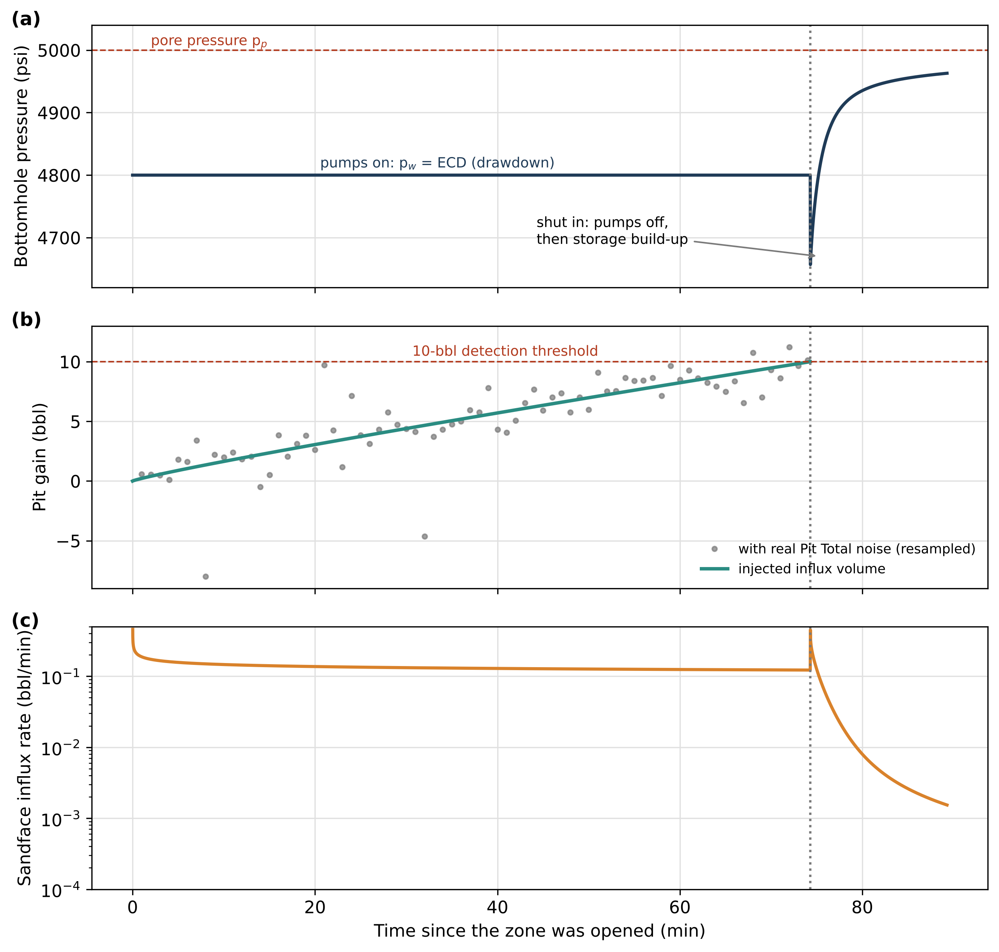

f02_composite_log.png


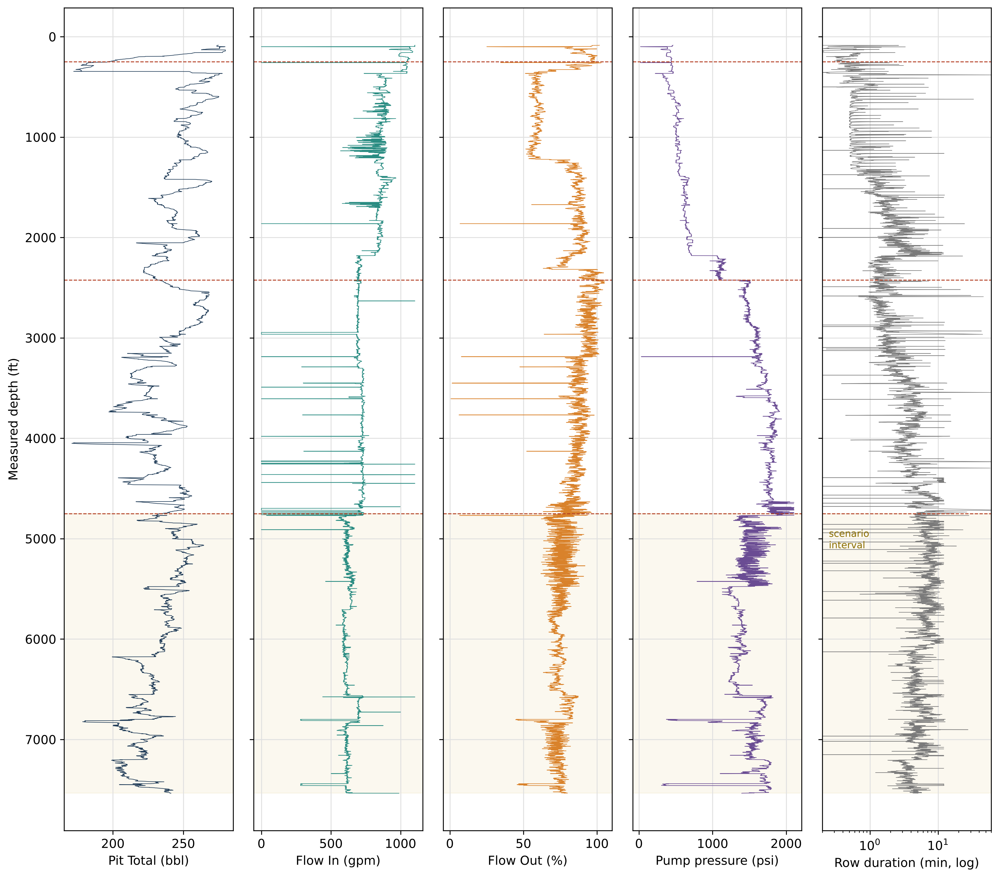

f03_noise_basis.png


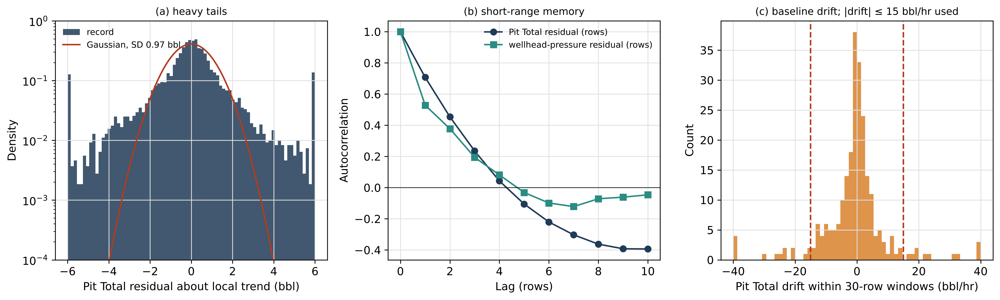

f04_hydraulics_crossplot.png


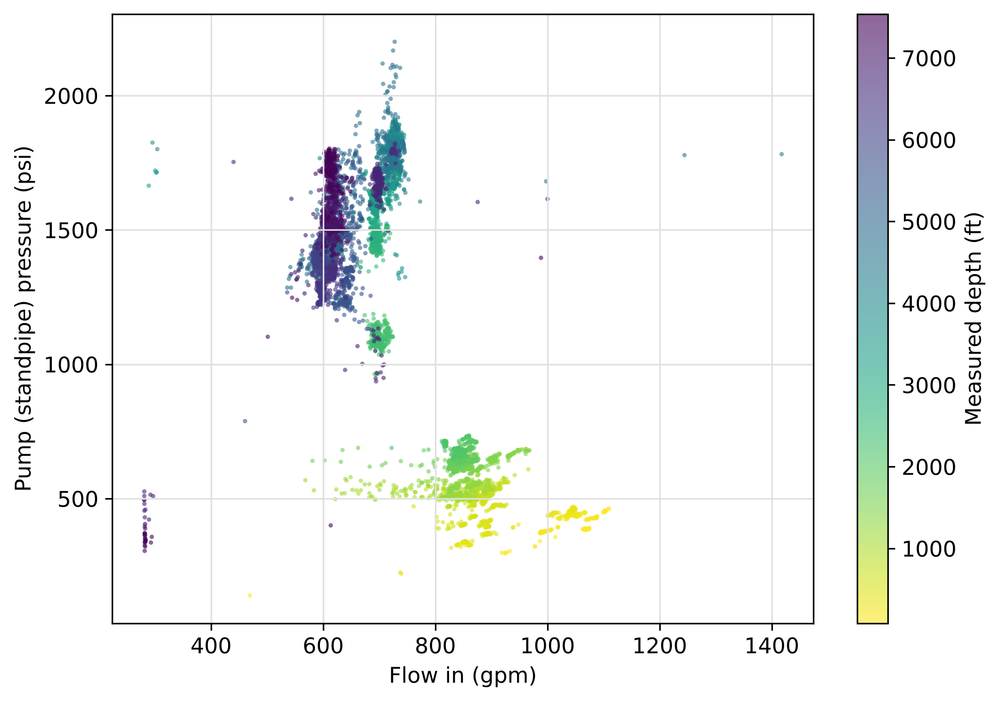

f05_schematic.png


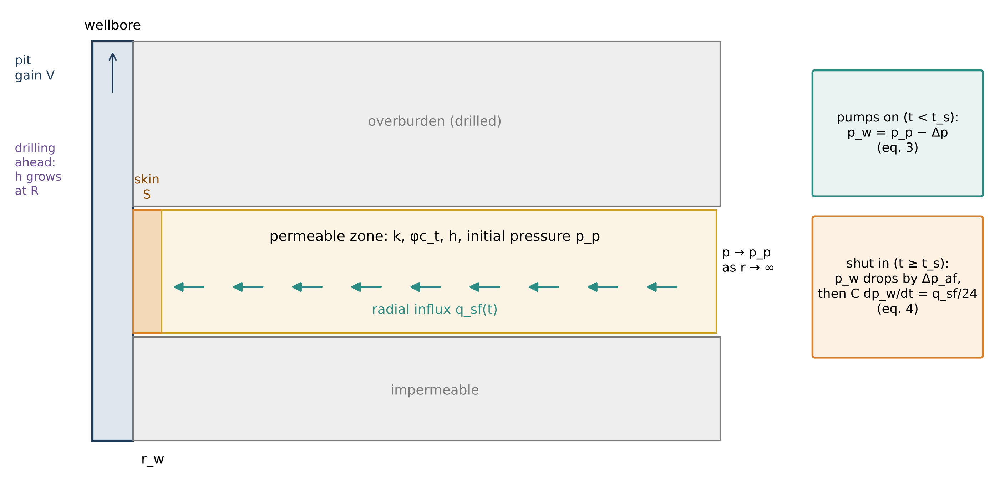

f06_verification.png


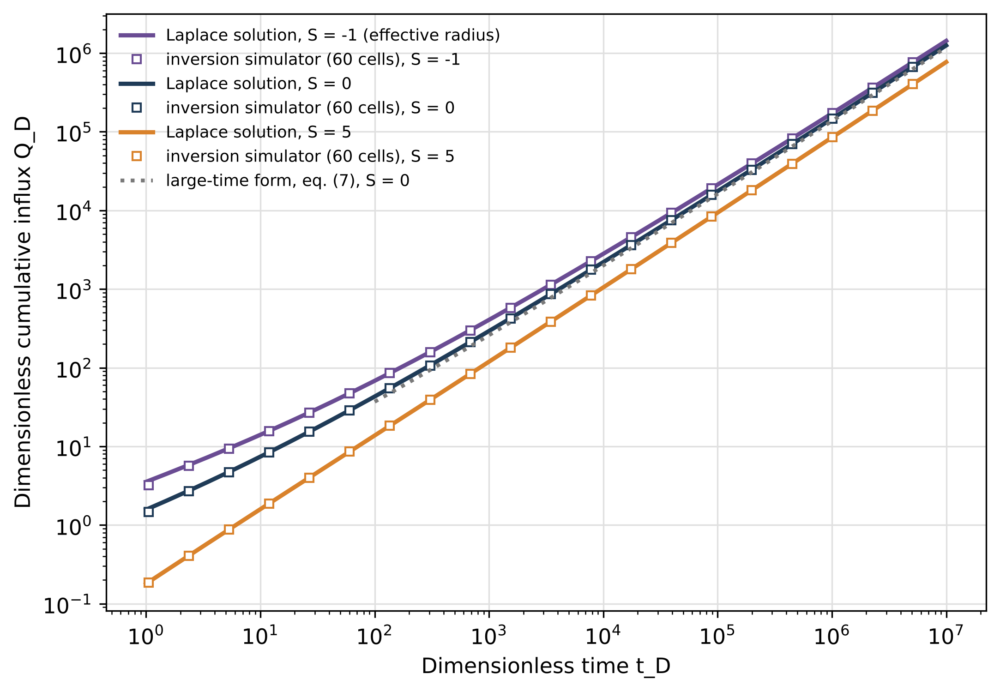

f07_drilling_ahead.png


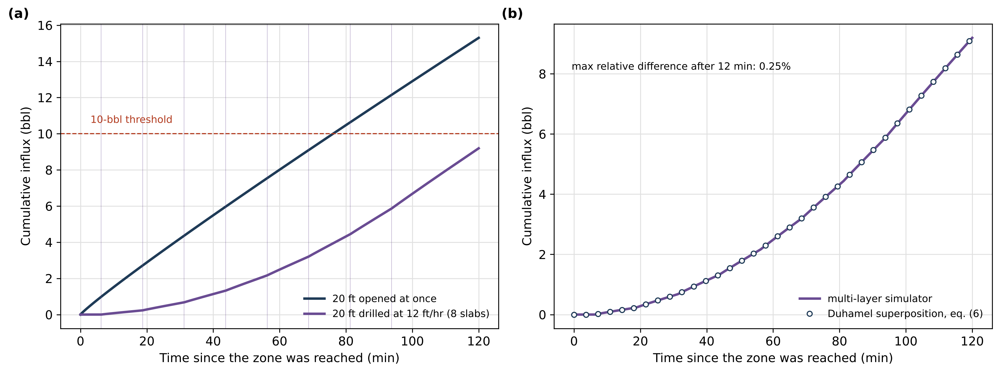

f08_scenarios.png


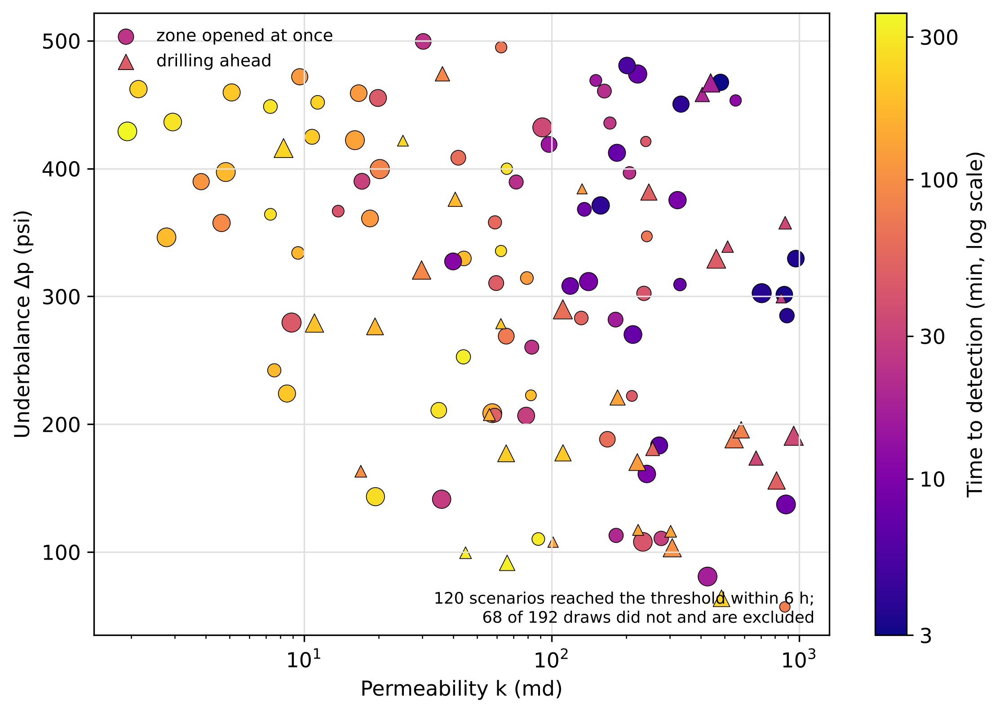

f09_workflow.png


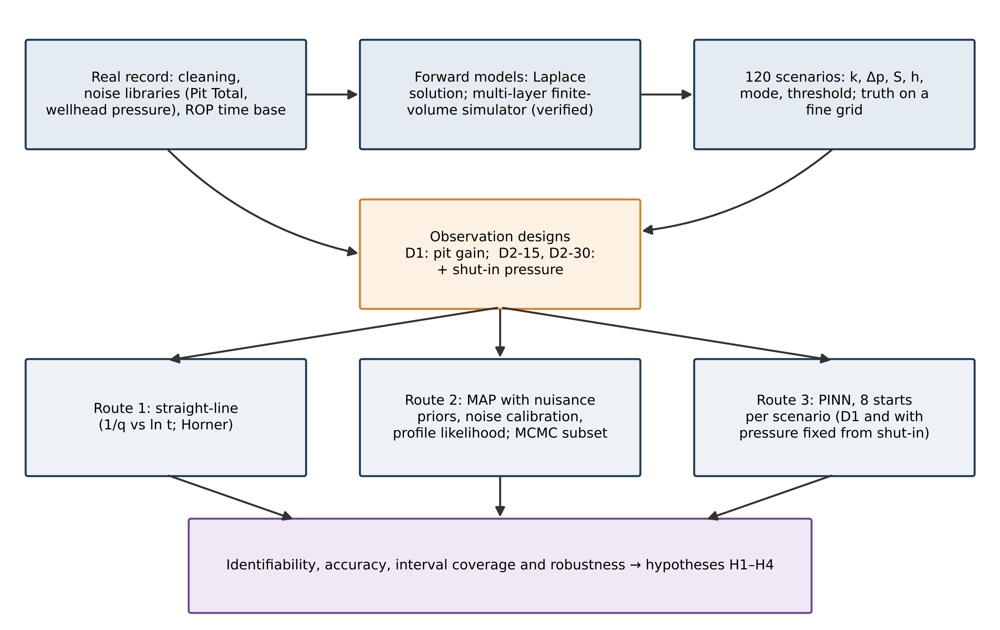

f10_pinn.png


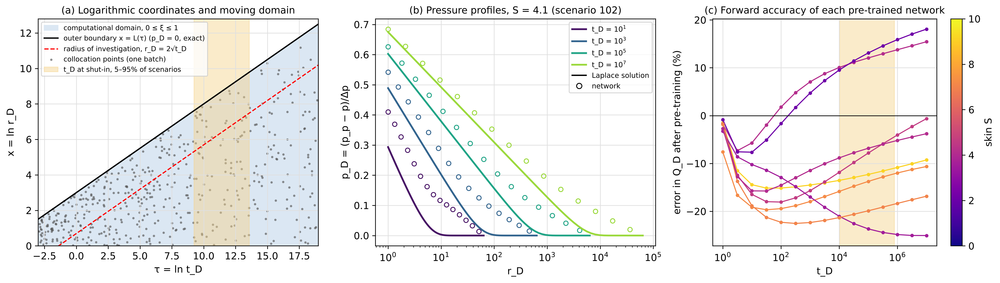

f11_example_fit.png


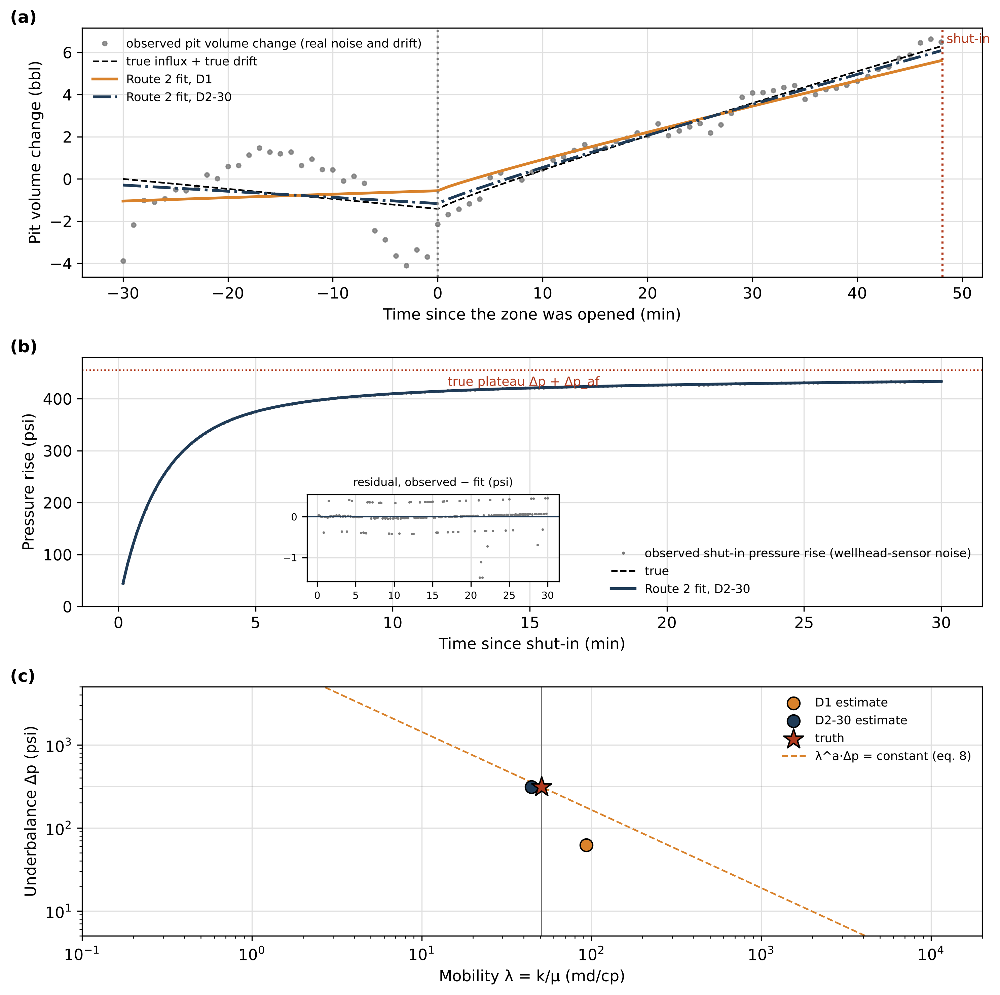

f12_horner_derivative.png


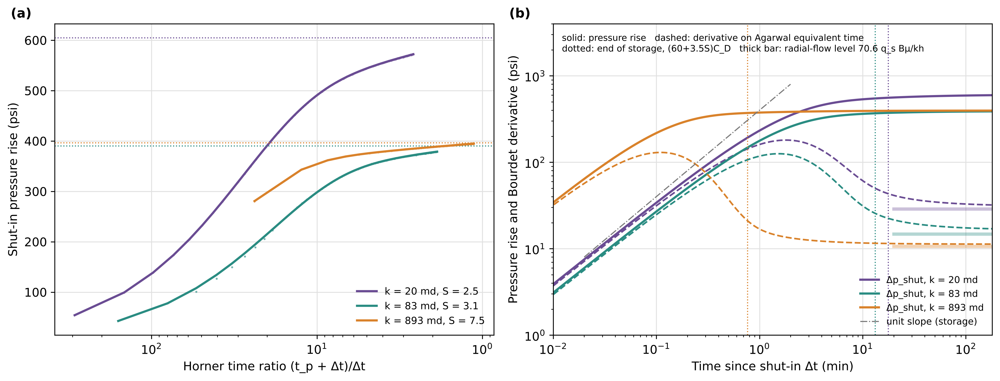

f13_profiles_example.png


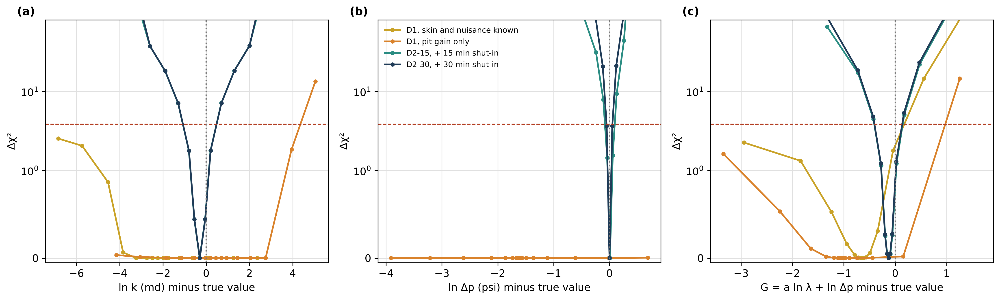

f14_exponent_check.png


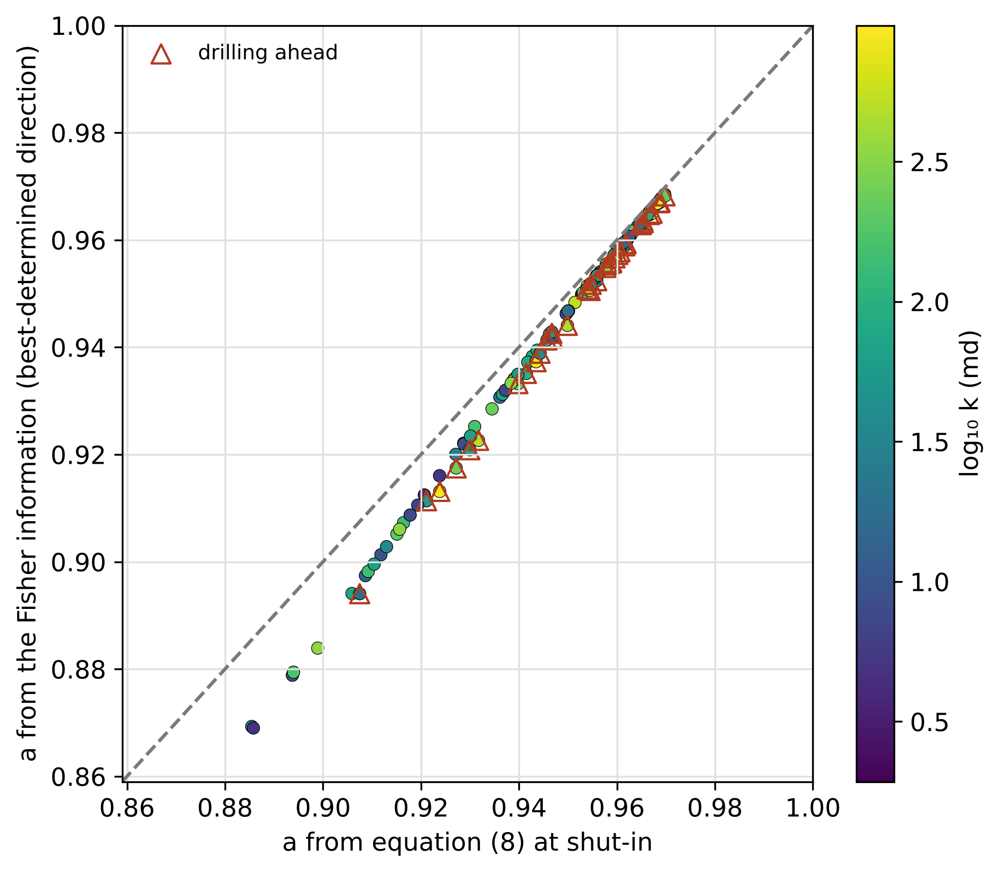

f15_identifiable_combination.png


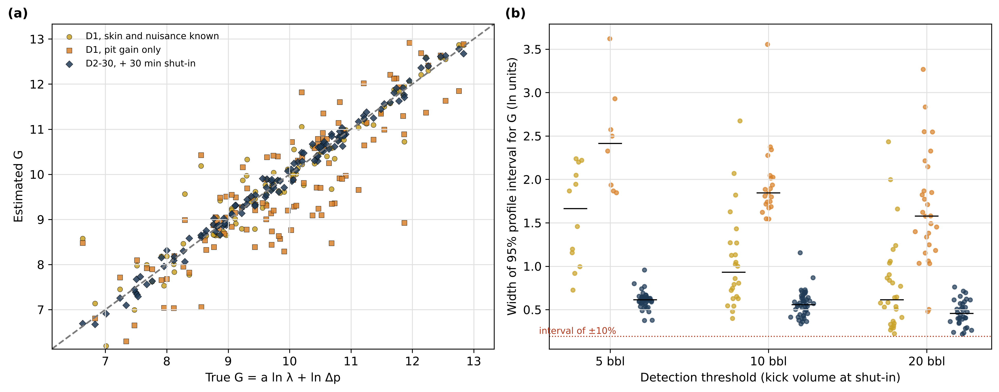

f16_permeability_recovery.png


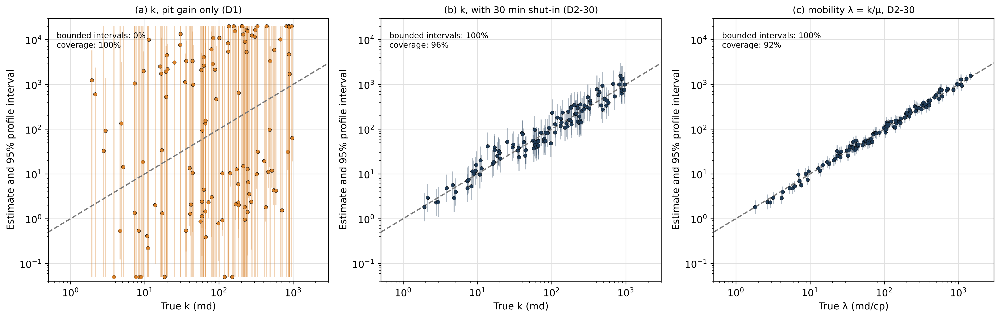

f17_underbalance_recovery.png


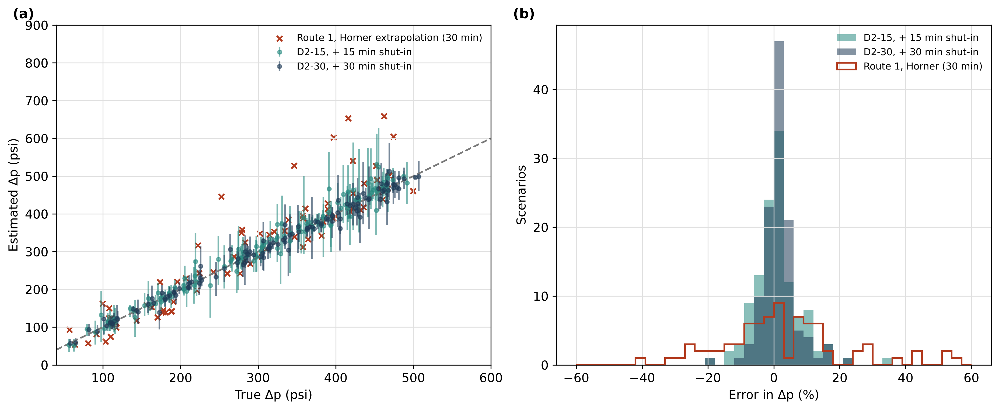

f18_interval_widths.png


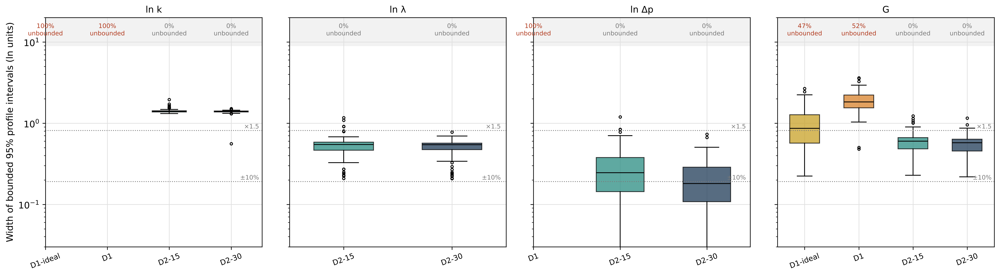

f19_coverage.png


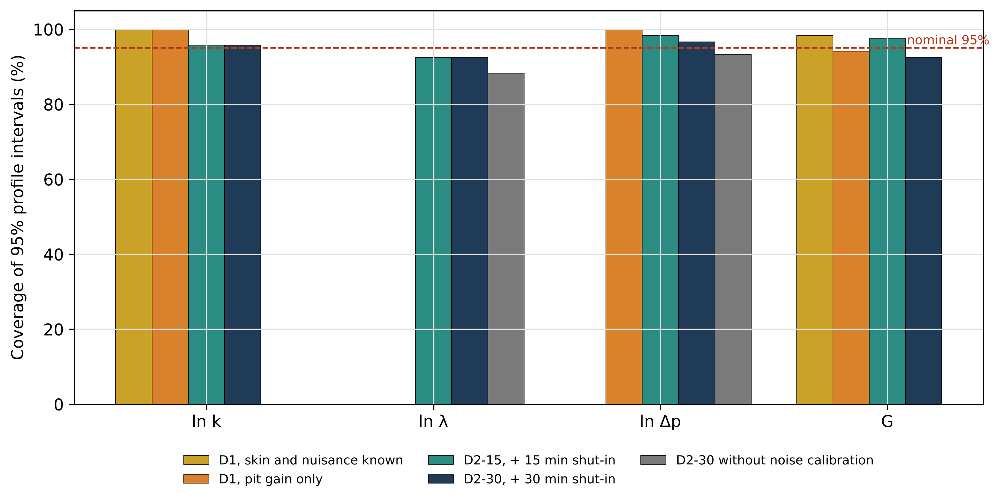

f20_route1.png


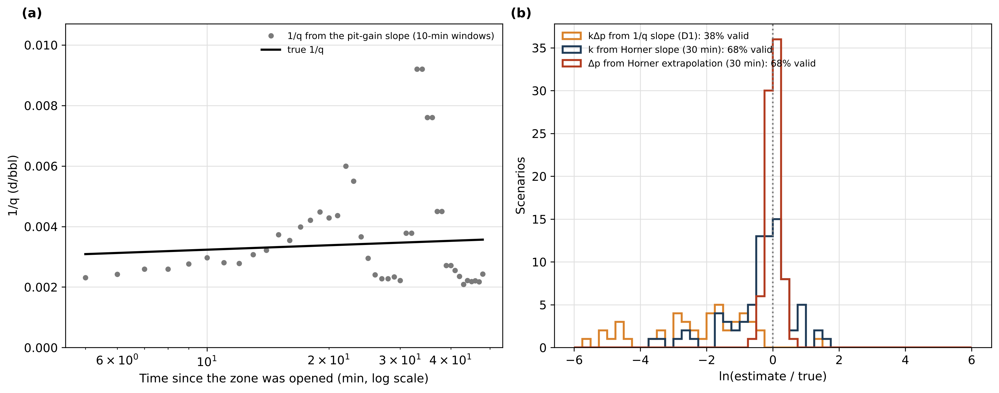

f21_posterior_check.png


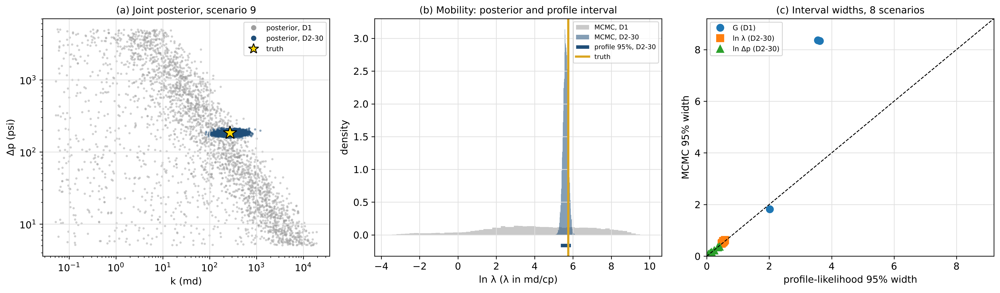

f22_pinn_ridge.png


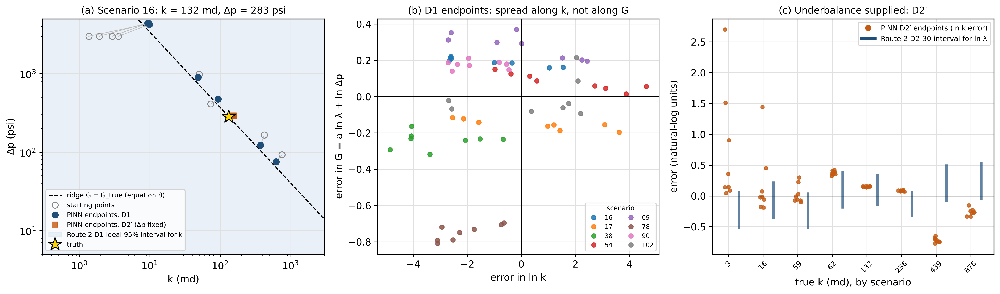

f23_pinn_training.png


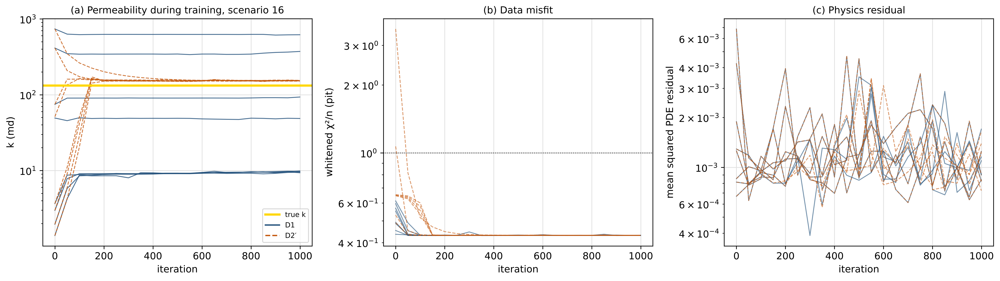

f24_shutin_duration.png


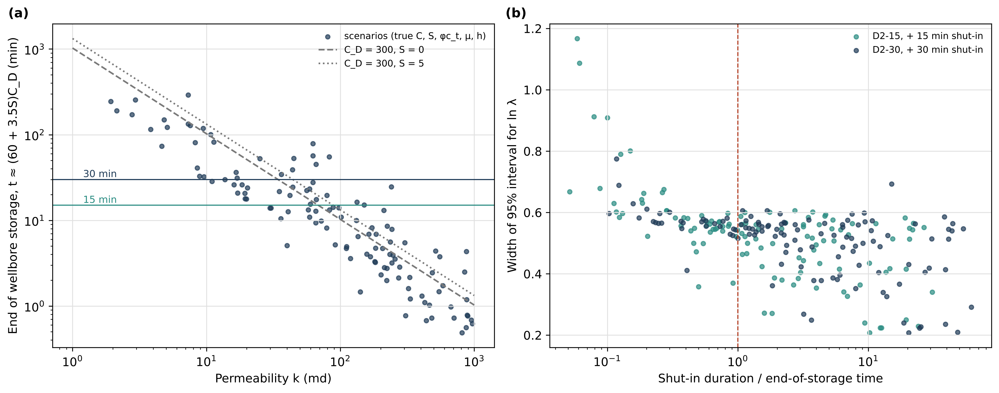

f25_robustness.png


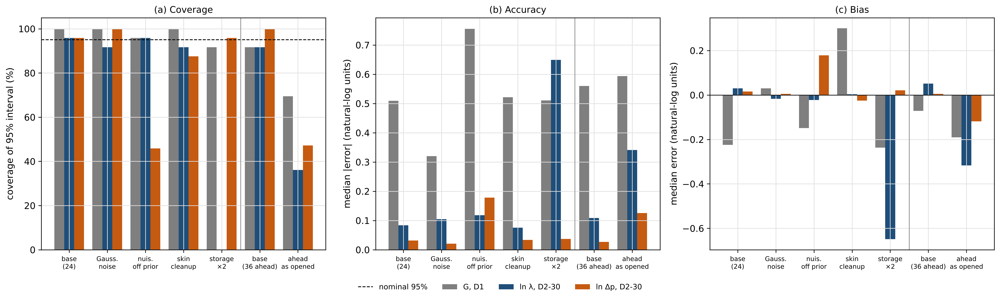

f26_skin_tradeoff.png


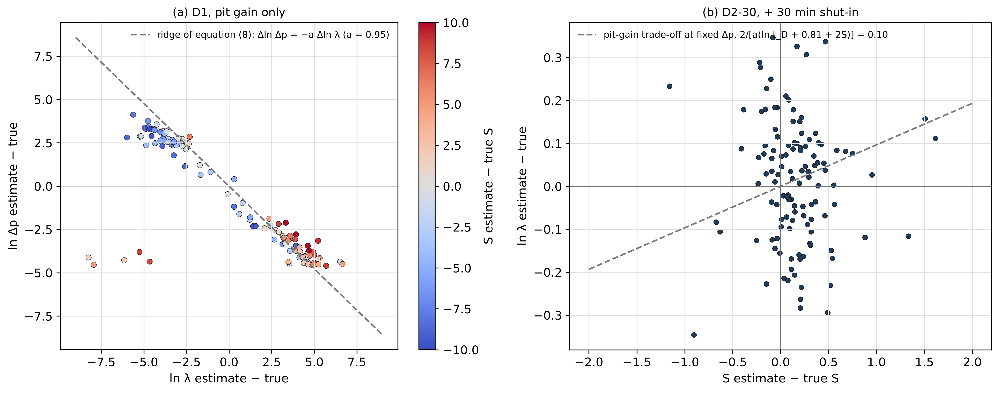

In [26]:
for s in ['prop_figs.py', 'figs_a.py', 'figs_b.py', 'figs_c.py', 'figs_d.py']:
    t0 = time.time(); r = subprocess.run([sys.executable, s], capture_output=True, text=True); print(s, 'exit', r.returncode, f'{time.time()-t0:.0f} s');
    if r.returncode: print(r.stderr[-2000:])
shutil.copy(W + 'figs/p1_unplanned_well_test.png', W + 'figs/f01_unplanned_well_test.png'); shutil.copy(W + 'figs/p2_composite_log.png', W + 'figs/f02_composite_log.png')
for f in sorted(glob.glob(W + 'figs/f*.png')):
    print(os.path.basename(f)); display(Image(filename=f, width=900))

## J. Every number quoted in the paper

`collect_numbers.py` gathers the quoted values from the result files into `paper/R.json`; the paper's text is generated from that file.

In [27]:
%%writefile collect_numbers.py
import os
# Gather every number quoted in the paper into paper/R.json, straight from the result files.
import json, pickle, sys, numpy as np, pandas as pd
CK = os.environ.get('T3_DIR', './topic3_work/')
SC = {s['id']: s for s in pickle.load(open(CK+'scenarios.pkl', 'rb'))}
D = pd.read_csv(CK+'classical_results.csv'); D['bounded'] = D['bounded'].fillna(False).astype(bool); D['covered'] = D['covered'].fillna(False).astype(bool); summ = pd.read_csv(CK+'classical_summary.csv'); r1 = pd.read_csv(CK+'route1_summary.csv')
ss = json.load(open(CK+'scenario_summary.json')); fb = json.load(open(CK+'figs_b_extra.json'))
def jl(f):
    try: return json.load(open(CK+f))
    except Exception: return {}
fc = jl('figs_c_numbers.json'); fd = jl('figs_d_numbers.json'); f7 = json.load(open(CK+'f07_check.json'))
R = {'noise': ss['noise'], 'n_draws': ss['draws'], 'n_accepted': ss['accepted'], 'n_slow': ss['too_slow'], 'n_other_rej': ss['draws']-ss['accepted']-ss['too_slow'],
     'f7': f7['drilling_ahead_superposition_maxrel'], 'f6': json.load(open(CK+'f06_check.json')), 'fb': fb, 'pinn': fc, 'mcmc': fd.get('mcmc'), 'robust': fd.get('robust'),
     'n_scen': int(D.id.nunique()), 'n_open': int(sum(s['mode'] == 'open' for s in SC.values())), 'n_ahead': int(sum(s['mode'] == 'ahead' for s in SC.values()))}
R['thr_counts'] = {str(t): int(sum(s['thr'] == t for s in SC.values())) for t in [5, 10, 20]}
R['cs'] = {}
for _, x in summ.iterrows():
    R['cs'].setdefault(x.design, {})[x.target] = dict(n=int(x.n), bounded=float(x['bounded_%']), cover=float(x['coverage_%']), mae=float(x.median_abs_err),
                                                      width=(None if pd.isna(x.median_width) else float(x.median_width)), w15=float(x['within_factor_1.5_%']), w10=float(x['within_10%_%']))
R['r1'] = {}
for _, x in r1.iterrows():
    R['r1'].setdefault(x.design, {})[x.target] = dict(n=int(x.n), valid=float(x['valid_%']), mae=(None if pd.isna(x.median_abs_err) else float(x.median_abs_err)),
                                                      w15=float(x['within_factor_1.5_%']), w10=float(x['within_factor_10_%']))
# Horner Delta-p accuracy among valid fits, as percentage error
h = D[(D.design == 'R1-30') & (D.target == 'lndp_horner')].dropna(subset=['est'])
R['horner30_dp_med_pct'] = float(100*np.median(np.abs(np.exp(h.err)-1))); R['horner30_dp_within10'] = float(100*np.mean(np.abs(np.exp(h.err)-1) < 0.10))
hk = D[(D.design == 'R1-30') & (D.target == 'lnk_horner')].dropna(subset=['est']); R['horner30_k_bias'] = float(np.median(hk.err))
g2 = D[(D.design == 'D2-30') & (D.target == 'lndp')]; R['d230_dp_med_pct'] = float(100*np.median(np.abs(np.exp(g2.err)-1))); R['d230_dp_within10'] = float(100*np.mean(np.abs(np.exp(g2.err)-1) < 0.10))
g215 = D[(D.design == 'D2-15') & (D.target == 'lndp')]; R['d215_dp_med_pct'] = float(100*np.median(np.abs(np.exp(g215.err)-1)))
# D1: estimates at the bounds
cl = {i: json.load(open(CK+f'classical/s{i:03d}.json')) for i in SC}
from invert import LB, UB
atb = [np.any(np.isclose(np.array(cl[i]['D1']['map'])[:2], LB[:2], atol=0.05) | np.isclose(np.array(cl[i]['D1']['map'])[:2], UB[:2], atol=0.05)) for i in SC]
R['d1_at_bound_pct'] = float(100*np.mean(atb))
atb_i = [np.any(np.isclose(np.array(cl[i]['D1-ideal']['map'])[:2], LB[:2], atol=0.05) | np.isclose(np.array(cl[i]['D1-ideal']['map'])[:2], UB[:2], atol=0.05)) for i in SC]
R['d1i_at_bound_pct'] = float(100*np.mean(atb_i))
# G interval width by threshold
R['G_width_thr'] = {}
for d in ['D1-ideal', 'D1', 'D2-30']:
    g = D[(D.design == d) & (D.target == 'lnG')]
    R['G_width_thr'][d] = {str(t): (float(g[(g.thr == t) & g.bounded].width.median()) if ((g.thr == t) & g.bounded).any() else None) for t in [5, 10, 20]}
    R['G_width_thr'][d + '_bounded'] = {str(t): float(100*g[g.thr == t].bounded.mean()) for t in [5, 10, 20]}
# open versus drilling ahead
R['mode'] = {}
for d, t in [('D1-ideal', 'lnG'), ('D2-30', 'lnlam'), ('D2-30', 'lndp'), ('D1', 'lnG')]:
    for m in ['open', 'ahead']:
        g = D[(D.design == d) & (D.target == t) & (D['mode'] == m)]
        R['mode'][f'{d}|{t}|{m}'] = dict(n=len(g), cover=float(100*g.covered.mean()), mae=float(g.err.abs().median()), width=float(g.width[g.bounded].median()) if g.bounded.any() else None)
# mobility accuracy by permeability tercile (D2-30)
g = D[(D.design == 'D2-30') & (D.target == 'lnlam')].copy(); g['kb'] = pd.qcut(g.k, 3, labels=['low', 'mid', 'high'])
R['lam_by_k'] = {str(b): dict(kmin=float(x.k.min()), kmax=float(x.k.max()), mae=float(x.err.abs().median()), width=float(x.width.median()), cover=float(100*x.covered.mean())) for b, x in g.groupby('kb', observed=True)}
# example scenario
ex = fb['example_id']; s = SC[ex]; r = cl[ex]
def pr(d, t): p = r[d]['prof'][t]; return dict(est=p['est'], lo=p['lo'], hi=p['hi'], true=p['true'])
R['ex'] = dict(id=ex, k=s['k'], dp=s['dp'], S=s['S'], H=s['H'], thr=s['thr'], t_min=60*s['t_s'], mu=s['truth']['mu'], lam=s['k']/s['truth']['mu'], a=s['a'], dpaf=s['truth']['dpaf'],
               D1_map_k=float(np.exp(r['D1']['map'][0])), D1_map_dp=float(np.exp(r['D1']['map'][1])), D1_map_S=float(r['D1']['map'][2]),
               D1i_G=pr('D1-ideal', 'lnG'), D1_G=pr('D1', 'lnG'), D2_lam=pr('D2-30', 'lnlam'), D2_dp=pr('D2-30', 'lndp'), D2_k=pr('D2-30', 'lnk'), D215_lam=pr('D2-15', 'lnlam'),
               D2_S=float(r['D2-30']['map'][2]), r1=r['route1'])
# example scenario: fitted baselines and the D1 estimate in mobility
from invert import Problem
exs = SC[ex]; out = {}
for d in ['D1', 'D2-30']:
    pr_ = Problem(exs, d); xm_ = np.array(cl[ex][d]['map']); Vm, _ = pr_.model(xm_); rr = pr_.pit - Vm; beta, *_ = np.linalg.lstsq(pr_.X, rr, rcond=None); out[d] = float(beta[1])
R['ex'].update(D1_drift=out['D1'], D2_drift=out['D2-30'], true_drift=float(exs['drift']), D1_map_lam=float(np.exp(cl[ex]['D1']['map'][0]-cl[ex]['D1']['map'][4])),
               D2_G=pr('D2-30', 'lnG'), D1_pit_fit_V_shut=None)
# noise recalibration
nz = np.array([cl[i]['D2-30']['noise'] for i in SC]); R['recal'] = dict(sV_med=float(np.median(nz[:, 0])), sP_med=float(np.median(nz[:, 2])), sP_max=float(nz[:, 2].max()),
                                                                          sP_frac_raised=float(100*np.mean(nz[:, 2] > 0.3771)), sV_frac_raised=float(100*np.mean(nz[:, 0] > 0.9701)))

# nuisance recovery with 30 min of shut-in
nu = {'dpaf': [], 'lnC': [], 'lnmu': [], 'lnphict': []}
for i in SC:
    m = cl[i]['D2-30']['map']; t = SC[i]['truth']
    nu['dpaf'].append(m[6]-t['dpaf']); nu['lnC'].append(m[5]-np.log(t['C'])); nu['lnmu'].append(m[4]-np.log(t['mu'])); nu['lnphict'].append(m[3]-np.log(t['phict']))
R['nuis'] = {k: float(np.median(np.abs(v))) for k, v in nu.items()}; R['nuis']['dpaf_prior'] = float(np.median([abs(SC[i]['truth']['dpaf']-150) for i in SC]))
R['nuis']['lnmu_prior'] = float(np.median([abs(np.log(SC[i]['truth']['mu'])) for i in SC])); R['nuis']['lnphict_prior'] = float(np.median([abs(np.log(SC[i]['truth']['phict']/2e-6)) for i in SC]))
R['a_min'] = float(min(SC[i]['a'] for i in SC)); R['a_max'] = float(max(SC[i]['a'] for i in SC))
R['S_mae_D2'] = float(np.median([abs(cl[i]['D2-30']['map'][2]-SC[i]['S']) for i in SC])); R['S_mae_D1'] = float(np.median([abs(cl[i]['D1']['map'][2]-SC[i]['S']) for i in SC]))
# hypothesis checks
g = D[(D.design == 'D1-ideal') & (D.target == 'lnG')]; g10 = g[g.thr >= 10]
R['H1'] = dict(within10_thr10=float(100*np.mean(np.abs(g10.err) < np.log(1.1))), within10_all=float(100*np.mean(np.abs(g.err) < np.log(1.1))),
               mae_thr10=float(g10.err.abs().median()), bounded_thr10=float(100*g10.bounded.mean()))
for d in ['D2-15', 'D2-30']:
    g = D[(D.design == d) & (D.target == 'lndp')].copy(); pp = np.array([0.465*SC[i]['depth'] for i in g.id])
    dpe = np.abs(np.exp(g.est) - np.exp(g.true)); R[f'H2_{d}'] = dict(dp_abs_psi_med=float(np.median(dpe)), dp_abs_psi_p90=float(np.percentile(dpe, 90)),
        pp_pct_med=float(100*np.median(dpe/pp)), pp_within2=float(100*np.mean(dpe/pp < 0.02)),
        k_within15=float(100*np.mean(np.abs(D[(D.design == d) & (D.target == 'lnk')].err) < np.log(1.5))),
        lam_within15=float(100*np.mean(np.abs(D[(D.design == d) & (D.target == 'lnlam')].err) < np.log(1.5))))
# effect of the two-start profile (first pass kept in classical_v1)
import glob, os
if os.path.isdir(CK+'classical_v1'):
    ch = tot = kn = 0
    for i in SC:
        a = json.load(open(CK+f'classical_v1/s{i:03d}.json')); b = cl[i]
        for d in ['D1-ideal', 'D1', 'D2-15', 'D2-30', 'D2-30-nocal']:
            for t, pb in b[d]['prof'].items():
                if not b.get('reprofiled', {}).get(f'{d}|{t}'): continue
                pa = a[d]['prof'][t]; wa, wb = pa['hi']-pa['lo'], pb['hi']-pb['lo']; tot += 1
                if not (np.isfinite(wa) and np.isfinite(wb) and abs(wb/wa - 1) <= 0.10): ch += 1
                if t == 'lnk' and d in ('D2-15', 'D2-30') and np.isfinite(wa) and wa < 1.2: kn += 1
    R['reprof'] = dict(changed=ch, total=tot, k_narrow_v1=kn)
# reciprocal-rate rise over a kick: (ln tD + 0.809 + 2S) at shut-in over its value at 5 minutes
rise = []
for i in SC:
    s_ = SC[i]; tD5 = s_['tD_s']*(5/60)/s_['t_s']; rise.append((np.log(s_['tD_s']) + 0.80907 + 2*s_['S'])/(np.log(max(tD5, 1.0)) + 0.80907 + 2*s_['S']) - 1)
R['recip_rise_pct'] = [float(100*np.percentile(rise, 10)), float(100*np.percentile(rise, 90))]
R['horner_vs_route2_ratio'] = float(R['horner30_dp_med_pct']/R['d230_dp_med_pct'])
json.dump(R, open(CK+'paper/R.json', 'w'), indent=1, default=float); print('R.json written;', R['n_scen'], 'scenarios')

Writing collect_numbers.py


In [28]:
os.makedirs(W + 'paper', exist_ok=True)
%run collect_numbers.py
R = json.load(open(W + 'paper/R.json'))
summ = pd.read_csv(W + 'classical_summary.csv'); display(summ)
print(json.dumps({k: R[k] for k in ['d230_dp_med_pct', 'd230_dp_within10', 'horner30_dp_med_pct', 'nuis', 'H1', 'H2_D2-30']}, indent=1))

R.json written; 120 scenarios


,design,target,n,bounded_%,coverage_%,median_abs_err,median_width,within_factor_1.5_%,within_10%_%
0,D1,lnG,120.0,47.500,94.167,0.556,1.824,40.833,10.000
1,D1,lndp,120.0,0.000,100.000,3.071,NaN,0.833,0.000
2,D1,lnk,120.0,0.000,100.000,3.754,NaN,0.000,0.000
3,D1-ideal,lnG,120.0,53.333,98.333,0.144,0.862,77.500,37.500
4,D1-ideal,lnk,120.0,0.000,100.000,3.266,NaN,0.000,0.000
5,D2-15,lnG,120.0,100.000,97.500,0.096,0.600,100.000,49.167
6,D2-15,lndp,120.0,100.000,98.333,0.033,0.246,100.000,86.667
7,D2-15,lnk,120.0,100.000,95.833,0.296,1.404,61.667,15.833
8,D2-15,lnlam,120.0,100.000,92.500,0.098,0.546,99.167,49.167
9,D2-30,lnG,120.0,100.000,92.500,0.105,0.574,100.000,44.167


{
 "d230_dp_med_pct": 2.4225883647697954,
 "d230_dp_within10": 94.16666666666667,
 "horner30_dp_med_pct": 10.398339353812425,
 "nuis": {
  "dpaf": 6.501393425482476,
  "lnC": 0.08448099772457773,
  "lnmu": 0.23596605148449196,
  "lnphict": 0.19942063365771112,
  "dpaf_prior": 24.089852790914563,
  "lnmu_prior": 0.23596393627458973,
  "lnphict_prior": 0.20863479427140985
 },
 "H1": {
  "within10_thr10": 45.56962025316456,
  "within10_all": 37.5,
  "mae_thr10": 0.1118409436535703,
  "bounded_thr10": 65.82278481012658
 },
 "H2_D2-30": {
  "dp_abs_psi_med": 6.578440169435012,
  "dp_abs_psi_p90": 25.160464865800417,
  "pp_pct_med": 0.2324940159761005,
  "pp_within2": 99.16666666666667,
  "k_within15": 65.0,
  "lam_within15": 100.0
 }
}


## K. Export of the cleaned dataset (Data availability)

`Topic3_KickTransient_CLEANED_DATA.csv` holds one row per raw record with the cleaned channels, the reconstructed row duration and clock, and the role of the row in this study; `Topic3_KickTransient_SCENARIOS.csv` lists the 120 scenarios with their true parameters and the Route 2 estimates.

In [29]:
# Export the cleaned record, the scenario table and the scenario time series (Data and Code Availability).
import os, json, pickle, numpy as np, pandas as pd
CK = os.environ.get('T3_DIR', '/mnt/user-data/outputs/topic3_checkpoint/'); OUTD = os.environ.get('T3_EXPORT', '/mnt/user-data/outputs/')
from t3data import df, circ
SC = pickle.load(open(CK+'scenarios.pkl', 'rb'))
# ---- cleaned record with roles ----
c = df.copy(); m = circ.set_index('row_id')
c['pit_change'] = c['row_id'].map(m['pit_change']); c['dt_hr'] = c['row_id'].map(m['dt_hr']); c['t_cum_hr'] = c['row_id'].map(m['t_cum_hr'])
c['role'] = np.where(~c['is_circulating'], 'static_excluded', 'noise_library')
host = c['is_circulating'] & (c['Depth'] > 4800) & (c['Depth'] < 7300); c.loc[host, 'role'] = 'noise_library;host_interval'
hosted = {}
for s in SC:
    rid = int(circ.loc[s['i0'], 'row_id']); hosted.setdefault(rid, []).append(str(s['id']))
c['scenario_ids_hosted'] = c['row_id'].map(lambda r: ' '.join(hosted.get(r, [])))
cols = ['row_id', 'Depth', 'depth_block', 'is_circulating', 'PitTotal', 'pit_change', 'FlowIn', 'FlowIn_winsorized', 'FlowOutPct', 'PumpPress',
        'WOB', 'RPM', 'Torque', 'Hookload', 'ROP_1ft', 'ROP_1min', 'TempIn', 'TempOut', 'WHPressure', 'WHPressure_valid', 'dt_hr', 't_cum_hr', 'role', 'scenario_ids_hosted']
c[cols].to_csv(OUTD+'Topic3_KickTransient_CLEANED_DATA.csv', index=False)
# ---- scenario table with the main estimates ----
rows = []
for s in SC:
    tr = s['truth']; r = json.load(open(CK+f"classical/s{s['id']:03d}.json"))
    def P(d, t, k): p = r[d]['prof'].get(t); return (np.nan if p is None else p[k])
    rows.append(dict(scenario_id=s['id'], host_row_id=int(circ.loc[s['i0'], 'row_id']), host_depth_ft=round(s['depth'], 2), geometry=s['mode'],
        k_md=s['k'], dp_psi=s['dp'], skin=s['S'], zone_thickness_ft=s['H'], n_slabs=len(s['h']), threshold_bbl=s['thr'], t_shut_min=60*s['t_s'],
        phict_per_psi=tr['phict'], mu_cp=tr['mu'], C_bbl_per_psi=tr['C'], dpaf_psi=tr['dpaf'], drift_bbl_per_hr=s['drift'], q_shut_bbl_per_min=s['q_s'],
        tD_shut=s['tD_s'], a_exponent=s['a'],
        D230_lnlam_est=P('D2-30', 'lnlam', 'est'), D230_lnlam_lo=P('D2-30', 'lnlam', 'lo'), D230_lnlam_hi=P('D2-30', 'lnlam', 'hi'),
        D230_lndp_est=P('D2-30', 'lndp', 'est'), D230_lndp_lo=P('D2-30', 'lndp', 'lo'), D230_lndp_hi=P('D2-30', 'lndp', 'hi'),
        D230_lnk_est=P('D2-30', 'lnk', 'est'), D230_lnk_lo=P('D2-30', 'lnk', 'lo'), D230_lnk_hi=P('D2-30', 'lnk', 'hi'),
        D230_skin_map=r['D2-30']['map'][2], D215_lnlam_est=P('D2-15', 'lnlam', 'est'), D215_lndp_est=P('D2-15', 'lndp', 'est'),
        D1_G_true=P('D1', 'lnG', 'true'), D1_G_est=P('D1', 'lnG', 'est'), D1_G_lo=P('D1', 'lnG', 'lo'), D1_G_hi=P('D1', 'lnG', 'hi'),
        D1ideal_G_est=P('D1-ideal', 'lnG', 'est'), D1ideal_G_lo=P('D1-ideal', 'lnG', 'lo'), D1ideal_G_hi=P('D1-ideal', 'lnG', 'hi'),
        horner30_k_md=r['route1']['30']['k_h'], horner30_dp_psi=r['route1']['30']['dp_h'], recip_rate_kdp=r['route1']['0']['kdp']))
pd.DataFrame(rows).to_csv(OUTD+'Topic3_KickTransient_SCENARIOS.csv', index=False)
# ---- scenario time series (observed and true) ----
ts = []
for s in SC:
    for t, o, tr_ in zip(s['tm'], s['pit'], s['pit_true']): ts.append((s['id'], 'pit_volume_change_bbl', 60*t, o, tr_))
    for t, o, tr_ in zip(s['tp'], s['ysi'], s['ysi_true']): ts.append((s['id'], 'shutin_pressure_rise_psi', 60*t, o, tr_))
pd.DataFrame(ts, columns=['scenario_id', 'channel', 't_min_since_zone_opened', 'observed', 'true_signal']).to_csv(OUTD+'Topic3_KickTransient_SCENARIO_SERIES.csv', index=False)
print('exported:', len(c), 'record rows;', len(rows), 'scenarios;', len(ts), 'series rows')

exported: 7311 record rows; 120 scenarios; 37305 series rows


## L. Benchmark of the two-parameter inversion class (journal manuscript §5.6, §6.10, Figure 27)

Recent kick inversions estimate formation pressure and permeability with every other property held at an assumed value. `two_param.py` reruns the likelihood inversion with only ln k and ln Δp free, storativity, viscosity, storage and annular friction at their true values, and the skin held at zero (`TP-D1-S0` for pit gain only, `TP-D2-S0` with 30 minutes of shut-in pressure); a control holds the skin at its true value as well (`TP-D2-St`). Profile intervals of ln k and ln Δp use a finer grid of offsets, from 0.005 log units. `figs_e.py` draws Figure 27 and writes `twoparam_numbers.json`, the numbers quoted in §6.10.

With `FULL = False` the stored results are copied from `REF` and two scenarios are re-inverted live and compared with them.

In [30]:
%%writefile two_param.py
import os
# Two-parameter inversion class (permeability and pore pressure only), as in the joint kick/UBD inversions of the
# literature that invert formation pressure and permeability with every other property held fixed.
# Settings (nuisance parameters at their true values throughout, the most favourable case for the method):
#   TP-D1-S0   : pit gain only,                       skin assumed zero
#   TP-D2-S0   : pit gain + 30 min shut-in pressure,  skin assumed zero
#   TP-D2-St   : pit gain + 30 min shut-in pressure,  skin at its true value (control)
# For each: MAP of (ln k, ln dp) from four starts and profile-likelihood intervals of ln k and ln dp.
# Noise parameters are those calibrated in the main Route 2 runs (D1-ideal for D1, D2-30 for D2).
# Output: twoparam/s###.json
import pickle, json, sys, time, os, numpy as np
from invert import *
import invert
FINE = np.array([0.005, 0.01, 0.02, 0.04, 0.08, 0.15, 0.3, 0.6, 1.2, 2.3, 3.5, 4.6])
invert.OFF['lnk'] = FINE; invert.OFF['lndp'] = FINE   # finer steps: two-parameter intervals can be very narrow
CK = os.environ.get('T3_DIR', './topic3_work/'); OUT = CK + 'twoparam/'; os.makedirs(OUT, exist_ok=True)
S = pickle.load(open(CK + 'scenarios.pkl', 'rb')); part, nparts = int(sys.argv[1]), int(sys.argv[2])
only = [int(x) for x in sys.argv[3].split(',')] if len(sys.argv) > 3 else None
SETTINGS = {'TP-D1-S0': ('D1', 0.0, 'D1-ideal'), 'TP-D2-S0': ('D2-30', 0.0, 'D2-30'), 'TP-D2-St': ('D2-30', None, 'D2-30')}
for sc in sorted(S, key=lambda s: s['id']):
    if sc['id'] % nparts != part or (only and sc['id'] not in only) or os.path.exists(OUT + f"s{sc['id']:03d}.json"): continue
    t0 = time.time(); cl = json.load(open(CK + f"classical/s{sc['id']:03d}.json"))
    res = {'id': sc['id'], 'k': sc['k'], 'dp': sc['dp'], 'S': sc['S']}
    for name, (design, S_assumed, noise_from) in SETTINGS.items():
        pr = Problem(sc, design, ideal=True)
        truth = pr.th_true.copy()
        if S_assumed is not None: pr.th_true = truth.copy(); pr.th_true[2] = S_assumed   # held value used by fit()
        pr.sV, pr.rV, pr.sP, pr.rP = cl[noise_from]['noise']
        xm, cm = map_estimate(pr, kdp_guess(sc))
        prof = {t: profile(pr, xm, cm, t) for t in ['lnk', 'lndp']}
        res[name] = {'map': xm.tolist(), 'cost': float(cm), 'S_assumed': (None if S_assumed is None else S_assumed),
                     'err_lnk': float(xm[0] - truth[0]), 'err_lndp': float(xm[1] - truth[1]), 'prof': prof}
    json.dump(res, open(OUT + f"s{sc['id']:03d}.json", 'w'))
    print(f"RES|{sc['id']} done in {time.time()-t0:.1f}s", flush=True)
print('RES|DONE', flush=True)


Writing two_param.py


In [31]:
%%writefile figs_e.py
import os
# f27: the two-parameter inversion class (ln k, ln dp only; skin held at an assumed value) against Route 2.
# Writes figs/f27_two_parameter.png and twoparam_numbers.json (numbers quoted in the paper).
import json, glob, pickle, numpy as np
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.grid': True, 'grid.color': '#e0e0e0', 'savefig.dpi': 300, 'savefig.bbox': 'tight'})
CK = os.environ.get('T3_DIR', './topic3_work/'); OUT = CK + 'figs/'
TP = [json.load(open(f)) for f in sorted(glob.glob(CK + 'twoparam/s*.json'))]
CL = {r['id']: json.load(open(CK + f"classical/s{r['id']:03d}.json")) for r in TP}

def arr(name, key): return np.array([r[name][key] for r in TP])
def prof(name, tgt):
    lo = np.array([r[name]['prof'][tgt]['lo'] for r in TP]); hi = np.array([r[name]['prof'][tgt]['hi'] for r in TP])
    tr = np.array([r[name]['prof'][tgt]['true'] for r in TP]); est = np.array([r[name]['prof'][tgt]['est'] for r in TP])
    return lo, hi, tr, est
S = np.array([r['S'] for r in TP])
N = {}
for name in ['TP-D1-S0', 'TP-D2-S0', 'TP-D2-St']:
    d = {}
    for tgt, ek in [('lnk', 'err_lnk'), ('lndp', 'err_lndp')]:
        lo, hi, tr, est = prof(name, tgt); e = arr(name, ek); b = np.isfinite(lo) & np.isfinite(hi)
        d[tgt] = dict(mae=float(np.median(np.abs(e))), med=float(np.median(e)), bounded=float(100 * b.mean()),
                      cover=float(100 * np.mean((lo <= tr) & (tr <= hi))), width=float(np.median((hi - lo)[b])) if b.any() else None,
                      frac_gt_ln15=float(100 * np.mean(np.abs(e) > np.log(1.5))), frac_gt_ln2=float(100 * np.mean(np.abs(e) > np.log(2))))
    ek = arr(name, 'err_lnk'); d['slope_k_per_skin'] = float(np.polyfit(S, ek, 1)[0]); d['corr_k_skin'] = float(np.corrcoef(S, ek)[0, 1])
    N[name] = d
# Route 2 (skin and nuisance parameters estimated with priors), D2-30, for comparison
lam_e = np.array([CL[r['id']]['D2-30']['prof']['lnlam']['est'] - CL[r['id']]['D2-30']['prof']['lnlam']['true'] for r in TP])
lam_lo = np.array([CL[r['id']]['D2-30']['prof']['lnlam']['lo'] - CL[r['id']]['D2-30']['prof']['lnlam']['true'] for r in TP])
lam_hi = np.array([CL[r['id']]['D2-30']['prof']['lnlam']['hi'] - CL[r['id']]['D2-30']['prof']['lnlam']['true'] for r in TP])
N['route2_lnlam'] = dict(mae=float(np.median(np.abs(lam_e))), cover=float(100 * np.mean((lam_lo <= 0) & (lam_hi >= 0))),
                         slope_per_skin=float(np.polyfit(S, lam_e, 1)[0]), corr_skin=float(np.corrcoef(S, lam_e)[0, 1]))
e0 = arr('TP-D2-S0', 'err_lnk')
for lo_, hi_ in [(-1, 1), (1, 4), (4, 7), (7, 10.01)]:
    sel = (S >= lo_) & (S < hi_); N[f'TP-D2-S0_k_by_skin_{lo_}_{int(hi_)}'] = dict(n=int(sel.sum()), med=float(np.median(e0[sel])))
N['n'] = len(TP); N['S_range'] = [float(S.min()), float(S.max())]
json.dump(N, open(CK + 'twoparam_numbers.json', 'w'), indent=1)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.0), gridspec_kw={'width_ratios': [1.35, 1]})
# (a) error in ln k (two-parameter) or ln lambda (Route 2) against the true skin
lo, hi, tr, est = prof('TP-D2-S0', 'lnk')
ax[0].errorbar(S, e0, yerr=[e0 - (lo - tr), (hi - tr) - e0], fmt='o', ms=4.5, color='#b2182b', ecolor='#b2182b', elinewidth=1, alpha=0.85,
               label='two-parameter, skin assumed 0 (D2-30)')
eS = arr('TP-D2-St', 'err_lnk')
ax[0].plot(S, eS, 's', ms=3.5, color='#7f7f7f', alpha=0.8, label='two-parameter, skin at true value (control)')
ax[0].errorbar(S + 0.12, lam_e, yerr=[lam_e - lam_lo, lam_hi - lam_e], fmt='o', ms=4, mfc='white', color='#1f4e79', ecolor='#9ecae1', elinewidth=1,
               label='Route 2: skin and nuisances estimated (ln λ)')
xs = np.linspace(-1, 10, 50); ax[0].plot(xs, N['TP-D2-S0']['slope_k_per_skin'] * xs + np.polyval(np.polyfit(S, e0, 1), 0) - N['TP-D2-S0']['slope_k_per_skin'] * 0, '--', color='#b2182b', lw=1)
ax[0].axhline(0, color='k', lw=0.8); ax[0].set_xlabel('true skin factor S'); ax[0].set_ylabel('error in ln k (two-parameter) or ln λ (Route 2)')
ax[0].set_title('(a) Permeability error against the skin the inversion ignored', fontsize=11); ax[0].legend(fontsize=8.5, loc='lower left')
# (b) coverage of the 95% intervals
labels = ['two-param.\nD1, S = 0', 'two-param.\nD2-30, S = 0', 'two-param.\nD2-30, S true', 'Route 2\nD2-30']
covk = [N['TP-D1-S0']['lnk']['cover'], N['TP-D2-S0']['lnk']['cover'], N['TP-D2-St']['lnk']['cover'], N['route2_lnlam']['cover']]
route2_dp = CK and np.mean([(CL[r['id']]['D2-30']['prof']['lndp']['lo'] <= CL[r['id']]['D2-30']['prof']['lndp']['true'] <= CL[r['id']]['D2-30']['prof']['lndp']['hi']) for r in TP]) * 100
covd = [N['TP-D1-S0']['lndp']['cover'], N['TP-D2-S0']['lndp']['cover'], N['TP-D2-St']['lndp']['cover'], route2_dp]
N['route2_lndp_cover'] = float(route2_dp)
x = np.arange(4); w = 0.38
ax[1].bar(x - w / 2, covk, w, color=['#d9d9d9', '#b2182b', '#7f7f7f', '#1f4e79'], edgecolor='k', label='permeability (Route 2: mobility)')
ax[1].bar(x + w / 2, covd, w, color=['#d9d9d9', '#b2182b', '#7f7f7f', '#1f4e79'], edgecolor='k', hatch='//', label='underbalance')
ax[1].axhline(95, color='k', ls=':', lw=1); ax[1].text(3.45, 96.5, 'nominal 95%', fontsize=8, ha='right')
ax[1].text(0, 45, 'unbounded:\ncovers\ntrivially', ha='center', fontsize=8, color='#222222', bbox=dict(facecolor='white', edgecolor='none', alpha=0.85))
ax[1].set_xticks(x); ax[1].set_xticklabels(labels, fontsize=9); ax[1].set_ylabel('coverage of 95% profile intervals (%)'); ax[1].set_ylim(0, 108)
ax[1].set_title('(b) Do the intervals contain the truth?', fontsize=11)
from matplotlib.patches import Patch
ax[1].legend(handles=[Patch(facecolor='white', edgecolor='k', label='permeability (Route 2: mobility)'), Patch(facecolor='white', edgecolor='k', hatch='//', label='underbalance')], fontsize=8.5, loc='center', bbox_to_anchor=(0.39, 0.25))
plt.tight_layout(); plt.savefig(OUT + 'f27_two_parameter.png'); json.dump(N, open(CK + 'twoparam_numbers.json', 'w'), indent=1)
print(json.dumps(N, indent=1))


Writing figs_e.py


RES|5 done in 2.0s


RES|74 done in 0.8s
RES|DONE


4 s for 2 scenarios
5 TP-D1-S0 err ln k: live 4.4778 stored 4.4778 | err ln dp: live -4.1608 stored -4.1608
5 TP-D2-S0 err ln k: live -0.7005 stored -0.7005 | err ln dp: live 0.0911 stored 0.0911
5 TP-D2-St err ln k: live 0.0018 stored 0.0018 | err ln dp: live 0.0001 stored 0.0001
74 TP-D1-S0 err ln k: live 3.1335 stored 3.1335 | err ln dp: live -3.7645 stored -3.7645
74 TP-D2-S0 err ln k: live 1.1374 stored 1.1374 | err ln dp: live 0.0150 stored 0.0150
74 TP-D2-St err ln k: live 0.0021 stored 0.0021 | err ln dp: live 0.0000 stored 0.0000


{
 "TP-D1-S0": {
  "lnk": {
   "mae": 3.558118474445027,
   "med": 1.5432583364506338,
   "bounded": 0.0,
   "cover": 100.0,
   "width": null,
   "frac_gt_ln15": 98.33333333333333,
   "frac_gt_ln2": 97.5
  },
  "lndp": {
   "mae": 3.295866718101239,
   "med": -3.0094819576282186,
   "bounded": 0.0,
   "cover": 100.0,
   "width": null,
   "frac_gt_ln15": 99.16666666666667,
   "frac_gt_ln2": 95.83333333333334
  },
  "slope_k_per_skin": 0.09032975938127605,
  "corr_k_skin": 0.07725199488004526
 },
 "TP-D2-S0": {
  "lnk": {
   "mae": 0.5706379010270911,
   "med": -0.5561813204390997,
   "bounded": 100.0,
   "cover": 1.6666666666666667,
   "width": 0.006834138508672372,
   "frac_gt_ln15": 58.333333333333336,
   "frac_gt_ln2": 39.166666666666664
  },
  "lndp": {
   "mae": 0.0597186183030054,
   "med": 0.05828413900650231,
   "bounded": 100.0,
   "cover": 0.0,
   "width": 0.00018379169041660148,
   "frac_gt_ln15": 0.8333333333333334,
   "frac_gt_ln2": 0.0
  },
  "slope_k_per_skin": -0.0918255

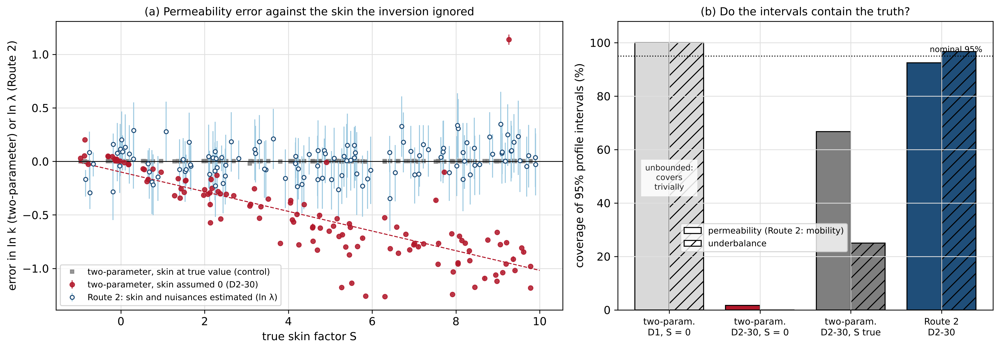

In [32]:
os.makedirs(W + 'twoparam', exist_ok=True); os.makedirs(W + 'classical', exist_ok=True)
for f in glob.glob(REF + 'classical/*.json'):                       # the Route 2 results Figure 27 compares against
    if not os.path.exists(W + 'classical/' + os.path.basename(f)): shutil.copy(f, W + 'classical/')
if FULL:
    !python two_param.py 0 1
else:
    for f in glob.glob(REF + 'twoparam/*.json'): shutil.copy(f, W + 'twoparam/')
    ids = [5, 74]; os.makedirs(W + 'twoparam_check', exist_ok=True)
    src = open('two_param.py').read().replace("OUT = CK + 'twoparam/'", "OUT = CK + 'twoparam_check/'")
    open('two_param_check.py', 'w').write(src); t0 = time.time()
    idlist = ','.join(map(str, ids))
    !python two_param_check.py 0 1 {idlist}
    print(f'{time.time()-t0:.0f} s for {len(ids)} scenarios')
    for i in ids:
        a = json.load(open(W + f'twoparam_check/s{i:03d}.json')); b = json.load(open(W + f'twoparam/s{i:03d}.json'))
        for nm in ['TP-D1-S0', 'TP-D2-S0', 'TP-D2-St']:
            print(i, nm, 'err ln k: live %.4f stored %.4f' % (a[nm]['err_lnk'], b[nm]['err_lnk']), '| err ln dp: live %.4f stored %.4f' % (a[nm]['err_lndp'], b[nm]['err_lndp']))
!python figs_e.py > /dev/null
N = json.load(open(W + 'twoparam_numbers.json'))
print(json.dumps({k: N[k] for k in ['TP-D1-S0', 'TP-D2-S0', 'TP-D2-St', 'route2_lnlam', 'route2_lndp_cover']}, indent=1))
display(Image(W + 'figs/f27_two_parameter.png', width=900))

## M. Field check: the 6506/3-1 kick (journal manuscript §7.8, Table 4)

None of the field kick records found for this study holds the shut-in pressure as a time series, so none could be inverted. The kick of Norwegian well 6506/3-1 (Norsk Chevron, 2001) can be checked against the formation-tester pretests run later across the same zone. The values below are typed from the operator's end-of-well report (Norsk Chevron AS, 2002; Norwegian Offshore Directorate wellbore documents, https://factpages.sodir.no/pbl/wellbore_documents/4344_6506_3_1__COMPLETION_REPORT.pdf): the MDT pretest summary (its Table 3.7.7-1) and the well-control narrative.

In [33]:
# Field check of Section 7.8: the 6506/3-1 kick against the formation-tester pretests around it.
# Source: Norsk Chevron AS (2002), End of Well Report, Well 6506/3-1, PL259 (Norwegian Offshore Directorate wellbore documents):
# MDT pretest summary (Table 3.7.7-1) and the well-control narrative (Section 4).
import numpy as np, pandas as pd
G = 0.0980665                                       # bar per (sg x m)
mdt = pd.DataFrame([(1662.45, 1659.42, 1.95, 249.83, 'slightly supercharged'), (1673.18, 1670.12, 119.32, 250.41, 'good'),
                    (1678.67, 1675.60, 22.77, 250.95, 'good'), (1686.30, 1683.21, 11.72, 251.71, 'good'),
                    (1690.14, 1687.03, 91.81, 252.08, 'good'), (1710.15, 1706.98, 3.70, 254.29, 'good'),
                    (1724.18, 1720.97, 6.01, 255.58, 'good'), (1732.26, 1729.03, 2.24, 257.22, 'slightly supercharged')],
                   columns=['MD_m', 'TVD_m', 'mobility_md_cp', 'p_bar', 'quality'])
mdt['EMW_sg'] = mdt.p_bar/(G*mdt.TVD_m)
print(mdt.round(3).to_string(index=False))
TVD, MUD = 1695.0, 1.50                             # kick at 1,698 m MD on a connection, 1.50 sg oil-based mud
p_kick = np.interp(TVD, mdt.TVD_m, mdt.p_bar)       # tester pressure interpolated to the kick depth
p_mud = MUD*G*TVD; dp = p_kick - p_mud
print(f'\nkick depth: tester pressure {p_kick:.1f} bar ({p_kick/(G*TVD):.3f} sg); 1.50 sg mud column {p_mud:.1f} bar; static underbalance {dp:.1f} bar ({dp*14.5038:.0f} psi)')
for lab, sidp in [('SIDPP 14 bar (report summary)', 14.0), ('SIDPP 300 psi after bumping the float (narrative)', 300/14.5038)]:
    pp = p_mud + sidp
    print(f'{lab}: pore pressure {pp:.1f} bar ({pp/(G*TVD):.3f} sg), {pp - p_kick:+.1f} bar against the tester, {sidp/dp:.1f} x the tester underbalance')
print(f'after circulating out with 1.52 sg mud, SIDP 90 psi: {(1.52*G*TVD + 90/14.5038)/(G*TVD):.3f} sg equivalent (trapped pressure)')
print(f'mobility over {mdt.TVD_m.max() - mdt.TVD_m.min():.0f} m TVD: {mdt.mobility_md_cp.min()}-{mdt.mobility_md_cp.max()} md/cp, ratio {mdt.mobility_md_cp.max()/mdt.mobility_md_cp.min():.0f}, median {mdt.mobility_md_cp.median():.1f}')

   MD_m   TVD_m  mobility_md_cp  p_bar               quality  EMW_sg
1662.45 1659.42            1.95 249.83 slightly supercharged   1.535
1673.18 1670.12          119.32 250.41                  good   1.529
1678.67 1675.60           22.77 250.95                  good   1.527
1686.30 1683.21           11.72 251.71                  good   1.525
1690.14 1687.03           91.81 252.08                  good   1.524
1710.15 1706.98            3.70 254.29                  good   1.519
1724.18 1720.97            6.01 255.58                  good   1.514
1732.26 1729.03            2.24 257.22 slightly supercharged   1.517

kick depth: tester pressure 253.0 bar (1.522 sg); 1.50 sg mud column 249.3 bar; static underbalance 3.6 bar (53 psi)
SIDPP 14 bar (report summary): pore pressure 263.3 bar (1.584 sg), +10.4 bar against the tester, 3.9 x the tester underbalance
SIDPP 300 psi after bumping the float (narrative): pore pressure 270.0 bar (1.624 sg), +17.1 bar against the tester, 5.7 x the tester 